# Projeto integrado. Gestão da base de conhecimento do atendimento da Quantum Commerce

Knowledge Management and Prompt Engineering. MBA AI Engineering & Multi-Agents.

**Integrantes do grupo.** [nomes completos, um por linha]

Este notebook é o esqueleto do trabalho. As seções seguem a ordem do enunciado. As células marcadas com `SUA VEZ` são as células do grupo. As células de análise, em markdown, vêm depois de cada medição e recebem a leitura do número e a decisão que ele motivou. O notebook precisa rodar do início ao fim, sem célula que dependa de ação manual.

---
Material desenvolvido por  
**prof. Thiago Nascimento Nogueira** (profthiago.nogueira@fiap.com.br)  
Adaptado por  
**prof. Alexandre G. L. Fernandes** (profalexandre.fernandes@fiap.com.br)  

### Como este notebook está organizado

O plano completo está em `plano-estudos.md`, na mesma pasta. Cada seção abaixo corresponde a uma etapa do plano.

| Seção do notebook | Etapa do plano | Situação |
|---|---|---|
| 0. Configuração e dados | Etapa 0 | código pronto, revisar e rodar |
| 0.6 Exploração dos dados | Etapa 1 | código pronto, revisar e rodar |
| 0.7 Infraestrutura de avaliação | Etapa 2 | código pronto, revisar e rodar |
| 1. Linha de base | Etapa 3 | feita (número a refazer e congelar com o TOP_K) |
| 1.1 Escolha do top-k | Etapa 4 | a fazer |
| 2. Melhorias (C1 a C5, variante, ablação, geração) | Etapas 5 e 6 | a fazer |
| 3. RAGAS | Etapa 7 | a fazer |
| 4. 200 chamados | Etapa 8 | a fazer |
| 5. Conclusão | Etapa 9 | a fazer |

**Decisões do experimento** (justificadas no plano): Gemini como LLM e `multilingual-e5-base` (local) como embedding, temperatura 0, top-k único para todas as configurações, trilha cumulativa C1 vigência → C2 curadoria → C3 chunking por estrutura com metadados → C4 busca híbrida → C5 re-ranking.

## 0. Configuração e dados

### 0.1 Instalação

Bibliotecas usadas no trabalho:
- `google-genai`: SDK oficial do Gemini (LLM);
- `sentence-transformers`: carrega o modelo de **embeddings** (`multilingual-e5-base`, roda local) e o de re-ranking (cross-encoder) na configuração 5;
- `rank_bm25`: busca por palavras (BM25) na configuração 4;
- `ragas` e `langchain-google-genai`: avaliação RAGAS com o Gemini como avaliador;
- `pandas` e `matplotlib`: tabelas e gráficos.

Depois que tudo funcionar, fixaremos as versões (ex.: `ragas==x.y.z`) para o notebook ser reprodutível.

In [17]:
!pip install -q google-genai sentence-transformers rank_bm25 ragas langchain-google-genai pandas matplotlib

### 0.2 Provedor do modelo: Gemini

O enunciado exige que o notebook rode do início ao fim **sem intervenção manual**. Por isso a chave da API é lida, nesta ordem:
1. dos **Secrets do Colab** (ícone de chave na barra lateral → adicionar `GOOGLE_API_KEY` → ativar o acesso ao notebook);
2. da variável de ambiente `GOOGLE_API_KEY` (quando roda localmente, no VS Code);
3. só em último caso, pede a chave com `getpass`.

O Gemini é usado só como **LLM** (e como avaliador do RAGAS). O **embedding é local** (`intfloat/multilingual-e5-base`): a primeira versão do trabalho usava o embedding do Gemini, mas o plano gratuito limita a 100 textos por minuto, o que travava a indexação e tornava o notebook frágil (o Colab desconecta). O modelo local não tem limite, não depende de rede depois do download e reproduz os mesmos vetores a cada execução. A troca foi feita **antes de qualquer medição de melhoria**, o que respeita a regra do enunciado de manter o mesmo embedding em todas as configurações.

As constantes do experimento ficam todas aqui. **Elas não mudam entre configurações** (regra do enunciado: mesmo LLM, mesmo embedding, temperatura fixa).

In [18]:
import os
from google import genai
from google.genai import types

def _chave_gemini():
    try:
        from google.colab import userdata          # Secrets do Colab
        k = userdata.get("GOOGLE_API_KEY")
        if k:
            return k
    except Exception:
        pass
    if os.environ.get("GOOGLE_API_KEY"):
        return os.environ["GOOGLE_API_KEY"]
    from getpass import getpass                    # último recurso (exige digitação)
    return getpass("Chave da API do Gemini: ")

os.environ["GOOGLE_API_KEY"] = _chave_gemini()
cliente = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])

# ---------------- Constantes do experimento (iguais em todas as configurações) ----------------
MODEL_PROVIDER    = "Gemini"
LLM_MODEL         = "gemini-3.5-flash"      # confirmar na célula seguinte e registrar
EMB_MODEL         = "intfloat/multilingual-e5-base"   # embedding LOCAL (sentence-transformers): sem API, sem limite de taxa
EMB_DIM           = 768                     # dimensão do vetor de embedding desse modelo
TEMPERATURE       = 0.0
MAX_TOKENS        = 2000
DESLIGAR_THINKING = True                    # família 2.5/3.x Flash: o "raciocínio interno" gasta tokens de saída
TOP_K             = None                    # definido na seção 1.1 (escolha do top-k)
SEED              = 42

print(f"Usando o provedor de modelo: {MODEL_PROVIDER} | LLM: {LLM_MODEL} | embedding: {EMB_MODEL} ({EMB_DIM} dim)")

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


Usando o provedor de modelo: Gemini | LLM: gemini-3.5-flash | embedding: intfloat/multilingual-e5-base (768 dim)


Confira se o modelo escolhido existe na sua conta. Se `LLM_MODEL` não aparecer na lista, troque pelo nome exato de um modelo **Flash** disponível e anote a troca.

In [19]:
disponiveis = [m.name for m in cliente.models.list()]
print("Modelos Flash:", [n for n in disponiveis if "flash" in n])
print("LLM_MODEL disponível?", any(n.endswith(LLM_MODEL) for n in disponiveis))
print("Embedding:", EMB_MODEL, "(modelo local, baixado do Hugging Face no primeiro uso)")

Modelos Flash: ['models/gemini-2.5-flash', 'models/gemini-2.5-flash-lite', 'models/gemini-2.5-flash-image', 'models/gemini-3.1-flash-lite', 'models/gemini-3.1-flash-image', 'models/gemini-3.1-flash-lite-image', 'models/gemini-3.5-flash', 'models/gemini-3.5-flash-lite', 'models/gemini-omni-flash-preview', 'models/gemini-3.6-flash', 'models/gemini-3.7-flash', 'models/gemini-3.8-flash']
LLM_MODEL disponível? True
Embedding: intfloat/multilingual-e5-base (modelo local, baixado do Hugging Face no primeiro uso)


### 0.3 Chamada ao LLM e embeddings, com cache e nova tentativa

Três ideias nesta célula:
- **Mesma interface do esqueleto.** `get_llm_response(messages, max_tokens)` recebe a lista de mensagens no formato `{"role": ..., "content": ...}`. O Gemini chama o papel do assistente de `model` e recebe o papel `system` separado; a função faz essa conversão.
- **Cache em disco** (pasta `cache/`). Cada chamada ao LLM é guardada com uma chave que combina modelo, parâmetros e texto. Rodar de novo não gasta créditos e devolve exatamente a mesma resposta, o que deixa o notebook reprodutível. Os embeddings também ficam em cache, mas como são calculados localmente, recalcular é rápido.
- **Nova tentativa com espera** quando a API do LLM recusa por limite de taxa (erro 429) ou instabilidade (503): espera crescente (1 s, 2 s, 4 s...) e, no 429, o tempo que a própria API indica.

`embed(textos, task)` transforma textos em vetores com o `multilingual-e5-base`, que roda no próprio computador (ou na GPU do Colab). Esse modelo foi treinado com prefixos: `passage: ` para os trechos da base (`RETRIEVAL_DOCUMENT`) e `query: ` para as perguntas (`RETRIEVAL_QUERY`); a função os coloca sozinha. Os vetores são normalizados (comprimento 1), então o produto escalar entre dois vetores é a similaridade por cosseno. O primeiro uso baixa o modelo (cerca de 1 GB), e a indexação da linha de base leva poucos minutos em CPU.

In [20]:
import json, hashlib, time, pathlib, re

CACHE_DIR = pathlib.Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

def _hash(*partes):
    return hashlib.sha256(json.dumps(partes, ensure_ascii=False, sort_keys=True).encode("utf-8")).hexdigest()

def _com_retry(fn, tentativas=8):
    for i in range(tentativas):
        try:
            return fn()
        except Exception as e:
            codigo = getattr(e, "code", None)
            if i == tentativas - 1 or (isinstance(codigo, int) and 400 <= codigo < 500 and codigo != 429):
                raise   # erro 4xx (exceto 429) é permanente: não adianta tentar de novo
            if codigo == 429 and re.search(r"retry in \d+h", str(e)):
                raise   # cota DIÁRIA esgotada (a API pede horas de espera): não adianta tentar de novo agora
            m = re.search(r"retry in ([\d.]+)s", str(e))     # em 429 a API diz quanto esperar (limite por minuto do plano gratuito)
            if m:
                espera = min(float(m.group(1)) + 2, 70)
            elif codigo == 503:                              # modelo sobrecarregado: esperas maiores (5, 10, 20, 40, 60...)
                espera = min(5 * 2 ** i, 60)
            else:
                espera = 2 ** i
            msg = getattr(e, "message", None) or str(e)       # só o texto do erro, sem o JSON inteiro
            print(f"  [retry {i + 1}/{tentativas - 1}] {codigo or type(e).__name__}: {msg} -> nova tentativa em {espera:.0f}s")
            time.sleep(espera)

_THINKING_OK = None   # índice da opção de thinking aceita pelo modelo (descoberta na 1ª chamada)

def get_llm_response(messages, max_tokens=MAX_TOKENS, system=None, json_mode=False):
    """Abstrai a chamada do LLM. messages = [{'role': 'user'|'assistant'|'system', 'content': str}]."""
    chave = _hash(LLM_MODEL, TEMPERATURE, max_tokens, system, json_mode, DESLIGAR_THINKING, messages)
    arq = CACHE_DIR / f"llm_{chave}.json"
    if arq.exists():
        return json.loads(arq.read_text(encoding="utf-8"))["texto"]

    contents = []
    for m in messages:
        if m["role"] == "system":
            system = (system + "\n" if system else "") + m["content"]
            continue
        role = "model" if m["role"] == "assistant" else "user"
        contents.append(types.Content(role=role, parts=[types.Part(text=m["content"])]))

    cfg = dict(
        temperature=TEMPERATURE,
        max_output_tokens=max_tokens,
        system_instruction=system,
        response_mime_type="application/json" if json_mode else "text/plain",
    )
    global _THINKING_OK
    opcoes = [None]                                   # sem thinking_config (padrão do modelo)
    if DESLIGAR_THINKING:
        opcoes = [types.ThinkingConfig(thinking_budget=0),         # família 2.5: desliga o raciocínio
                  types.ThinkingConfig(thinking_level="minimal"),  # família 3.x Flash: nível mais baixo
                  types.ThinkingConfig(thinking_level="low"),      # modelos sem "minimal"
                  None]
    if _THINKING_OK is not None:                      # já descobrimos qual opção o modelo aceita
        opcoes = [opcoes[_THINKING_OK]]

    for idx, tc in enumerate(opcoes):
        cfg_i = dict(cfg, thinking_config=tc) if tc is not None else cfg
        try:
            resp = _com_retry(lambda: cliente.models.generate_content(
                model=LLM_MODEL, contents=contents, config=types.GenerateContentConfig(**cfg_i)))
            if _THINKING_OK is None:
                _THINKING_OK = idx
                print(f"  [thinking] configuração aceita pelo modelo: {tc}")
            break
        except Exception as e:
            if _THINKING_OK is None and "hink" in str(e) and idx < len(opcoes) - 1:
                continue                              # modelo recusou essa opção de thinking: tenta a próxima
            raise
    texto = resp.text or ""
    arq.write_text(json.dumps({"texto": texto}, ensure_ascii=False), encoding="utf-8")
    return texto

In [21]:
import numpy as np
from sentence_transformers import SentenceTransformer

_modelo_emb = None
PREFIXO_EMB = {"RETRIEVAL_DOCUMENT": "passage: ", "RETRIEVAL_QUERY": "query: "}   # o e5 foi treinado com estes prefixos

def embed(textos, task="RETRIEVAL_DOCUMENT"):
    """Devolve uma matriz (len(textos) x EMB_DIM) de vetores normalizados, calculados localmente.
    task: 'RETRIEVAL_DOCUMENT' para trechos da base, 'RETRIEVAL_QUERY' para perguntas."""
    global _modelo_emb
    arq = CACHE_DIR / f"emb_{EMB_MODEL.replace('/', '_')}_{task}.json"
    cache = json.loads(arq.read_text(encoding="utf-8")) if arq.exists() else {}
    faltam = [t for t in dict.fromkeys(textos) if _hash(t) not in cache]
    if faltam:
        if _modelo_emb is None:
            _modelo_emb = SentenceTransformer(EMB_MODEL)       # usa GPU no Colab se houver
        vetores = _modelo_emb.encode([PREFIXO_EMB[task] + t for t in faltam], batch_size=32,
                                     normalize_embeddings=True, show_progress_bar=False)
        for t, v in zip(faltam, vetores):
            cache[_hash(t)] = [round(float(x), 6) for x in v]
        arq.write_text(json.dumps(cache), encoding="utf-8")
    M = np.array([cache[_hash(t)] for t in textos], dtype=np.float32)
    return M / np.linalg.norm(M, axis=1, keepdims=True)


/Users/luizpaulo/Documents/fiap-rag-trabalho-final/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 09:49:58.713000 95138 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Teste rápido das duas funções. O que esperar:
- o LLM responde (e uma segunda execução desta célula sai do cache, sem chamar a API);
- no teste de embedding, a pergunta sobre devolução deve ficar **mais próxima** da frase sobre arrependimento do que da frase sobre garantia de games.

In [86]:
print(get_llm_response([{"role": "user", "content": "Olá! Qual é o seu provedor? Responda em uma frase direta."}]))

q = embed(["tenho quantos dias para desistir da compra?"], task="RETRIEVAL_QUERY")
d = embed(["O cliente pode desistir da compra em até 7 dias corridos do recebimento.",
           "A garantia da categoria game é de 180 dias."])
print("vetor:", q.shape, "| similaridades:", np.round(q @ d.T, 3))

  [retry 1/7] 429: You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.
Please retry in 17h22m34.399242372s. -> nova tentativa em 1s
Olá! Sou um modelo de linguagem treinado pelo Google.
vetor: (1, 768) | similaridades: [[0.879 0.818]]


### 0.4 Registro da configuração experimental

O enunciado pede para registrar modelo, versão e parâmetros. Esta tabela é impressa uma vez e vale para todas as configurações.

In [23]:
import platform
from importlib.metadata import version, PackageNotFoundError

def _v(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return "não instalado"

registro = {
    "LLM": LLM_MODEL, "embedding": f"{EMB_MODEL} ({EMB_DIM} dim)", "temperatura": TEMPERATURE,
    "max_tokens": MAX_TOKENS, "thinking desligado": DESLIGAR_THINKING, "top-k": TOP_K, "seed": SEED,
    "python": platform.python_version(),
    **{f"pkg {p}": _v(p) for p in ["google-genai", "sentence-transformers", "rank-bm25", "ragas", "langchain-google-genai"]},
    "data da execução": time.strftime("%Y-%m-%d"),
}
for k, v in registro.items():
    print(f"{k:28s} {v}")

LLM                          gemini-3.5-flash
embedding                    intfloat/multilingual-e5-base (768 dim)
temperatura                  0.0
max_tokens                   2000
thinking desligado           True
top-k                        None
seed                         42
python                       3.14.0
pkg google-genai             3.6.1
pkg sentence-transformers    6.3.0
pkg rank-bm25                0.2.2
pkg ragas                    0.4.4
pkg langchain-google-genai   4.5.2
data da execução             2026-11-22


### 0.5 Dados

Célula de carga do esqueleto, sem alterações. Os dados vêm por link, para o professor conseguir rodar o notebook em qualquer máquina.

In [24]:
# Os quatro conjuntos de dados, carregados por link.
import urllib.request, zipfile, io, json, csv, os

BASE = "https://raw.githubusercontent.com/thiagonogueira/datasets/main/quantum-commerce/"
#BASE = "https://raw.githubusercontent.com/aglfern/fiap-dataset-km2026/main/"

with urllib.request.urlopen(BASE + "central-documentos.zip") as r:
    zipfile.ZipFile(io.BytesIO(r.read())).extractall(".")
manifest = json.load(open("central-documentos/manifest.json", encoding="utf-8"))
DOCS = {k: open(f"central-documentos/{k}.md", encoding="utf-8").read() for k in manifest}

def baixa_csv(nome):
    with urllib.request.urlopen(BASE + nome) as r:
        return list(csv.DictReader(io.StringIO(r.read().decode("utf-8")), delimiter=";"))

chamados = baixa_csv("chamados-200.csv")
perguntas = baixa_csv("perguntas-referencia.csv")

print(len(DOCS), "documentos.", len(chamados), "chamados.", len(perguntas), "perguntas de referência.")

44 documentos. 200 chamados. 62 perguntas de referência.


In [25]:
# Um documento, como exemplo. Título, público, estrutura e vigência vêm do manifesto.
k = "pol-dev-03"
print(manifest[k])
print(DOCS[k][:800])

{'titulo': 'Política de trocas, devoluções e ressarcimento (POL DEV 03, versão 3)', 'publico': 'cliente', 'estrutura': 'prosa_tabela', 'vigencia': '2026-07-01/9999-12-31'}
# Política de Trocas, Devoluções e Ressarcimento (POL DEV 03, versão 3)

Vigente a partir de 01/07/2026. Substitui a versão 2.

---

## Objetivo e Âmbito

Esta política estabelece as regras aplicáveis a todos os pedidos de troca, devolução e ressarcimento realizados por meio da plataforma. O documento é válido para compras efetuadas por pessoas físicas e jurídicas cadastradas como compradores ativos, independentemente da categoria de produto adquirida, do valor da compra ou da modalidade de pagamento utilizada. As regras aqui descritas se aplicam a todas as categorias de produtos disponíveis na plataforma, salvo disposição expressa em contrário indicada em política específica de categoria.

A plataforma atua como intermediadora entre comprador e vendedor e garante o cumprimento destas regr


## 0.6 Exploração dos dados (Etapa 1)

Antes de mexer no assistente, entender a base e os conjuntos de avaliação. Cada célula responde **uma** pergunta. Ao final, os achados viram hipóteses que justificam a ordem das configurações.

Documentos por público x estrutura


estrutura,comunicado,lista,passos,prosa,prosa_tabela,tabela,All
publico,,,,,,,
cliente,12,1,1,7,1,1,23
editorial,0,0,0,3,0,0,3
institucional,0,0,0,5,0,0,5
revogada,0,0,0,5,0,0,5
vendedor,0,0,0,8,0,0,8
All,12,1,1,28,1,1,44



Tamanho (caracteres) por público


,qtd,minimo,mediana,maximo,total,% dos caracteres
publico,,,,,,
cliente,23,149,190.0,18456,117258,41.8
revogada,5,12110,14353.0,18042,75604,26.9
vendedor,8,4925,5626.5,7739,47898,17.1
institucional,5,3084,7074.0,13641,37198,13.3
editorial,3,835,934.0,989,2758,1.0


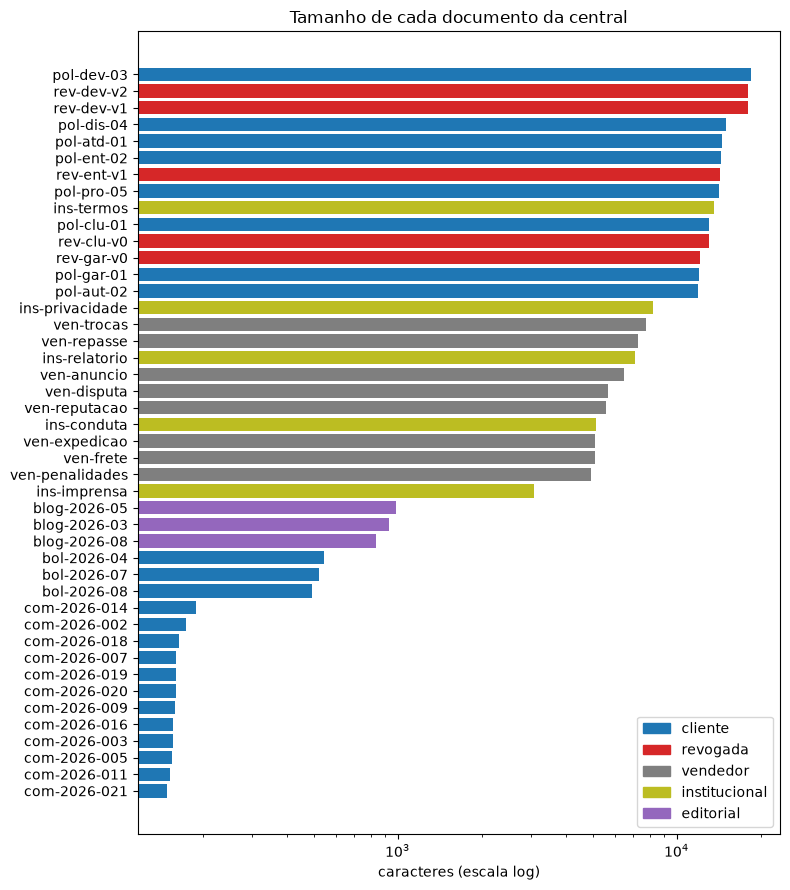

In [26]:
# ========================== SUA VEZ ==========================
# Etapa 1.1
# Manifesto como tabela: quantos documentos por público e por estrutura? Qual o tamanho de cada documento?
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)

# Manifesto como tabela, com o tamanho (em caracteres) de cada documento
man = pd.DataFrame(manifest).T
man.index.name = "doc"
man["chars"] = [len(DOCS[k]) for k in man.index]

print("Documentos por público x estrutura")
display(pd.crosstab(man["publico"], man["estrutura"], margins=True))

resumo = man.groupby("publico")["chars"].agg(qtd="count", minimo="min", mediana="median", maximo="max", total="sum")
resumo["% dos caracteres"] = (100 * resumo["total"] / resumo["total"].sum()).round(1)
print("\nTamanho (caracteres) por público")
display(resumo.sort_values("total", ascending=False))

# Tamanho de cada documento, em escala logarítmica, colorido por público
cores = {"cliente": "#1f77b4", "revogada": "#d62728", "vendedor": "#7f7f7f", "institucional": "#bcbd22", "editorial": "#9467bd"}
ordem = man.sort_values("chars")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(ordem.index, ordem["chars"], color=[cores[p] for p in ordem["publico"]])
ax.set_xscale("log")
ax.set_xlabel("caracteres (escala log)")
ax.set_title("Tamanho de cada documento da central")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()], labels=list(cores), loc="lower right")
plt.tight_layout()
plt.show()


Formatos de vigência no manifesto


publico,cliente,editorial,institucional,revogada,vendedor,All
vig_formato,,,,,,
início/ (aberta),21,0,0,0,0,21
início/9999-12-31 (aberta disfarçada),1,0,0,0,0,1
início/fim,1,0,0,5,0,6
vazia,0,3,5,0,8,16
All,23,3,5,5,8,44



Documentos cuja vigência foge do padrão:


,titulo,vigencia
doc,,
pol-dev-03,"Política de trocas, devoluções e ressarcimento (POL DEV 03, versão 3)",2026-07-01/9999-12-31


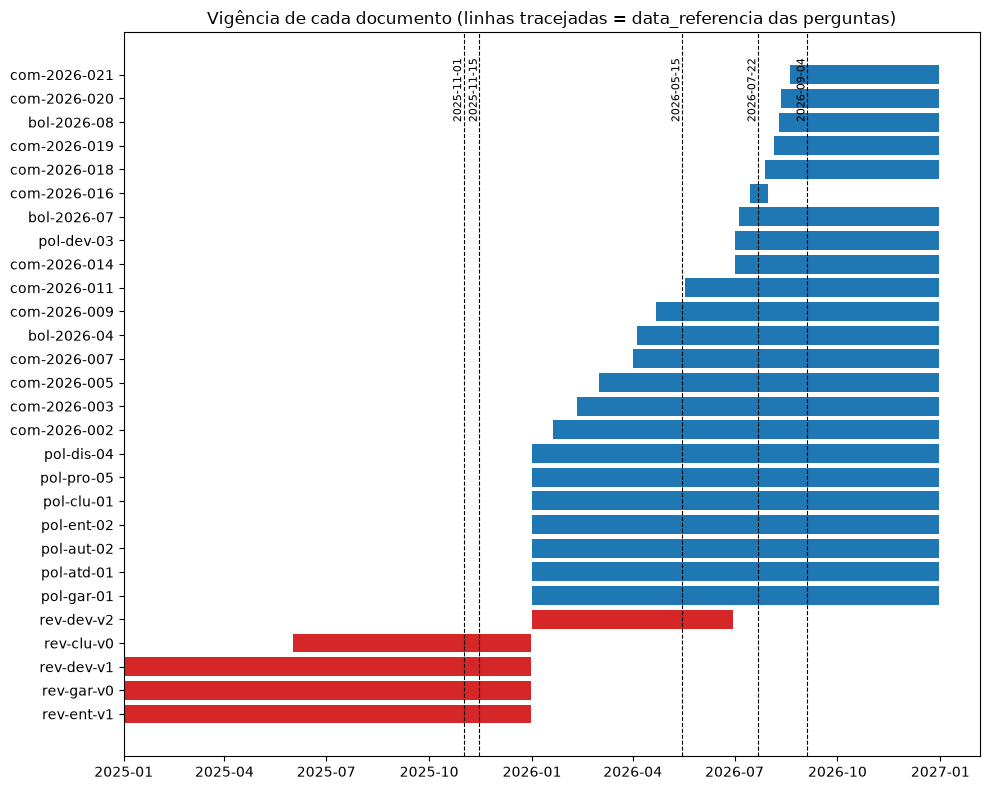

Políticas e versões vigentes em cada data de referência (pol-* e rev-*)
  2025-11-01: ['rev-gar-v0', 'rev-ent-v1', 'rev-dev-v1', 'rev-clu-v0']
  2025-11-15: ['rev-gar-v0', 'rev-ent-v1', 'rev-dev-v1', 'rev-clu-v0']
  2026-05-15: ['pol-atd-01', 'pol-ent-02', 'pol-clu-01', 'pol-pro-05', 'pol-aut-02', 'pol-dis-04', 'pol-gar-01', 'rev-dev-v2']
  2026-07-22: ['pol-atd-01', 'pol-dev-03', 'pol-ent-02', 'pol-clu-01', 'pol-pro-05', 'pol-aut-02', 'pol-dis-04', 'pol-gar-01']
  2026-09-04: ['pol-atd-01', 'pol-dev-03', 'pol-ent-02', 'pol-clu-01', 'pol-pro-05', 'pol-aut-02', 'pol-dis-04', 'pol-gar-01']

Total de documentos vigentes por data (inclui comunicados, boletins e docs sem vigência):
{'2025-11-01': 20, '2025-11-15': 20, '2026-05-15': 30, '2026-07-22': 34, '2026-09-04': 38}
Cabeçalho do texto x manifesto
  pol-atd-01  manifesto=2026-01-01/              cabeçalho=[]
  pol-dev-03  manifesto=2026-07-01/9999-12-31    cabeçalho=['Vigente a partir de 01/07/2026']
  pol-ent-02  manifesto=2026-01-01/ 

In [27]:
# ========================== SUA VEZ ==========================
# Etapa 1.2
# Linha do tempo das vigências: quais documentos valiam em cada data? Há formatos inconsistentes?
# Etapa 1.2: vigências do manifesto, normalizadas
def parse_vigencia(v):
    """Devolve (início, fim, formato). Fim aberto = NaT."""
    if not v:
        return pd.NaT, pd.NaT, "vazia"
    ini, fim = v.split("/")
    if fim == "":
        return pd.Timestamp(ini), pd.NaT, "início/ (aberta)"
    if fim.startswith("9999"):
        return pd.Timestamp(ini), pd.NaT, "início/9999-12-31 (aberta disfarçada)"
    return pd.Timestamp(ini), pd.Timestamp(fim), "início/fim"

man[["vig_ini", "vig_fim", "vig_formato"]] = [parse_vigencia(v) for v in man["vigencia"]]

print("Formatos de vigência no manifesto")
display(pd.crosstab(man["vig_formato"], man["publico"], margins=True))
print("\nDocumentos cuja vigência foge do padrão:")
display(man[man["vig_formato"].isin(["início/9999-12-31 (aberta disfarçada)"])][["titulo", "vigencia"]])

# Linha do tempo (só documentos com vigência definida)
DATAS_REF = sorted({p["data_referencia"] for p in perguntas})
FIM_GRAFICO = pd.Timestamp("2026-12-31")
t = man[man["vig_ini"].notna()].sort_values("vig_ini")
fig, ax = plt.subplots(figsize=(10, 8))
for i, (doc, r) in enumerate(t.iterrows()):
    fim = r["vig_fim"] if pd.notna(r["vig_fim"]) else FIM_GRAFICO
    ax.barh(i, (fim - r["vig_ini"]).days, left=r["vig_ini"], color=cores[r["publico"]])
ax.set_yticks(range(len(t)))
ax.set_yticklabels(t.index)
for d in DATAS_REF:
    ax.axvline(pd.Timestamp(d), color="black", ls="--", lw=0.8)
    ax.text(pd.Timestamp(d), len(t) - 0.3, d, rotation=90, va="top", ha="right", fontsize=8)
ax.set_title("Vigência de cada documento (linhas tracejadas = data_referencia das perguntas)")
plt.tight_layout()
plt.show()

def vigente_em(doc, data):
    """Vazia = sem restrição de data (regra a registrar no plano)."""
    r = man.loc[doc]
    d = pd.Timestamp(data)
    if pd.isna(r["vig_ini"]):
        return True
    return r["vig_ini"] <= d and (pd.isna(r["vig_fim"]) or d <= r["vig_fim"])

# Que políticas valiam em cada data de referência?
print("Políticas e versões vigentes em cada data de referência (pol-* e rev-*)")
for d in DATAS_REF:
    docs_ = [k for k in man.index if k.startswith(("pol-", "rev-")) and vigente_em(k, d)]
    print(f"  {d}: {docs_}")
print("\nTotal de documentos vigentes por data (inclui comunicados, boletins e docs sem vigência):")
print({d: sum(vigente_em(k, d) for k in man.index) for d in DATAS_REF})

# O texto diz a mesma coisa que o manifesto? Olhamos o cabeçalho (primeiros 600 caracteres)
# e a frase "Data de vigência" em qualquer ponto do documento.
cab = re.compile(r"(Vigente a partir de [\d/]+|vigente até [\d/]+|vigente de [\d/]+ a [\d/]+)", re.I)
dv = re.compile(r"Data de vigência[.:*\s]+([^\n]*)", re.I)
print("Cabeçalho do texto x manifesto")
for k in man.index:
    if k.startswith(("pol-", "rev-")):
        print(f"  {k:11s} manifesto={man.loc[k, 'vigencia']:24s} cabeçalho={cab.findall(DOCS[k][:600])}")
print("\nDocumentos cujo texto diz só 'Data de vigência: conforme publicação...':")
for k in man.index:
    m_ = dv.search(DOCS[k])
    if m_ and not re.search(r"\d", m_.group(1)):
        print(f"  {k:11s} {m_.group(1)[:70]}")


In [28]:
# ========================== SUA VEZ ==========================
# Etapa 1.3
# Mapa resposta → documento: em quais documentos aparece a resposta_referencia de cada pergunta?
# Etapa 1.3: mapa resposta → documento
def linhas_de_tabela(texto):
    return [l for l in texto.splitlines() if l.lstrip().startswith("|")]

linhas = []
for p in perguntas:
    resp = p["resposta_referencia"].lower()
    em = [k for k in DOCS if resp in DOCS[k].lower()]
    validos = [k for k in em if man.loc[k, "publico"] in ("cliente", "revogada") and vigente_em(k, p["data_referencia"])]
    ruido = [k for k in em if k not in validos]
    # onde a resposta aparece nos documentos válidos: em linha de tabela, em prosa, ou nos dois
    na_tabela = any(resp in l.lower() for k in validos for l in linhas_de_tabela(DOCS[k]))
    na_prosa = any(resp in l.lower() for k in validos for l in DOCS[k].splitlines() if not l.lstrip().startswith("|"))
    onde = "tabela+prosa" if na_tabela and na_prosa else "só tabela" if na_tabela else "só prosa"
    linhas.append({
        "id": p["id"], "data_ref": p["data_referencia"], "resposta": p["resposta_referencia"],
        "n_docs": len(em), "validos": validos, "so_ruido": len(validos) == 0,
        "so_revogado": bool(validos) and all(man.loc[k, "publico"] == "revogada" for k in validos),
        "so_com_bol": bool(validos) and all(k.startswith(("com-", "bol-")) for k in validos),
        "onde": onde, "docs_ruido": ruido,
    })
mapa = pd.DataFrame(linhas).set_index("id")

print("Perguntas por tipo de dependência (uma pergunta pode estar em mais de um grupo)")
print("  resposta não aparece em nenhum doc vigente de cliente/revogada:", int(mapa["so_ruido"].sum()))
print("  só em documento revogado (pergunta histórica):", int(mapa["so_revogado"].sum()), list(mapa.index[mapa["so_revogado"]]))
print("  só em comunicado ou boletim:", int(mapa["so_com_bol"].sum()), list(mapa.index[mapa["so_com_bol"]]))
print("  onde a resposta aparece nos docs válidos:", mapa["onde"].value_counts().to_dict())
print("  só em linha de tabela:", list(mapa.index[mapa["onde"] == "só tabela"]))
print("  resposta única (1 só documento no total):", int((mapa["n_docs"] == 1).sum()))
print("  resposta repetida em ≥ 5 documentos (risco de falso acerto):", int((mapa["n_docs"] >= 5).sum()), list(mapa.index[mapa["n_docs"] >= 5]))
print("  resposta que também aparece em doc de vendedor/institucional/editorial:",
      int(mapa["docs_ruido"].apply(lambda l: any(man.loc[k, "publico"] in ("vendedor", "institucional", "editorial") for k in l)).sum()))

print("\nMapa completo")
display(mapa[["data_ref", "resposta", "n_docs", "onde", "validos", "docs_ruido"]])


Perguntas por tipo de dependência (uma pergunta pode estar em mais de um grupo)
  resposta não aparece em nenhum doc vigente de cliente/revogada: 0
  só em documento revogado (pergunta histórica): 5 ['q19', 'q22', 'q47', 'q48', 'q49']
  só em comunicado ou boletim: 8 ['q21', 'q23', 'q55', 'q56', 'q57', 'q58', 'q59', 'q61']
  onde a resposta aparece nos docs válidos: {'só prosa': 31, 'tabela+prosa': 30, 'só tabela': 1}
  só em linha de tabela: ['q48']
  resposta única (1 só documento no total): 26
  resposta repetida em ≥ 5 documentos (risco de falso acerto): 11 ['q01', 'q02', 'q04', 'q09', 'q12', 'q20', 'q26', 'q35', 'q36', 'q54', 'q60']
  resposta que também aparece em doc de vendedor/institucional/editorial: 12

Mapa completo


,data_ref,resposta,n_docs,onde,validos,docs_ruido
id,,,,,,
q01,2026-09-04,retido,7,tabela+prosa,"[pol-atd-01, pol-ent-02, pol-dis-04]","[ven-repasse, ven-penalidades, rev-ent-v1, ins-privacidade]"
q02,2026-09-04,5 dias úteis,5,tabela+prosa,"[pol-dev-03, pol-ent-02, pol-aut-02]","[rev-dev-v2, rev-ent-v1]"
q03,2026-09-04,7 dias corridos,2,tabela+prosa,"[pol-dev-03, pol-gar-01]",[]
q04,2026-09-04,aceite expresso,5,só prosa,"[pol-dev-03, com-2026-019, bol-2026-08]","[rev-dev-v2, rev-dev-v1]"
q05,2026-09-04,3 dias úteis,2,tabela+prosa,"[pol-atd-01, pol-dis-04]",[]
q06,2026-09-04,cobrança é cancelada,3,só prosa,[pol-dev-03],"[rev-dev-v2, rev-dev-v1]"
q07,2026-09-04,7 dias corridos,2,tabela+prosa,"[pol-dev-03, pol-gar-01]",[]
q08,2026-09-04,sem custo,4,só prosa,"[pol-dev-03, bol-2026-07]","[rev-dev-v2, rev-dev-v1]"
q09,2026-09-04,retido,7,tabela+prosa,"[pol-atd-01, pol-ent-02, pol-dis-04]","[ven-repasse, ven-penalidades, rev-ent-v1, ins-privacidade]"


In [29]:
# ========================== SUA VEZ ==========================
# Etapa 1.4
# Perguntas por data_referencia: quantas são históricas (data diferente de 2026-09-04)?
# Etapa 1.4: perguntas por data_referencia
DATA_ATUAL = "2026-09-04"
dfp = pd.DataFrame(perguntas)
dfp["historica"] = dfp["data_referencia"] != DATA_ATUAL

print(dfp["data_referencia"].value_counts().sort_index().to_string())
print(f"\nPerguntas históricas (data diferente de {DATA_ATUAL}): {int(dfp['historica'].sum())} de {len(dfp)}")

hist = dfp[dfp["historica"]].set_index("id")
hist["docs_vigentes_com_a_resposta"] = mapa.loc[hist.index, "validos"]
hist["tambem_aparece_em"] = mapa.loc[hist.index, "docs_ruido"]
display(hist[["pergunta", "data_referencia", "resposta_referencia", "docs_vigentes_com_a_resposta", "tambem_aparece_em"]])


data_referencia
2025-11-01     2
2025-11-15     1
2026-05-15     2
2026-07-22     1
2026-09-04    56

Perguntas históricas (data diferente de 2026-09-04): 6 de 62


,pergunta,data_referencia,resposta_referencia,docs_vigentes_com_a_resposta,tambem_aparece_em
id,,,,,
q19,"em maio de 2026, qual era o teto de reembolso do plano padrão?",2026-05-15,"R$ 2.000,00",[rev-dev-v2],[com-2026-014]
q21,um pedido feito em 22/07/2026 para capital tinha qual prazo de ref...,2026-07-22,acrescidos de 2 dias úteis,[com-2026-016],[]
q22,qual era o prazo de garantia de brinquedo em novembro de 2025?,2025-11-01,30 dias,[rev-gar-v0],"[pol-gar-01, ven-repasse]"
q47,"em novembro de 2025, qual era o teto de reembolso do plano padrão?",2025-11-01,"R$ 1.500,00",[rev-dev-v1],[]
q48,"antes da versão 3 da política, qual era o prazo de reembolso acima...",2026-05-15,15 dias úteis,[rev-dev-v2],[rev-ent-v1]
q49,qual era o teto de reembolso do assinante em novembro de 2025?,2025-11-15,"R$ 5.000,00",[rev-clu-v0],[]


200 chamados, 200 ids únicos, 98 clientes distintos
Valores vazios por coluna: nenhum

classe
classe
artigo_proibido            30
falsificado                30
devolucao_ressarcimento    30
entrega                    30
fraude_vendedor            30
divergente_defeito         30
outros                     20

tipo_cliente
tipo_cliente
padrao     156
premium     44

categoria_produto
categoria_produto
game         50
outros       43
livro        37
maquiagem    36
brinquedo    34

tipo_vendedor
tipo_vendedor
vendedor        156
loja_oficial     44

Abertura de 2026-01-07 a 2026-10-20
Abertos antes de 2026-07-01 (vale a POL DEV 03 v2): 134
Abertos de 2026-07-01 em diante (vale a v3): 66
Abertos no recesso de 20 a 27/07 (com-2026-016): 8
Compra antes de 01/07 e abertura depois (caso de virada): 13
Dias entre compra e abertura: {'count': 200.0, 'mean': 25.4, 'std': 16.6, 'min': 2.0, '25%': 10.0, '50%': 23.0, '75%': 36.2, 'max': 60.0}

Faixas de preço (limites da POL DEV 03):
preco
até 100

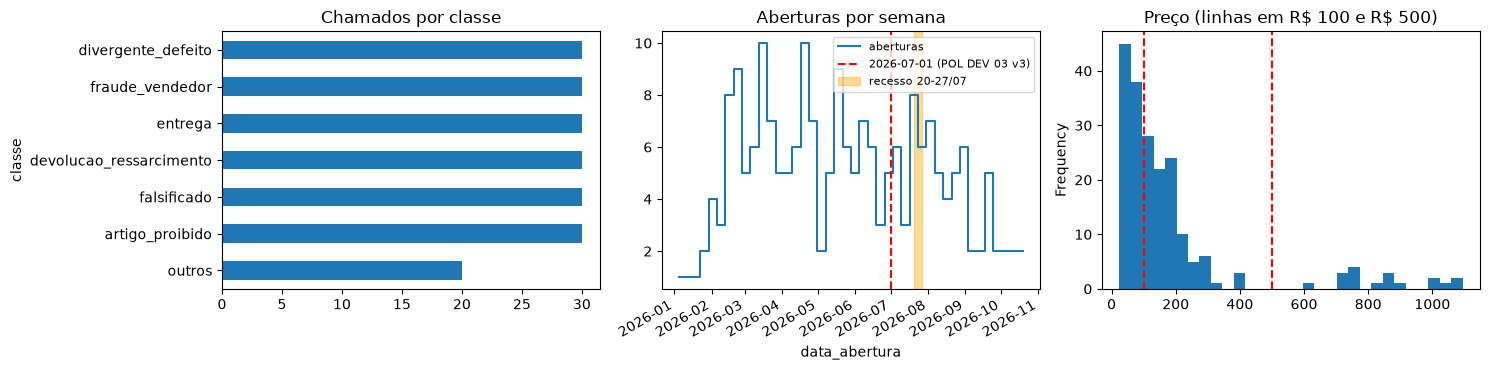

In [30]:
# ========================== SUA VEZ ==========================
# Etapa 1.5
# Chamados: distribuição de classe, tipo_cliente, categoria, datas de abertura, preços.
# Etapa 1.5: chamados
ch = pd.DataFrame(chamados)
ch["preco"] = ch["preco"].str.replace(",", ".").astype(float)
ch["avaliacao_produto"] = ch["avaliacao_produto"].str.replace(",", ".").astype(float)
for c in ["data_compra", "data_abertura"]:
    ch[c] = pd.to_datetime(ch[c])

print(f"{len(ch)} chamados, {ch['id_reclamacao'].nunique()} ids únicos, {ch['id_cliente'].nunique()} clientes distintos")
print("Valores vazios por coluna:", ch.isna().sum()[ch.isna().sum() > 0].to_dict() or "nenhum")
for col in ["classe", "tipo_cliente", "categoria_produto", "tipo_vendedor"]:
    print(f"\n{col}")
    print(ch[col].value_counts().to_string())

# Datas de corte
CORTE = pd.Timestamp("2026-07-01")
RECESSO = (pd.Timestamp("2026-07-20"), pd.Timestamp("2026-07-27"))
antes = ch["data_abertura"] < CORTE
recesso = ch["data_abertura"].between(*RECESSO)
virada = (ch["data_compra"] < CORTE) & ~antes
print(f"\nAbertura de {ch['data_abertura'].min().date()} a {ch['data_abertura'].max().date()}")
print(f"Abertos antes de 2026-07-01 (vale a POL DEV 03 v2): {int(antes.sum())}")
print(f"Abertos de 2026-07-01 em diante (vale a v3): {int((~antes).sum())}")
print(f"Abertos no recesso de 20 a 27/07 (com-2026-016): {int(recesso.sum())}")
print(f"Compra antes de 01/07 e abertura depois (caso de virada): {int(virada.sum())}")
print("Dias entre compra e abertura:", ch.assign(d=(ch['data_abertura'] - ch['data_compra']).dt.days)["d"].describe().round(1).to_dict())

# Preços
faixas = pd.cut(ch["preco"], [0, 100, 500, 2000, float("inf")], labels=["até 100", "100 a 500", "500 a 2000", "acima de 2000"], right=True)
print("\nFaixas de preço (limites da POL DEV 03):")
print(faixas.value_counts().sort_index().to_string())
print(f"Preço: mínimo {ch['preco'].min():.2f}, mediana {ch['preco'].median():.2f}, máximo {ch['preco'].max():.2f}")
print("Preço por categoria de produto (mediana):", ch.groupby("categoria_produto")["preco"].median().round(2).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ch["classe"].value_counts().sort_values().plot.barh(ax=ax[0], color="#1f77b4")
ax[0].set_title("Chamados por classe")
ch["data_abertura"].dt.to_period("W").dt.start_time.value_counts().sort_index().plot(ax=ax[1], drawstyle="steps-mid", color="#1f77b4", label="aberturas")
ax[1].axvline(CORTE, color="red", ls="--", label="2026-07-01 (POL DEV 03 v3)")
ax[1].axvspan(*RECESSO, color="orange", alpha=0.4, label="recesso 20-27/07")
ax[1].set_title("Aberturas por semana"); ax[1].legend(fontsize=8)
ch["preco"].plot.hist(bins=30, ax=ax[2], color="#1f77b4")
for lim in (100, 500):
    ax[2].axvline(lim, color="red", ls="--")
ax[2].set_title(r"Preço (linhas em R\$ 100 e R\$ 500)")
plt.tight_layout()
plt.show()


In [31]:
# ========================== SUA VEZ ==========================
# Etapa 1.5 (continuação)
# Classe do classificador x categoria informada pelo cliente; tags_sistema.
# Etapa 1.5 (continuação): classe do classificador x categoria informada pelo cliente, e tags
print("Classe (linhas) x categoria_informada_cliente (colunas)")
display(pd.crosstab(ch["classe"], ch["categoria_informada_cliente"], margins=True))

concorda = ch["classe"] == ch["categoria_informada_cliente"]
print(f"\nCliente e classificador concordam em {int(concorda.sum())} de {len(ch)} chamados ({concorda.mean():.0%}). Divergem em {int((~concorda).sum())}.")
print("Concordância por classe:", concorda.groupby(ch["classe"]).mean().round(2).to_dict())

# tags_sistema: o critério é desconhecido. Elas dizem alguma coisa sobre a classe?
tags = ch.assign(tag=ch["tags_sistema"].str.split("|")).explode("tag")
print("\nFrequência das tags:")
print(tags["tag"].value_counts().to_string())
print("\nTags por chamado:", ch["tags_sistema"].str.count(r"\|").add(1).value_counts().sort_index().to_dict())
tag_x_classe = pd.crosstab(tags["tag"], tags["classe"], normalize="index").round(2)
print("\nComposição de classes dentro de cada tag (se a tag informasse a classe, uma coluna dominaria):")
display(tag_x_classe)
print("Participação de cada classe no total, para comparar:", (ch["classe"].value_counts(normalize=True).round(2)).to_dict())


Classe (linhas) x categoria_informada_cliente (colunas)


categoria_informada_cliente,artigo_proibido,devolucao_ressarcimento,divergente_defeito,entrega,falsificado,fraude_vendedor,outros,All
classe,,,,,,,,
artigo_proibido,20,0,0,0,6,0,4,30
devolucao_ressarcimento,0,20,6,4,0,0,0,30
divergente_defeito,0,7,20,0,0,3,0,30
entrega,0,7,0,20,0,3,0,30
falsificado,0,0,5,0,20,5,0,30
fraude_vendedor,0,0,4,6,0,20,0,30
outros,0,0,5,2,0,0,13,20
All,20,34,40,32,26,31,17,200



Cliente e classificador concordam em 133 de 200 chamados (66%). Divergem em 67.
Concordância por classe: {'artigo_proibido': 0.67, 'devolucao_ressarcimento': 0.67, 'divergente_defeito': 0.67, 'entrega': 0.67, 'falsificado': 0.67, 'fraude_vendedor': 0.67, 'outros': 0.65}

Frequência das tags:
tag
pedido         78
compra         76
urgente        75
problema       73
atendimento    69
ajuda          68
produto        65
garantia       24
frete          22
pagamento      21
anuncio        21
cadastro       17
reembolso      15
devolucao      10

Tags por chamado: {2: 31, 3: 104, 4: 65}

Composição de classes dentro de cada tag (se a tag informasse a classe, uma coluna dominaria):


classe,artigo_proibido,devolucao_ressarcimento,divergente_defeito,entrega,falsificado,fraude_vendedor,outros
tag,,,,,,,
ajuda,0.12,0.18,0.16,0.15,0.13,0.15,0.12
anuncio,0.10,0.24,0.14,0.14,0.10,0.24,0.05
atendimento,0.12,0.14,0.20,0.13,0.22,0.12,0.07
cadastro,0.18,0.18,0.12,0.12,0.29,0.12,0.00
compra,0.20,0.12,0.13,0.17,0.14,0.13,0.11
devolucao,0.20,0.20,0.30,0.10,0.20,0.00,0.00
frete,0.18,0.05,0.23,0.14,0.09,0.23,0.09
garantia,0.12,0.17,0.08,0.17,0.08,0.12,0.25
pagamento,0.10,0.19,0.14,0.24,0.14,0.05,0.14


Participação de cada classe no total, para comparar: {'artigo_proibido': 0.15, 'falsificado': 0.15, 'devolucao_ressarcimento': 0.15, 'entrega': 0.15, 'fraude_vendedor': 0.15, 'divergente_defeito': 0.15, 'outros': 0.1}


In [32]:
# ========================== SUA VEZ ==========================
# Etapa 1.6
# Hipótese: cliente premium = assinante do Clube Q+?
# Etapa 1.6: hipótese "cliente premium = assinante do Clube Q+"
import re
termos = r"clube|q\+|assinante|assinatura|premium|prioritár"
ch["cita_clube"] = ch["texto_reclamacao"].str.contains(termos, case=False, regex=True)
print("Chamados por tipo de cliente")
print(ch["tipo_cliente"].value_counts().to_string())
print("\nChamados cujo texto cita Clube/assinante/premium, por tipo de cliente")
display(pd.crosstab(ch["tipo_cliente"], ch["cita_clube"]))
print("\nExemplos de premium:")
for t in ch[(ch["tipo_cliente"] == "premium") & ch["cita_clube"]]["texto_reclamacao"].head(3):
    print("  -", t[:230])
print("\nClasses dos chamados premium vs padrão (proporção):")
display(pd.crosstab(ch["tipo_cliente"], ch["classe"], normalize="index").round(2))

print("\nO que a base diz sobre o Clube Q+ e sobre 'premium':")
print("  documentos que mencionam 'premium':", [k for k in DOCS if "premium" in DOCS[k].lower()])
print("  documentos que mencionam 'Clube Q+':", [k for k in DOCS if "clube q+" in DOCS[k].lower()])
for linha in DOCS["pol-clu-01"].splitlines():
    if re.search(r"assinante|prioridade|prioritária|R\$ 8\.000|metade dos prazos|plano", linha, re.I) and len(linha) < 300:
        print("  POL CLU 01:", linha.strip()[:220])


Chamados por tipo de cliente
tipo_cliente
padrao     156
premium     44

Chamados cujo texto cita Clube/assinante/premium, por tipo de cliente


cita_clube,False
tipo_cliente,
padrao,156
premium,44



Exemplos de premium:

Classes dos chamados premium vs padrão (proporção):


classe,artigo_proibido,devolucao_ressarcimento,divergente_defeito,entrega,falsificado,fraude_vendedor,outros
tipo_cliente,,,,,,,
padrao,0.15,0.15,0.15,0.13,0.14,0.15,0.12
premium,0.14,0.16,0.14,0.20,0.18,0.16,0.02



O que a base diz sobre o Clube Q+ e sobre 'premium':
  documentos que mencionam 'premium': []
  documentos que mencionam 'Clube Q+': ['pol-dev-03', 'pol-clu-01', 'com-2026-007', 'bol-2026-04', 'rev-dev-v2', 'rev-dev-v1', 'rev-clu-v0']
  POL CLU 01: No cancelamento da assinatura, as condições de reembolso do assinante permanecem válidas até o fim do ciclo vigente já pago.
  POL CLU 01: **Assinante** é o usuário, pessoa física ou jurídica, que contratou e mantém ativa a assinatura do Clube Q+, estando em dia com todas as obrigações decorrentes do plano contratado.
  POL CLU 01: **Produto elegível** é qualquer item comercializado na plataforma que esteja devidamente sinalizado como apto a receber os benefícios do programa, conforme critérios definidos e periodicamente revisados pela equipe de op
  POL CLU 01: **Chamado** é qualquer solicitação formal registrada pelo assinante nos canais oficiais de atendimento da plataforma, sendo desconsideradas para fins desta política as manifestações

In [33]:
# ========================== SUA VEZ ==========================
# Etapa 1.7
# Os chamados da classe 'outros' têm cobertura na base? (duplicidade, nota fiscal, bivolt, boleto...)
# Etapa 1.7: os chamados 'outros' têm cobertura na base?
outros = ch[ch["classe"] == "outros"]
print(f"{len(outros)} chamados da classe 'outros'. Distribuição das categorias que o cliente informou:")
print(outros["categoria_informada_cliente"].value_counts().to_dict())

# tema do chamado (regex no texto)  ->  termos buscados na base
temas = {
    "cobrança em duplicidade":   (r"duplicidade|dois lançamentos",              r"duplicidade|cobrança duplicada|cobrado duas vezes|lançamento duplicado"),
    "nota fiscal / segunda via": (r"nota fiscal",                               r"nota fiscal|segunda via"),
    "bivolt / voltagem":         (r"bivolt",                                    r"bivolt|voltagem|110 ?v|220 ?v"),
    "trocar boleto por cartão":  (r"boleto",                                    r"boleto|alterar a forma de pagamento|trocar a forma de pagamento"),
    "cupom de primeira compra":  (r"cupom|desconto de primeira compra",         r"cupom de primeira compra|desconto de primeira|primeira compra"),
    "garantia estendida da loja":(r"garantia estendida",                        r"garantia estendida|plano de garantia"),
    "acesso à conta / código":   (r"acessar minha conta|código de verificação", r"acesso à conta|código de verificação|recuperar (a )?conta|redefinir (a )?senha"),
    "cancelar pedido por engano":(r"por erro|sem intenção",                     r"cancelar (o )?pedido|cancelamento do pedido|botão de cancelamento"),
    "alterar endereço":          (r"endereço de entrega",                       r"alterar (o )?endereço|atualizar (o )?endereço|mudança de endereço|endereço de entrega"),
    "juros no parcelamento":     (r"juros",                                     r"parcelamento|sem juros|juros"),
}
linhas = []
for tema, (rx_chamado, rx_base) in temas.items():
    n = int(outros["texto_reclamacao"].str.contains(rx_chamado, case=False, regex=True).sum())
    por_pub = {}
    for k in DOCS:
        achou = len(re.findall(rx_base, DOCS[k], flags=re.I))
        if achou:
            por_pub.setdefault(man.loc[k, "publico"], []).append(f"{k}({achou})")
    linhas.append({"tema": tema, "chamados 'outros'": n, "base cliente/revogada": por_pub.get("cliente", []) + por_pub.get("revogada", []),
                   "só vendedor/inst./editorial": sum([por_pub.get(p, []) for p in ("vendedor", "institucional", "editorial")], [])})
cobertura = pd.DataFrame(linhas).set_index("tema")
pd.set_option("display.max_colwidth", 90)
display(cobertura)
print("Soma dos chamados por tema:", int(cobertura["chamados 'outros'"].sum()), "(um chamado pode cair em dois temas; 'outros' tem 20)")

# Os temas que casaram na base de cliente: o trecho encontrado responde ao chamado, ou só usa a mesma palavra?
print("\nTrechos da base de cliente/revogada que casam com os temas (até 2 por tema):")
for tema, (_, rx_base) in temas.items():
    n = 0
    for k in DOCS:
        if man.loc[k, "publico"] in ("cliente", "revogada") and n < 2:
            for l in DOCS[k].splitlines():
                if re.search(rx_base, l, flags=re.I):
                    print(f"  [{tema}] {k}: {l.strip()[:170]}")
                    n += 1
                    break


20 chamados da classe 'outros'. Distribuição das categorias que o cliente informou:
{'outros': 13, 'divergente_defeito': 5, 'entrega': 2}


,chamados 'outros',base cliente/revogada,só vendedor/inst./editorial
tema,,,
cobrança em duplicidade,2,[],[]
nota fiscal / segunda via,2,"[pol-dev-03(1), pol-pro-05(1), rev-dev-v2(1), rev-dev-v1(1)]","[ven-disputa(4), blog-2026-05(1)]"
bivolt / voltagem,2,[],[]
trocar boleto por cartão,2,[],[]
cupom de primeira compra,2,[],[]
garantia estendida da loja,2,[],[]
acesso à conta / código,2,[pol-dis-04(1)],[]
cancelar pedido por engano,2,[],[]
alterar endereço,2,[],[]


Soma dos chamados por tema: 20 (um chamado pode cair em dois temas; 'outros' tem 20)

Trechos da base de cliente/revogada que casam com os temas (até 2 por tema):
  [nota fiscal / segunda via] pol-dev-03: Para compras acima de R$ 500,00, a análise documental pode incluir a apresentação dos seguintes documentos. - Nota fiscal do produto
  [nota fiscal / segunda via] pol-pro-05: 3.6.2. A ausência de nota fiscal de origem ou de documentação que comprove a cadeia de fornecimento é suficiente para o enquadramento na vedação de procedência não compro
  [acesso à conta / código] pol-dis-04: Caso a área de prevenção identifique indícios de uso indevido do mecanismo de disputas pelo cliente, a plataforma pode encerrar o chamado e adotar as medidas cabíveis, in


**O que a exploração mostrou.**

1. **A central tem mais ruído do que parece (célula 1.1).** Dos 44 documentos, só 23 são de público `cliente` (41,8% dos caracteres). Os 16 de vendedor, institucional e editorial somam 31,4% dos caracteres e não deveriam responder a um cliente. Os 5 revogados somam 26,9% e, ao contrário dos anteriores, **precisam ficar** (achado 3).
2. **Os documentos têm tamanhos muito diferentes (1.1).** A mediana dos documentos de cliente é 190 caracteres (os comunicados, de 149 em diante), enquanto as políticas chegam a 18 mil. Um chunk de tamanho fixo ou engole um comunicado inteiro junto com o vizinho, ou corta uma política no meio de uma tabela.
3. **Só 6 das 62 perguntas são históricas, e cinco delas dependem de documento revogado (1.3 e 1.4).** q19, q22, q47, q48 e q49 só têm a resposta vigente em `rev-*`. A q21 depende de um comunicado que valeu de 15 a 31/07 (`com-2026-016`). Em cada data de referência há uma única versão de cada política em vigor (1.2). Apagar os revogados custaria 5 perguntas.
4. **O manifesto é a fonte confiável de vigência; o texto não é (1.2).** 16 documentos não têm vigência no manifesto (vendedor, institucional, editorial). `pol-dev-03` usa fim `9999-12-31` onde as outras usam fim vazio. **`rev-dev-v1` e também `rev-dev-v2`** trazem no cabeçalho a frase copiada da v3 ("Vigente a partir de 01/07/2026"), e vários documentos dizem só "conforme publicação oficial". Quem ler o texto se confunde, então a vigência vai para o cabeçalho do chunk, vinda do manifesto.
5. **A métrica de recuperação é fácil de acertar por sorte (1.3).** 26 respostas aparecem em um único documento, mas 11 aparecem em 5 ou mais ("retido", "5 dias úteis", "conformidade"), e 12 aparecem também em documento de vendedor, institucional ou editorial. Exemplo: o "30 dias" da q22 (brinquedo, 2025) também está na linha de **livro** da POL GAR 01 atual. Por isso o diagnóstico de fonte certa (Etapa 2) é necessário.
6. **8 perguntas só se respondem por comunicado ou boletim** (q21, q23, q55 a q59, q61), documentos de uma ou duas frases, o formato mais vulnerável ao chunk fixo (1.3).
7. **Os chamados estão equilibrados, e a vigência pesa (1.5).** 30 por classe e 20 `outros`. 134 dos 200 foram abertos antes de 01/07/2026, quando valia a v2 (teto padrão R$ 2.000,00); 8 caíram no recesso de 20 a 27/07; 13 tiveram compra antes e abertura depois da virada. O preço vai de R$ 24,09 a R$ 1.095,03 (89 até R$ 100, 93 de R$ 100 a R$ 500, 18 acima de R$ 500), então a faixa do preço, a categoria e a data decidem o parâmetro correto e precisam estar na consulta.
8. **A categoria informada pelo cliente é ruído e as tags também (1.5).** Cliente e classificador concordam em 133 de 200 chamados (66%), com a mesma taxa em todas as classes (65% a 67%). As 14 tags não indicam a classe (cada uma se distribui como o total). Vale a `classe` do classificador, e `tags_sistema` fica de fora.
9. **Premium = Clube Q+ não se confirma (1.6).** Nenhum dos 44 chamados premium cita Clube, assinante ou premium, e nenhum documento da base usa a palavra "premium". A POL CLU 01 fala em "assinante". Premium também não coincide com `loja_oficial` (só 14 dos 44). Tratamos a equivalência como **suposição**, a registrar se o prompt a usar.
10. **Os 20 chamados `outros` são 10 temas, dois chamados cada, e nenhum tem cobertura na base (1.7).** Duplicidade de cobrança, nota fiscal, bivolt, boleto para cartão, cupom de primeira compra, garantia estendida, acesso à conta, cancelar pedido por engano, alterar endereço e juros no parcelamento. Os poucos achados por palavra são falsos: "nota fiscal" aparece como prova de documentação na POL DEV 03 e "acesso à conta" como punição na POL DIS 04. É o teste natural da abstenção.

**Previsão para a linha de base.** Palpite de 40 a 50 acertos em 62, com boa parte dos acertos "de graça", nas perguntas de resposta repetida (q01, q02, q09, q12, q20, q26, q35, q54, q60). Devem errar, ou acertar pela fonte errada:
- **q47 e q49**, cuja resposta só existe em revogado: a recuperação pelo significado traz os trechos de teto da política atual, que têm texto muito parecido.
- **q19 e q48**, que competem com a v3 e com `com-2026-014`, e **q22**, que pode acertar pelo "30 dias" da linha de livro.
- **q21, q23, q55 a q59 e q61**, os comunicados e boletins de uma ou duas frases, diluídos dentro de um chunk grande.
- As respostas em linha de tabela (q12, q40, q41, q13, q14, q42, q46), se o chunk separar o cabeçalho da tabela das linhas.

Se a linha de base ignora a vigência (como a equipe anterior), o ganho esperado da configuração 1 está nas históricas; o da configuração 3, nos comunicados e nas tabelas. Conferiremos na seção 1.

## 0.7 Infraestrutura de avaliação (Etapa 2)

Ferramentas usadas por todas as configurações:
- estrutura padrão de chunk (texto + metadados);
- registro `RESULTADOS` de cada medição;
- `diagnostico`: em que posição veio o trecho certo, de qual documento, e se ele estava vigente na data;
- `compara`: perguntas ganhas e perdidas entre duas configurações;
- `inspeciona`: os trechos recuperados de uma pergunta, com documento, vigência e score;
- `painel`: tabela de progresso de todas as configurações medidas até agora.

**Métricas acompanhadas em todas as configurações (nenhuma chama o LLM):**

| Métrica | O que mede |
|---|---|
| Hit@k | a célula oficial: em quantas perguntas a resposta aparece nos k trechos |
| Hit@1, Hit@3 | o mesmo, olhando só os 1 ou 3 primeiros trechos |
| MRR | média de 1/posição do primeiro trecho certo (1º = 1; 2º = 0,5; fora = 0). Mostra se o trecho certo **subiu**, mesmo quando o Hit@k não muda |
| Fonte certa | acertos cujo trecho veio de documento vigente e de público cliente |

O RAGAS, que chama o LLM, fica na seção 3 e cobre todas as configurações de uma vez, na mesma amostra.

In [34]:
# ========================== SUA VEZ ==========================
# Etapa 2
# Estrutura de chunk, RESULTADOS, mede/diagnostico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), compara, inspeciona, painel, matriz.
# Ferramentas de avaliação, usadas por todas as configurações.
# Contrato: cada configuração define um recuperador DETALHADO  det(pergunta, data) -> lista de chunks (dicts, já ordenados,
# com a chave extra "score"). A função recupera(pergunta, data) exigida pela célula oficial é derivada dele.
import random

RESULTADOS = {}
PUBLICO_OK = ("cliente", "revogada")   # públicos que podem legitimamente responder a um cliente

def novo_chunk(texto, doc_id, secao="", n=0, **extra):
    """Estrutura padrão de chunk. Os metadados vêm do manifesto (a vigência normalizada da célula 1.2)."""
    r = man.loc[doc_id]
    c = {"texto": texto, "doc_id": doc_id, "titulo": r["titulo"], "publico": r["publico"], "estrutura": r["estrutura"],
         "vig_ini": r["vig_ini"], "vig_fim": r["vig_fim"], "secao": secao, "chunk_id": f"{doc_id}#{n}"}
    c.update(extra)
    return c

def recupera_de(det):
    """Transforma o recuperador detalhado na função que a célula de medição oficial espera: devolve só os textos."""
    def recupera(pergunta, data):
        return [c["texto"] for c in det(pergunta, data)]
    return recupera

def _contem(resposta, texto):
    return resposta.lower() in texto.lower()          # mesma regra da célula oficial

def fonte_certa(chunk, data):
    """O trecho vem de documento de público cliente (ou revogado) e vigente na data da pergunta?"""
    return chunk["publico"] in PUBLICO_OK and vigente_em(chunk["doc_id"], data)

def mede(nome, det, params=None):
    """Roda as 62 perguntas, guarda tudo em RESULTADOS[nome] e imprime o resumo."""
    linhas, recuperados = [], {}
    for p in perguntas:
        cs = det(p["pergunta"], p["data_referencia"])
        recuperados[p["id"]] = cs
        pos = next((i for i, c in enumerate(cs, 1) if _contem(p["resposta_referencia"], c["texto"])), None)
        certos = [c for c in cs if _contem(p["resposta_referencia"], c["texto"])]
        linhas.append({
            "id": p["id"], "acerto": pos is not None, "posicao": pos,
            "doc_do_acerto": cs[pos - 1]["doc_id"] if pos else None,
            "fonte_certa": any(fonte_certa(c, p["data_referencia"]) for c in certos),
            "docs_com_a_resposta": sorted({c["doc_id"] for c in certos}),
        })
    df = pd.DataFrame(linhas)
    n = len(df)
    m = {
        "k": max((len(v) for v in recuperados.values()), default=0),
        "Hit@1": int((df["posicao"] == 1).sum()),
        "Hit@3": int((df["posicao"] <= 3).sum()),
        "Hit@k": int(df["acerto"].sum()),
        "MRR": float((1 / df["posicao"]).fillna(0).mean()),
        "fonte certa": int(df["fonte_certa"].sum()),
    }
    RESULTADOS[nome] = {"acertos": m["Hit@k"], "erradas": list(df["id"][~df["acerto"]]), "params": params or {},
                        "metricas": m, "linhas": df, "recuperados": recuperados}
    print(f"{nome}. {m['Hit@k']} de {n} | Hit@1 {m['Hit@1']} | Hit@3 {m['Hit@3']} | MRR {m['MRR']:.3f} | fonte certa {m['fonte certa']} | k={m['k']}")
    return m

def diagnostico(nome, mostra_tabela=False):
    """Por que acertou ou errou: posição do trecho certo, documento de onde veio, e se a fonte era a certa."""
    r = RESULTADOS[nome]; df = r["linhas"]; m = r["metricas"]
    print(f"== {nome} ==  params: {r['params']}")
    print("  " + " | ".join(f"{k} {v:.3f}" if k == "MRR" else f"{k} {v}" for k, v in m.items()))
    falso = df[df["acerto"] & ~df["fonte_certa"]]
    print(f"  acertos de fonte errada (acerto por sorte): {len(falso)} {list(falso['id'])}")
    print(f"  erradas ({len(r['erradas'])}): {r['erradas']}")
    if mostra_tabela:
        display(df.set_index("id"))

def painel():
    """Tabela de todas as configurações medidas até agora."""
    t = pd.DataFrame({nome: {**r["metricas"], "MRR": round(r["metricas"]["MRR"], 3)} for nome, r in RESULTADOS.items()}).T
    t.index.name = "configuração"
    t = t[["k", "Hit@1", "Hit@3", "Hit@k", "MRR", "fonte certa"]]
    display(t.astype({c: int for c in t.columns if c != "MRR"}))

def compara(a, b):
    """Perguntas ganhas, perdidas e mantidas ao ir da configuração a para a b."""
    la = RESULTADOS[a]["linhas"].set_index("id"); lb = RESULTADOS[b]["linhas"].set_index("id")
    ganhas = list(la.index[~la["acerto"] & lb["acerto"]]); perdidas = list(la.index[la["acerto"] & ~lb["acerto"]])
    ambas = int((la["acerto"] & lb["acerto"]).sum()); nenhuma = int((~la["acerto"] & ~lb["acerto"]).sum())
    dm = RESULTADOS[b]["metricas"]["MRR"] - RESULTADOS[a]["metricas"]["MRR"]
    print(f"{a} -> {b}: ganhou {len(ganhas)} {ganhas} | perdeu {len(perdidas)} {perdidas} | acertam nas duas {ambas} | erram nas duas {nenhuma} | variação do MRR {dm:+.3f}")
    return ganhas, perdidas

def inspeciona(qid, nome, chars=170):
    """Os trechos recuperados de uma pergunta, com documento, vigência e score."""
    p = next(x for x in perguntas if x["id"] == qid)
    print(f"{qid} [{p['data_referencia']}] {p['pergunta']}\n  resposta esperada: {p['resposta_referencia']!r}  | config: {nome}")
    for i, c in enumerate(RESULTADOS[nome]["recuperados"][qid], 1):
        achou = "✔" if _contem(p["resposta_referencia"], c["texto"]) else " "
        vig = f"{c['vig_ini'].date() if pd.notna(c['vig_ini']) else '—'}/{c['vig_fim'].date() if pd.notna(c['vig_fim']) else ''}"
        ok = "vigente" if vigente_em(c["doc_id"], p["data_referencia"]) else "FORA da vigência"
        sc = f"{c['score']:.3f}" if c.get("score") is not None else "—"
        print(f"  {i:2d} {achou} {c['doc_id']:13s} {c['publico']:13s} {vig:23s} {ok:17s} score {sc} | {c['secao'][:25]:25s} | {c['texto'][:chars]!r}")

def matriz():
    """Pergunta x configuração (✔/✘), para a comparação final."""
    t = pd.DataFrame({nome: r["linhas"].set_index("id")["acerto"].map({True: "✔", False: "✘"}) for nome, r in RESULTADOS.items()})
    t.loc["TOTAL ✔"] = (t == "✔").sum()
    return t


**Como usar as ferramentas nas próximas seções.** Cada configuração escreve um recuperador detalhado `det(pergunta, data)` que devolve a lista de chunks (criados com `novo_chunk`, mais a chave `score`). Depois:

```python
recupera = recupera_de(det)        # a célula de medição oficial usa esta função
mede("configuração 1", det, {...}) # guarda tudo em RESULTADOS e imprime o resumo
diagnostico("configuração 1"); painel(); compara("linha de base", "configuração 1"); inspeciona("q47", "configuração 1")
```

**Fonte certa.** Um acerto conta como de fonte certa quando algum trecho que contém a resposta vem de documento de público `cliente` ou `revogada` e vigente na data da pergunta (regra de vigência da célula 1.2: vigência vazia = sem restrição de data). Revogada entra porque as perguntas históricas só se respondem por ela.

O teste abaixo usa recuperadores de mentira. O aleatório deve acertar quase nada. Os dois "oráculos" leem a resposta (trapaça, só para testar): ambos devem dar 62 de 62, mas só o que respeita a vigência dá 62 de fonte certa, e a diferença são os falsos acertos (q19 e q22).

In [35]:
# ========================== SUA VEZ ==========================
# Etapa 2. Teste das ferramentas
# Teste das ferramentas, com recuperadores de mentira. Nada aqui é a linha de base e tudo é apagado no fim.
SEED = 42
rng = random.Random(SEED)
chunks_teste = [novo_chunk(DOCS[k][i:i + 1000], k, n=i // 1000) for k in DOCS for i in range(0, len(DOCS[k]), 1000)]

def det_aleatorio(pergunta, data, k=5):
    return [{**c, "score": None} for c in rng.sample(chunks_teste, k)]

def _docs_com(resposta):
    return [k for k in DOCS if resposta.lower() in DOCS[k].lower()]

def _por_pergunta(pergunta):
    return next(p for p in perguntas if p["pergunta"] == pergunta)

def det_oraculo_ingenuo(pergunta, data):    # trapaça: lê a resposta; pega o 1º documento que a contém, sem olhar vigência
    p = _por_pergunta(pergunta); ks = _docs_com(p["resposta_referencia"])[:1]
    return [{**novo_chunk(DOCS[k], k), "score": 1.0} for k in ks]

def det_oraculo_vigente(pergunta, data):    # trapaça: só documentos válidos na data, vigentes de cliente ou revogado
    p = _por_pergunta(pergunta)
    ks = [k for k in _docs_com(p["resposta_referencia"]) if man.loc[k, "publico"] in PUBLICO_OK and vigente_em(k, data)][:1]
    return [{**novo_chunk(DOCS[k], k), "score": 1.0} for k in ks]

mede("_aleatorio", det_aleatorio, {"k": 5})
mede("_oraculo_ingenuo", det_oraculo_ingenuo)
mede("_oraculo_vigente", det_oraculo_vigente)

# A célula oficial deve dar o mesmo número que `mede`, usando só recupera(pergunta, data)
recupera = recupera_de(det_oraculo_ingenuo)
oficial = sum(any(p["resposta_referencia"].lower() in t.lower() for t in recupera(p["pergunta"], p["data_referencia"])) for p in perguntas)
print("célula oficial:", oficial, "| mede:", RESULTADOS["_oraculo_ingenuo"]["acertos"])

painel()
compara("_oraculo_ingenuo", "_oraculo_vigente")
diagnostico("_oraculo_ingenuo")
inspeciona("q22", "_oraculo_ingenuo", chars=90)
display(matriz().iloc[[0, 1, 2, 3, -1]])

RESULTADOS.clear()   # as ferramentas ficam; os resultados de teste não


_aleatorio. 9 de 62 | Hit@1 3 | Hit@3 6 | MRR 0.080 | fonte certa 7 | k=5
_oraculo_ingenuo. 62 de 62 | Hit@1 62 | Hit@3 62 | MRR 1.000 | fonte certa 60 | k=1
_oraculo_vigente. 62 de 62 | Hit@1 62 | Hit@3 62 | MRR 1.000 | fonte certa 62 | k=1
célula oficial: 62 | mede: 62


,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
_aleatorio,5,3,6,9,0.08,7
_oraculo_ingenuo,1,62,62,62,1.00,60
_oraculo_vigente,1,62,62,62,1.00,62


_oraculo_ingenuo -> _oraculo_vigente: ganhou 0 [] | perdeu 0 [] | acertam nas duas 62 | erram nas duas 0 | variação do MRR +0.000
== _oraculo_ingenuo ==  params: {}
  k 1 | Hit@1 62 | Hit@3 62 | Hit@k 62 | MRR 1.000 | fonte certa 60
  acertos de fonte errada (acerto por sorte): 2 ['q19', 'q22']
  erradas (0): []
q22 [2025-11-01] qual era o prazo de garantia de brinquedo em novembro de 2025?
  resposta esperada: '30 dias'  | config: _oraculo_ingenuo
   1 ✔ pol-gar-01    cliente       2026-01-01/             FORA da vigência  score 1.000 |                           | '# Tabela de garantia por categoria (POL GAR 01)\n\n## Preâmbulo e Apresentação do Instrument'


/var/folders/tq/61725ft54f5gklzj_3h9fb_r0000gn/T/ipykernel_95138/1723146412.py:103: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype str cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  t.loc["TOTAL ✔"] = (t == "✔").sum()


,_aleatorio,_oraculo_ingenuo,_oraculo_vigente
id,,,
q01,✔,✔,✔
q02,✘,✔,✔
q03,✔,✔,✔
q04,✘,✔,✔
TOTAL ✔,9,62,62


## 1. Linha de base

O assistente como a equipe anterior o construiu. Chunk de tamanho fixo sobre a central inteira, recuperação por similaridade e geração com os trechos no prompt. O prompt traz o papel do assistente, o escopo e a instrução de responder só com o que está nos trechos.

A medição da recuperação no conjunto de referência é a fração das 62 perguntas em que `resposta_referencia` aparece no texto dos trechos recuperados, com `data_referencia` como data de referência da vigência. A linha de base ignora a vigência, porque a equipe anterior a ignorava.

In [36]:
# ========================== SUA VEZ ==========================
# Indexação da linha de base. Chunk de tamanho fixo sobre todos os documentos, embedding e índice.
# Indexação da linha de base: como a equipe anterior fez.
# Chunk de tamanho fixo (800 caracteres, sobreposição de 100) sobre cada um dos 44 documentos,
# cortado onde cair (até no meio de uma palavra ou de uma tabela), sem metadados no texto.
TAM_CHUNK, SOBREPOSICAO = 800, 100

def chunk_fixo(texto, tam=TAM_CHUNK, sobrep=SOBREPOSICAO):
    passo = tam - sobrep
    return [texto[i:i + tam] for i in range(0, len(texto), passo) if texto[i:i + tam].strip()]

CHUNKS_BASE = [novo_chunk(t, doc_id, n=n) for doc_id in DOCS for n, t in enumerate(chunk_fixo(DOCS[doc_id]))]
print(f"{len(CHUNKS_BASE)} chunks de até {TAM_CHUNK} caracteres, de {len(DOCS)} documentos.")
print("Chunks por público:", pd.Series([c["publico"] for c in CHUNKS_BASE]).value_counts().to_dict())
print("Comprimento médio:", round(np.mean([len(c["texto"]) for c in CHUNKS_BASE])), "caracteres")

# Embeddings (cacheados em disco). Os das perguntas já ficam prontos para a medição.
E_BASE = embed([c["texto"] for c in CHUNKS_BASE], task="RETRIEVAL_DOCUMENT")
_ = embed([p["pergunta"] for p in perguntas], task="RETRIEVAL_QUERY")
print("Matriz de embeddings dos chunks:", E_BASE.shape)


428 chunks de até 800 caracteres, de 44 documentos.
Chunks por público: {'cliente': 182, 'revogada': 110, 'vendedor': 74, 'institucional': 56, 'editorial': 6}
Comprimento médio: 745 caracteres


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3366.54it/s]


Matriz de embeddings dos chunks: (428, 768)


In [37]:
# ========================== SUA VEZ ==========================
# Recuperação e geração. O prompt do assistente, com papel, escopo e a instrução de responder só com os trechos.
# Recuperação e geração da linha de base.
K_PROVISORIO = 5      # só para a Etapa 3; o TOP_K definitivo sai da seção 1.1 e vale para todas as configurações

def det_base(pergunta, data, k=None):
    """Similaridade por cosseno com a pergunta. O parâmetro `data` é recebido e NÃO é usado (a equipe anterior ignorava a vigência)."""
    k = k or TOP_K or K_PROVISORIO
    q = embed([pergunta], task="RETRIEVAL_QUERY")[0]
    scores = E_BASE @ q                        # vetores normalizados: produto escalar = cosseno
    melhores = np.argsort(-scores)[:k]
    return [{**CHUNKS_BASE[i], "score": float(scores[i])} for i in melhores]

recupera = recupera_de(det_base)               # a célula de medição oficial usa esta função

# Prompt da equipe anterior: papel, escopo e a instrução de responder só com os trechos. Nada além disso.
SYSTEM_BASE = ("Você é o assistente de atendimento da Quantum Commerce, um marketplace brasileiro. "
               "Você responde a dúvidas de clientes sobre as políticas da plataforma (devolução, garantia, entrega, "
               "Clube Q+, disputas e autenticidade). Responda somente com base nos trechos fornecidos.")

def gera_resposta_base(pergunta, trechos):
    contexto = "\n\n".join(f"[Trecho {i}]\n{t}" for i, t in enumerate(trechos, 1))
    msg = f"Trechos:\n{contexto}\n\nPergunta do cliente: {pergunta}"
    return get_llm_response([{"role": "user", "content": msg}], system=SYSTEM_BASE)

# Demonstração em uma pergunta
p = perguntas[2]
print("Pergunta:", p["pergunta"], "| esperado:", p["resposta_referencia"])
print("Resposta:", gera_resposta_base(p["pergunta"], recupera(p["pergunta"], p["data_referencia"])))


Pergunta: recebi o produto ontem e me arrependi da compra, tenho quantos dias para desistir? | esperado: 7 dias corridos
  [thinking] configuração aceita pelo modelo: include_thoughts=None thinking_budget=0 thinking_level=None
Resposta: Você tem o prazo de até **7 dias corridos**, contados a partir da data de recebimento do produto, para exercer o seu direito de arrependimento e desistir da compra.


In [38]:
# Medição da recuperação no conjunto de referência. A variável `recupera(pergunta, data)` devolve a lista de trechos.
# Esta célula fica como está. Ela é a mesma para todas as configurações.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"linha de base. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

linha de base. 50 de 62
erradas. ['q12', 'q23', 'q25', 'q26', 'q37', 'q40', 'q41', 'q44', 'q48', 'q51', 'q53', 'q64']


In [39]:
# ========================== SUA VEZ ==========================
# Etapa 3. Diagnóstico
# Registro em RESULTADOS, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel()
# e inspeção de 2 ou 3 perguntas erradas.
# Etapa 3. Diagnóstico
mede("linha de base", det_base, {"chunk": f"fixo {TAM_CHUNK}/{SOBREPOSICAO}", "embedding": EMB_MODEL, "k": K_PROVISORIO, "usa_data": False})
diagnostico("linha de base")
painel()

# Como as erradas se agrupam (usa o mapa da célula 1.3)
r = RESULTADOS["linha de base"]
erradas = r["erradas"]
grupos = {
    "histórica (data ≠ 2026-09-04)": [q for q in erradas if dfp.set_index("id").loc[q, "historica"]],
    "só em comunicado/boletim": [q for q in erradas if mapa.loc[q, "so_com_bol"]],
    "resposta em tabela (tabela+prosa ou só tabela)": [q for q in erradas if mapa.loc[q, "onde"] != "só prosa"],
}
print("\nErradas por motivo provável (uma pergunta pode aparecer em mais de um grupo):")
for g, qs in grupos.items():
    print(f"  {g}: {len(qs)} {qs}")
print("  nenhum dos três:", [q for q in erradas if not any(q in qs for qs in grupos.values())])

# Acertos "sujos": a resposta veio, mas de fonte errada, ou o top-k trouxe documento que não deveria
df = r["linhas"].set_index("id")
print("\nAcertos de fonte errada:", list(df.index[df["acerto"] & ~df["fonte_certa"]]))
todos = [c for v in r["recuperados"].values() for c in v]
print("Trechos recuperados por público:", pd.Series([c["publico"] for c in todos]).value_counts().to_dict())
fora = sum(not vigente_em(c["doc_id"], p["data_referencia"]) for p in perguntas for c in r["recuperados"][p["id"]])
print(f"Trechos de documento fora da vigência na data da pergunta: {fora} de {len(todos)}")

# O trecho mais bem colocado é de documento vigente? (é o que o LLM mais pesa ao responder)
topo_fora = [p["id"] for p in perguntas if not vigente_em(r["recuperados"][p["id"]][0]["doc_id"], p["data_referencia"])]
topo_nao_cliente = [p["id"] for p in perguntas if r["recuperados"][p["id"]][0]["publico"] not in PUBLICO_OK]
print(f"1º trecho de documento fora da vigência: {len(topo_fora)} de {len(perguntas)}")
print(f"1º trecho de documento de vendedor, institucional ou editorial: {len(topo_nao_cliente)} de {len(perguntas)}")
atuais = [p["id"] for p in perguntas if p["data_referencia"] == DATA_ATUAL]
print(f"Das {len(atuais)} perguntas de 2026-09-04, em quantas há algum trecho revogado entre os {K_PROVISORIO}:",
      sum(any(c["publico"] == "revogada" for c in r["recuperados"][q]) for q in atuais))

# Previsão (markdown 'O que a exploração mostrou') x resultado
previstas = ["q47", "q49", "q19", "q48", "q22", "q21", "q23", "q55", "q56", "q57", "q58", "q59", "q61"]
print(f"\nPrevisão: {len(previstas)} perguntas deviam errar ou acertar pela fonte errada.")
print("  confirmadas (erraram):", [q for q in previstas if q in erradas])
print("  acertaram pela fonte errada:", [q for q in previstas if q not in erradas and not df.loc[q, 'fonte_certa']])
print("  acertaram de fonte certa (previsão errada):", [q for q in previstas if q not in erradas and df.loc[q, 'fonte_certa']])
print("  erraram sem estar na previsão:", [q for q in erradas if q not in previstas])


linha de base. 50 de 62 | Hit@1 32 | Hit@3 43 | MRR 0.618 | fonte certa 48 | k=5
== linha de base ==  params: {'chunk': 'fixo 800/100', 'embedding': 'intfloat/multilingual-e5-base', 'k': 5, 'usa_data': False}
  k 5 | Hit@1 32 | Hit@3 43 | Hit@k 50 | MRR 0.618 | fonte certa 48
  acertos de fonte errada (acerto por sorte): 2 ['q01', 'q33']
  erradas (12): ['q12', 'q23', 'q25', 'q26', 'q37', 'q40', 'q41', 'q44', 'q48', 'q51', 'q53', 'q64']


,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48



Erradas por motivo provável (uma pergunta pode aparecer em mais de um grupo):
  histórica (data ≠ 2026-09-04): 1 ['q48']
  só em comunicado/boletim: 1 ['q23']
  resposta em tabela (tabela+prosa ou só tabela): 7 ['q12', 'q25', 'q26', 'q40', 'q41', 'q48', 'q51']
  nenhum dos três: ['q37', 'q44', 'q53', 'q64']

Acertos de fonte errada: ['q01', 'q33']
Trechos recuperados por público: {'cliente': 171, 'revogada': 100, 'vendedor': 29, 'editorial': 7, 'institucional': 3}
Trechos de documento fora da vigência na data da pergunta: 117 de 310
1º trecho de documento fora da vigência: 20 de 62
1º trecho de documento de vendedor, institucional ou editorial: 7 de 62
Das 56 perguntas de 2026-09-04, em quantas há algum trecho revogado entre os 5: 38

Previsão: 13 perguntas deviam errar ou acertar pela fonte errada.
  confirmadas (erraram): ['q48', 'q23']
  acertaram pela fonte errada: []
  acertaram de fonte certa (previsão errada): ['q47', 'q49', 'q19', 'q22', 'q21', 'q55', 'q56', 'q57', 'q58', 'q59

In [40]:
# Etapa 3. Inspeção de perguntas erradas (uma de cada tipo, quando existir)
# Inspeção de erradas: uma de cada tipo, quando existir (histórica, comunicado/boletim, outra)
escolhidas = []
for g in list(grupos.values()) + [[q for q in erradas if not any(q in qs for qs in grupos.values())]]:
    for q in g:
        if q not in escolhidas:
            escolhidas.append(q); break
for q in escolhidas[:3]:
    inspeciona(q, "linha de base", chars=110)
    print()


q48 [2026-05-15] antes da versão 3 da política, qual era o prazo de reembolso acima de R$ 100?
  resposta esperada: '15 dias úteis'  | config: linha de base
   1   pol-dev-03    cliente       2026-07-01/             FORA da vigência  score 0.861 |                           | ' o prazo aplicável ao seu caso.\n\n**Posso alterar minha escolha entre troca e reembolso depois de abrir o chama'
   2   pol-clu-01    cliente       2026-01-01/             vigente           score 0.857 |                           | '. Esse limite se aplica por transação individual e não é cumulativo entre compras distintas realizadas no mesm'
   3   rev-dev-v1    revogada      2025-01-01/2025-12-31   FORA da vigência  score 0.853 |                           | '# Política de Trocas, Devoluções e Ressarcimento (POL DEV 03, versão 1)\n\nVersão 1, vigente até 31/12/2025. Sub'
   4   rev-clu-v0    revogada      2025-06-01/2025-12-31   FORA da vigência  score 0.852 |                           | ' não é cumulativo entre

In [41]:
# Etapa 3. Por que as erradas erraram: onde está o trecho que contém a resposta no ranking completo e o que ocupou o top-k
r = RESULTADOS["linha de base"]
linhas = []
for q in r["erradas"]:
    p = next(x for x in perguntas if x["id"] == q)
    scores = E_BASE @ embed([p["pergunta"]], task="RETRIEVAL_QUERY")[0]
    ordem = np.argsort(-scores)
    contem = [(i + 1, j) for i, j in enumerate(ordem) if p["resposta_referencia"].lower() in CHUNKS_BASE[j]["texto"].lower()]
    pos_qq, j_qq = contem[0]                                                   # 1º trecho que contém a string, de qualquer fonte
    pos, j = next((i, j) for i, j in contem if fonte_certa(CHUNKS_BASE[j], p["data_referencia"]))   # 1º de fonte certa
    melhor = CHUNKS_BASE[j]
    ls = melhor["texto"].splitlines()
    topo = r["recuperados"][q]
    def classe(c):
        if c["publico"] == "revogada": return "revogado"
        if c["publico"] != "cliente": return "outro público"
        return "cliente vigente" if vigente_em(c["doc_id"], p["data_referencia"]) else "cliente fora da vigência"
    comp = pd.Series([classe(c) for c in topo]).value_counts()
    linhas.append({
        "id": q, "pos (qualquer fonte)": pos_qq, "doc (qualquer fonte)": CHUNKS_BASE[j_qq]["doc_id"],
        "pos (fonte certa)": pos, "doc (fonte certa)": melhor["doc_id"],
        "score 1º - 5º": round(topo[0]["score"] - topo[-1]["score"], 3),
        "revogado": comp.get("revogado", 0), "cliente fora da vigência": comp.get("cliente fora da vigência", 0),
        "outro público": comp.get("outro público", 0), "cliente vigente": comp.get("cliente vigente", 0),
        "tabela no trecho de fonte certa": ("com cabeçalho" if any(l.lstrip().startswith("|--") or l.lstrip().startswith("| --") for l in ls)
                                   else "só linhas, sem cabeçalho" if any(l.lstrip().startswith("|") for l in ls) else "não"),
    })
diag_erradas = pd.DataFrame(linhas).set_index("id")
display(diag_erradas)
print("Spread médio do score entre o 1º e o 5º, nas 62 perguntas:",
      round(np.mean([v[0]["score"] - v[-1]["score"] for v in r["recuperados"].values()]), 3))


,pos (qualquer fonte),doc (qualquer fonte),pos (fonte certa),doc (fonte certa),score 1º - 5º,revogado,cliente fora da vigência,outro público,cliente vigente,tabela no trecho de fonte certa
id,,,,,,,,,,
q12,6,rev-ent-v1,14,pol-aut-02,0.003,2,0,1,2,não
q23,9,com-2026-019,9,com-2026-019,0.010,0,1,1,3,não
q25,6,pol-clu-01,6,pol-clu-01,0.006,5,0,0,0,não
q26,10,pol-aut-02,10,pol-aut-02,0.029,2,0,0,3,não
q37,32,rev-dev-v2,49,pol-dev-03,0.029,2,0,2,1,não
q40,53,pol-ent-02,53,pol-ent-02,0.002,2,0,0,3,não
q41,16,pol-dev-03,16,pol-dev-03,0.004,3,0,0,2,com cabeçalho
q44,15,pol-pro-05,15,pol-pro-05,0.006,0,0,4,1,não
q48,14,rev-dev-v2,14,rev-dev-v2,0.010,2,2,0,1,com cabeçalho


Spread médio do score entre o 1º e o 5º, nas 62 perguntas: 0.017


**Análise da linha de base.**

- **Resultado.** 50 de 62 com k = 5 provisório (o k definitivo sai na seção 1.1, e o número da linha de base será refeito e congelado com ele). Hit@1 32, Hit@3 43, MRR 0,618. Acertos de fonte certa: 48. Dois acertos são por sorte (q01 e q33: a string veio de documento errado). O 48 é um **teto**: a fonte certa confere público e vigência, não se o trecho responde à pergunta (na q12, por exemplo, o "5 dias úteis" de um documento vigente fala de autenticidade, não de reembolso).
- **O embedding importa.** Uma execução preliminar com o embedding do Gemini (depois trocado por causa do limite de cota, e que não está neste notebook) deu 56 de 62 e MRR 0,688. Com o mesmo chunk e o mesmo k, o `multilingual-e5-base` acerta 6 perguntas a menos. Por isso o embedding fica **fixo** daqui para a frente: só vale comparar configurações com o mesmo modelo.
- **A previsão da Etapa 1 acertou pouco.** Prevíamos erro ou fonte errada em 13 perguntas (históricas, comunicados e boletins). Só **2** erraram (q48, histórica, e q23, comunicado); as outras 11 acertaram de fonte certa, e 10 perguntas que erraram não estavam na previsão. Dois erros de raciocínio: (1) o chunk é cortado por documento, então cada comunicado vira um chunk inteiro e não é engolido por nada; (2) os documentos revogados continuam no índice, então 5 das 6 históricas acertam. Isso **não** significa que o sistema escolhe a versão certa: nas 56 perguntas de 2026-09-04, 38 também recebem trecho revogado entre os 5.
- **O Hit@k esconde o problema de vigência.** Dos 310 trechos recuperados, 117 (38%) são de documento fora da vigência na data da pergunta, e 100 (32%) são de documentos revogados (nas 6 históricas, alguns são legítimos). Em 20 das 62 perguntas o **primeiro** trecho está fora da vigência, e em 7 ele é de vendedor, institucional ou editorial. Como a v1, a v2 e a v3 da política de devolução têm textos quase iguais, as versões disputam o top-k: na q25 os cinco trechos são todos de documentos revogados.
- **Causas das 12 erradas (tabela da célula de diagnóstico).**
  - **Vigência:** em 11 das 12, pelo menos uma das 5 vagas está ocupada por trecho revogado ou fora da vigência. Só a q44 não tem.
  - **Público errado:** em 4 (q12, q23, q37, q44) há trecho de vendedor, institucional ou editorial no top-5; na q44, 4 dos 5. É o alvo da curadoria.
  - **Código literal:** a q23 pergunta por "COM 2026 019", e o top-5 traz outros comunicados de modelo parecido; o comunicado certo está na 9ª posição. É uma hipótese a testar na busca híbrida.
  - **Tabela, não confirmada.** Só q41 e q48 têm tabela no trecho de fonte certa, e nos dois o trecho traz o cabeçalho. Não observamos o corte do cabeçalho que o plano temia; fica como hipótese a verificar no chunking por estrutura.
- **Quão longe está o trecho certo.** O primeiro trecho de fonte certa fica entre as posições 6 e 16 em 8 das 12 erradas (q25, q23, q26, q64, q12, q48, q44, q41), perto do corte, e a partir da 28ª em 4 (q51, q53, q37, q40). Um k maior só ajudaria as primeiras, o que a seção 1.1 vai medir; as outras exigem mudar a busca. Os scores são muito próximos (diferença média de 0,017 entre o 1º e o 5º nas 62 perguntas, de 0,002 a 0,029 nas erradas), o que é típico do e5 e não distingue as erradas das certas; ainda assim, a ordem final é decidida por diferenças de milésimos.
- **Limite da métrica.** O Hit@k mede se a string aparece, e com k = 5 há espaço para subir até 62. O Hit@1 e o MRR mostram melhor o efeito de cada técnica.

**Decisão.** A primeira mudança é o **filtro de vigência** (configuração 1), porque é a causa presente em 11 das 12 erradas e porque 38% do contexto está fora da vigência. Esperamos mais Hit@1, MRR e acertos de fonte certa, e que os revogados saiam do top-k das perguntas atuais **sem perder as históricas**, que dependem de a data decidir qual versão vale. O filtro provavelmente não resolve as 4 erradas que estão a partir da 28ª posição (q51, q53, q37, q40). A q44 e o ruído de outro público ficam para a curadoria (configuração 2), e a q23, para a busca híbrida (configuração 4).

### 1.1 Escolha do top-k (Etapa 4)

O enunciado permite ajustar o top-k, mas exige o mesmo valor em todas as configurações comparadas. Varremos k na linha de base e fixamos `TOP_K`.

In [66]:
# ========================== SUA VEZ ==========================
# Etapa 4
# Varredura de k em {3, 5, 8, 10}: acertos e tamanho médio do contexto. Fixar TOP_K.
# Para cada k, na linha de base: as métricas de sempre (via mede, em nomes temporários que saem de RESULTADOS no fim),
# o tamanho do contexto que iria para o LLM e quanto dele é ruído (fora da vigência ou de outro público).
# Não chama o LLM: só embeddings, que já estão em cache.
KS = [3, 5, 8, 10]
linhas_k = []
for k in KS:
    nome = f"_k{k}"
    m = mede(nome, lambda pergunta, data, k=k: det_base(pergunta, data, k=k))
    rec = RESULTADOS[nome]["recuperados"]
    pares = [(p, c) for p in perguntas for c in rec[p["id"]]]
    chars = [sum(len(c["texto"]) for c in rec[p["id"]]) for p in perguntas]
    linhas_k.append({
        "k": k, "Hit@1": m["Hit@1"], "Hit@k": m["Hit@k"], "MRR": round(m["MRR"], 3), "fonte certa": m["fonte certa"],
        "chars no contexto": round(np.mean(chars)), "≈ tokens": round(np.mean(chars) / 4),
        "% fora da vigência": round(100 * np.mean([not vigente_em(c["doc_id"], p["data_referencia"]) for p, c in pares]), 1),
        "% outro público": round(100 * np.mean([c["publico"] not in PUBLICO_OK for p, c in pares]), 1),
    })
tab_k = pd.DataFrame(linhas_k).set_index("k")
tab_k.insert(2, "ganho", tab_k["Hit@k"].diff().fillna(0).astype(int))
display(tab_k)

# O que cada aumento de k ganha: em que posição estava o trecho e se veio da fonte certa
print("\nPerguntas ganhas a cada aumento de k:")
for a, b in zip(KS, KS[1:]):
    ganhas, _ = compara(f"_k{a}", f"_k{b}")
    lb = RESULTADOS[f"_k{b}"]["linhas"].set_index("id")
    for q in ganhas:
        print(f"    {q}: posição {int(lb.loc[q, 'posicao'])}, de {lb.loc[q, 'doc_do_acerto']}, fonte certa: {lb.loc[q, 'fonte_certa']}")
print("Erradas mesmo com k = 10:", RESULTADOS["_k10"]["erradas"])

# Decisão (justificada no markdown abaixo). Vale para TODAS as configurações daqui em diante.
TOP_K = 5
for k in KS:
    RESULTADOS.pop(f"_k{k}")

# Linha de base refeita e congelada com o TOP_K definitivo
mede("linha de base", det_base, {"chunk": f"fixo {TAM_CHUNK}/{SOBREPOSICAO}", "embedding": EMB_MODEL, "k": TOP_K, "usa_data": False})
painel()

_k3. 43 de 62 | Hit@1 32 | Hit@3 43 | MRR 0.594 | fonte certa 37 | k=3
_k5. 50 de 62 | Hit@1 32 | Hit@3 43 | MRR 0.618 | fonte certa 48 | k=5
_k8. 52 de 62 | Hit@1 32 | Hit@3 43 | MRR 0.624 | fonte certa 51 | k=8
_k10. 54 de 62 | Hit@1 32 | Hit@3 43 | MRR 0.627 | fonte certa 53 | k=10


,Hit@1,Hit@k,ganho,MRR,fonte certa,chars no contexto,≈ tokens,% fora da vigência,% outro público
k,,,,,,,,,
3,32,43,0,0.594,37,1993,498,39.8,10.8
5,32,50,7,0.618,48,3438,859,37.7,12.6
8,32,52,2,0.624,51,5610,1403,37.5,12.9
10,32,54,2,0.627,53,7035,1759,36.8,13.9



Perguntas ganhas a cada aumento de k:
_k3 -> _k5: ganhou 7 ['q01', 'q17', 'q32', 'q34', 'q47', 'q49', 'q52'] | perdeu 0 [] | acertam nas duas 43 | erram nas duas 12 | variação do MRR +0.024
    q01: posição 5, de ven-repasse, fonte certa: False
    q17: posição 4, de pol-dis-04, fonte certa: True
    q32: posição 5, de pol-atd-01, fonte certa: True
    q34: posição 5, de com-2026-007, fonte certa: True
    q47: posição 5, de rev-dev-v1, fonte certa: True
    q49: posição 5, de rev-clu-v0, fonte certa: True
    q52: posição 4, de com-2026-007, fonte certa: True
_k5 -> _k8: ganhou 2 ['q12', 'q25'] | perdeu 0 [] | acertam nas duas 50 | erram nas duas 10 | variação do MRR +0.005
    q12: posição 6, de rev-ent-v1, fonte certa: False
    q25: posição 6, de pol-clu-01, fonte certa: True
_k8 -> _k10: ganhou 2 ['q23', 'q26'] | perdeu 0 [] | acertam nas duas 52 | erram nas duas 8 | variação do MRR +0.003
    q23: posição 9, de com-2026-019, fonte certa: True
    q26: posição 10, de pol-aut-02, 

,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48


**Análise do top-k.**

- **O ranking não muda, só o corte.** Hit@1 (32) e Hit@3 (43) são iguais em todos os k, porque k só decide quantos trechos da mesma lista entram no contexto. O MRR sobe pouco (0,594 → 0,627) porque os acertos novos ficam em posições baixas.
- **Onde o ganho satura.** De 3 para 5 entram **7** perguntas (43 → 50); 6 delas vêm da fonte certa (q17, q32, q34, q47, q49, q52) e uma é acerto por sorte (q01, de `ven-repasse`). De 5 para 8 entram só **2** (q12 e q25), e a q12 também é por sorte: o "5 dias úteis" vem de `rev-ent-v1`, revogado. De 8 para 10 entram mais **2** (q23 e q26, nas posições 9 e 10). Depois de k = 5, cada pergunta a mais custa 3 trechos.
- **Quanto contexto cada k custa.** Em média são cerca de 2.000 caracteres com k = 3, 3.400 com k = 5, 5.600 com k = 8 e 7.000 com k = 10 (cerca de 500, 860, 1.400 e 1.760 tokens). Passar de 5 para 10 **dobra** o contexto para ganhar 4 perguntas, uma delas por sorte.
- **O ruído não diminui.** A fração de trechos fora da vigência fica entre 37% e 40% em todos os k, e a de outro público entre 11% e 14%. Em números absolutos, um k maior põe **mais** trechos errados na frente do LLM: cerca de 1,9 por pergunta fora da vigência com k = 5 e 3,7 com k = 10. Isso vai contra o objetivo O1 (política vigente) e aumenta a chance de o modelo misturar versões.
- **O que um k maior não resolve.** Mesmo com k = 10 continuam erradas 8 perguntas (q37, q40, q41, q44, q48, q51, q53, q64), e 4 delas estão a partir da 28ª posição. Elas dependem de mudar a busca (vigência, curadoria, chunking, híbrida), não o corte. A q23 e a q26, que só entram com k = 10, são justamente os alvos da busca híbrida e do re-ranking. Aumentar k agora esconderia o efeito dessas técnicas.
- **Limite da métrica.** Um k maior infla o Hit@k: a string tem mais chances de aparecer por acaso (a q12 com k = 8 é exemplo). Com um k menor, cada ganho das configurações seguintes reflete melhor a qualidade do ranking.

**Decisão.** **`TOP_K = 5`** para todas as configurações. É onde termina o ganho grande (+7 de 3 para 5), com cerca de 860 tokens de contexto. Os ganhos depois dele são poucos, em parte por sorte, e custam o dobro de contexto e de ruído fora da vigência. A linha de base fica congelada em **50 de 62** (Hit@1 32, MRR 0,618, fonte certa 48), o mesmo número da medição provisória, já que o k provisório também era 5.

## 2. Melhorias, uma de cada vez

Cada configuração nova muda uma coisa em relação à anterior. A célula de medição é a mesma da seção 1. Repita o bloco abaixo (mudança, medição, análise) para cada configuração testada. Curadoria, chunking por tipo com metadados, filtro de vigência pela data, busca híbrida, re-ranking, parent-document retrieval e a classe do chamado como metadado são as técnicas da disciplina. A ordem e a escolha são do grupo.

### Configuração 1. Filtro de vigência

**O que muda em relação à anterior.** Antes da busca, manter só os trechos de documentos vigentes na data de referência.

**Hipótese e previsão.** Escrita a partir do diagnóstico da linha de base (célula de análise acima), antes de rodar.

- **Mecanismo.** Na linha de base, 117 dos 310 trechos recuperados (38%) são de documento fora da vigência, e as versões v1, v2 e v3 da política de devolução, quase iguais, disputam as mesmas vagas. Se esses trechos saírem **antes** do ranking, as vagas vão para os próximos da lista. Quando o próximo é o trecho vigente da política certa, a pergunta passa a acertar ou sobe de posição.
- **O que deve melhorar.** Trechos fora da vigência no contexto: de 117 para **0** (por construção). **Hit@1, MRR e fonte certa** devem subir mais que o Hit@k, porque o filtro mexe sobretudo na ordem.
- **Quem deve ganhar.** As erradas que têm trecho revogado no top-5 e o trecho de fonte certa logo depois do corte (posições 6 a 16): **q25** (os 5 trechos são revogados, a mais provável), **q64, q26, q12, q48, q23, q41**.
- **Quem não deve mudar.** **q37, q40, q51, q53**, cujo trecho certo está a partir da 28ª posição, e **q44**, que não tem trecho revogado no top-5 (o problema dela é público).
- **Históricas.** q19, q21, q22, q47, q48 e q49 **não devem cair**, porque o filtro mantém os revogados nas datas em que valiam. q47 e q49, hoje em 5º, devem subir.
- **Riscos.** (1) Perder acertos que hoje vêm de documento revogado em pergunta atual. (2) As vagas liberadas podem ir para vendedor, institucional e editorial: como a vigência deles é vazia, eles passam pelo filtro (regra da célula 1.2).

In [67]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 1
# O que muda em relação à configuração anterior, e só isso.
# Configuração 1 = linha de base + filtro de vigência. Mesmos chunks (fixo 800/100), mesmo embedding, mesmo TOP_K.
# A única diferença: ANTES do ranking, descartar os chunks de documentos que não estavam vigentes na data de referência
# (pré-filtro). Filtrar depois do top-k deixaria menos de k trechos. A regra é a vigente_em da célula 1.2:
# início <= data <= fim, fim aberto (vazio ou 9999-12-31) = em vigor, vigência vazia = sem restrição de data.
_DOC_CHUNK = np.array([c["doc_id"] for c in CHUNKS_BASE])
_mascaras = {}

def mascara_vigencia(data):
    """Vetor booleano (um por chunk da base): o documento do chunk estava vigente na data?"""
    if data not in _mascaras:
        vig = {d for d in man.index if vigente_em(d, data)}
        _mascaras[data] = np.isin(_DOC_CHUNK, list(vig))
    return _mascaras[data]

def det_c1(pergunta, data, k=None):
    """Cosseno com a pergunta, só entre os chunks de documentos vigentes em `data`."""
    k = k or TOP_K
    q = embed([pergunta], task="RETRIEVAL_QUERY")[0]
    ok = mascara_vigencia(data)
    scores = np.where(ok, E_BASE @ q, -np.inf)
    melhores = np.argsort(-scores)[:k]
    return [{**CHUNKS_BASE[i], "score": float(scores[i])} for i in melhores if ok[i]]

recupera = recupera_de(det_c1)               # a célula de medição oficial usa esta função

# Quanto da base sobra em cada data de referência
print(f"Chunks elegíveis por data (de {len(CHUNKS_BASE)}):")
for d in DATAS_REF:
    ok = mascara_vigencia(d)
    pub = pd.Series([c["publico"] for c, o in zip(CHUNKS_BASE, ok) if o]).value_counts().to_dict()
    print(f"  {d}: {ok.sum():3d}  {pub}  | perguntas nesta data: {sum(p['data_referencia'] == d for p in perguntas)}")

Chunks elegíveis por data (de 428):
  2025-11-01: 220  {'revogada': 84, 'vendedor': 74, 'institucional': 56, 'editorial': 6}  | perguntas nesta data: 2
  2025-11-15: 220  {'revogada': 84, 'vendedor': 74, 'institucional': 56, 'editorial': 6}  | perguntas nesta data: 1
  2026-05-15: 308  {'cliente': 146, 'vendedor': 74, 'institucional': 56, 'revogada': 26, 'editorial': 6}  | perguntas nesta data: 2
  2026-07-22: 313  {'cliente': 177, 'vendedor': 74, 'institucional': 56, 'editorial': 6}  | perguntas nesta data: 1
  2026-09-04: 317  {'cliente': 181, 'vendedor': 74, 'institucional': 56, 'editorial': 6}  | perguntas nesta data: 56


In [68]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 1. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

configuração 1. 52 de 62
erradas. ['q12', 'q23', 'q26', 'q37', 'q40', 'q41', 'q44', 'q48', 'q51', 'q53']


In [69]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 1. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.
mede("C1 vigência", det_c1, {"chunk": f"fixo {TAM_CHUNK}/{SOBREPOSICAO}", "embedding": EMB_MODEL, "k": TOP_K,
                             "usa_data": True, "filtro": "vigência (pré-filtro)"})
diagnostico("C1 vigência")
painel()
ganhas, perdidas = compara("linha de base", "C1 vigência")

# Teste da hipótese, pergunta a pergunta
lb = RESULTADOS["linha de base"]["linhas"].set_index("id"); l1 = RESULTADOS["C1 vigência"]["linhas"].set_index("id")
historicas = list(dfp.loc[dfp["historica"], "id"])
print("\nHistóricas (data ≠ 2026-09-04): posição do acerto antes -> depois")
for q in historicas:
    print(f"  {q} [{dfp.set_index('id').loc[q, 'data_referencia']}]: {lb.loc[q, 'posicao']} -> {l1.loc[q, 'posicao']}"
          f" | doc {lb.loc[q, 'doc_do_acerto']} -> {l1.loc[q, 'doc_do_acerto']}")
print("\nAs 12 erradas da linha de base: posição do acerto em C1")
for q in RESULTADOS["linha de base"]["erradas"]:
    pos = l1.loc[q, "posicao"]
    print(f"  {q}: {'—' if pd.isna(pos) else int(pos)} {'(fonte certa)' if l1.loc[q, 'fonte_certa'] else ''}")

# O ruído de vigência e de público no contexto
r0, r1 = RESULTADOS["linha de base"], RESULTADOS["C1 vigência"]
for nome, r in [("linha de base", r0), ("C1 vigência", r1)]:
    todos = [(p, c) for p in perguntas for c in r["recuperados"][p["id"]]]
    fora = sum(not vigente_em(c["doc_id"], p["data_referencia"]) for p, c in todos)
    print(f"\n{nome}: {len(todos)} trechos | fora da vigência {fora} | por público {pd.Series([c['publico'] for _, c in todos]).value_counts().to_dict()}")
    print(f"  1º trecho de vendedor, institucional ou editorial: {sum(r['recuperados'][p['id']][0]['publico'] not in PUBLICO_OK for p in perguntas)} de {len(perguntas)}")

# Onde está o trecho certo nas que ainda erram (ranking completo, já filtrado)
def posicao_no_ranking(det, p, ate=60):
    cs = det(p["pergunta"], p["data_referencia"], k=ate)
    return next((i for i, c in enumerate(cs, 1) if _contem(p["resposta_referencia"], c["texto"]) and fonte_certa(c, p["data_referencia"])), None)
print("\nAinda erradas: posição do 1º trecho de fonte certa no ranking filtrado (até 60)")
for q in r1["erradas"]:
    p = next(x for x in perguntas if x["id"] == q)
    print(f"  {q}: {posicao_no_ranking(det_c1, p)} | top-5 por público: {[c['publico'][:4] for c in r1['recuperados'][q]]}")

# Inspeção: as que pioraram (se houver) e uma que continua errada
for q in perdidas[:2] + r1["erradas"][:1]:
    print(); inspeciona(q, "C1 vigência")

C1 vigência. 52 de 62 | Hit@1 38 | Hit@3 48 | MRR 0.699 | fonte certa 51 | k=5
== C1 vigência ==  params: {'chunk': 'fixo 800/100', 'embedding': 'intfloat/multilingual-e5-base', 'k': 5, 'usa_data': True, 'filtro': 'vigência (pré-filtro)'}
  k 5 | Hit@1 38 | Hit@3 48 | Hit@k 52 | MRR 0.699 | fonte certa 51
  acertos de fonte errada (acerto por sorte): 1 ['q01']
  erradas (10): ['q12', 'q23', 'q26', 'q37', 'q40', 'q41', 'q44', 'q48', 'q51', 'q53']


,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48
C1 vigência,5,38,48,52,0.699,51


linha de base -> C1 vigência: ganhou 2 ['q25', 'q64'] | perdeu 0 [] | acertam nas duas 50 | erram nas duas 10 | variação do MRR +0.081

Históricas (data ≠ 2026-09-04): posição do acerto antes -> depois
  q19 [2026-05-15]: 1.0 -> 1.0 | doc com-2026-014 -> rev-dev-v2
  q21 [2026-07-22]: 1.0 -> 1.0 | doc com-2026-016 -> com-2026-016
  q22 [2025-11-01]: 2.0 -> 2.0 | doc pol-gar-01 -> rev-gar-v0
  q47 [2025-11-01]: 5.0 -> 1.0 | doc rev-dev-v1 -> rev-dev-v1
  q48 [2026-05-15]: nan -> nan | doc nan -> nan
  q49 [2025-11-15]: 5.0 -> 1.0 | doc rev-clu-v0 -> rev-clu-v0

As 12 erradas da linha de base: posição do acerto em C1
  q12: — 
  q23: — 
  q25: 1 (fonte certa)
  q26: — 
  q37: — 
  q40: — 
  q41: — 
  q44: — 
  q48: — 
  q51: — 
  q53: — 
  q64: 5 (fonte certa)

linha de base: 310 trechos | fora da vigência 117 | por público {'cliente': 171, 'revogada': 100, 'vendedor': 29, 'editorial': 7, 'institucional': 3}
  1º trecho de vendedor, institucional ou editorial: 7 de 62

C1 vigência: 310 t

**Análise da configuração 1.**

- **Resultado.** Hit@k de **50 → 52**, Hit@1 de **32 → 38**, Hit@3 de 43 → 48, MRR de **0,618 → 0,699** (+0,081), fonte certa de 48 → 51. Ganhou **q25** (agora em 1º) e **q64** (em 5º), **não perdeu nenhuma**. Acertos por sorte: de 2 para 1. A q33 passou a acertar da fonte certa; a q01 continua vindo de `ven-repasse`, que tem vigência vazia e passa pelo filtro.
- **O ganho maior é na ordem, não no Hit@k.** Seis perguntas a mais têm o trecho certo em 1º. Com as versões antigas fora, o trecho vigente deixou de disputar a vaga com o próprio texto quase idêntico da versão anterior.
- **Históricas: todas mantidas, e agora pela versão certa.** q47 e q49 subiram de 5º para **1º**. q19 e q22 já acertavam, mas o primeiro trecho com a resposta vinha de documento que não valia na data: na q22 era o "30 dias" da **garantia atual** (`pol-gar-01`, de 2026), numa pergunta de 2025. Agora vem de `rev-gar-v0` e de `rev-dev-v2`. É o falso acerto que o plano previa, e o Hit@k não o mostrava. A q48 continua errada: o trecho certo está em 6º.
- **O contexto ficou limpo de vigência.** Trechos fora da vigência: de **117 para 0**. Revogados no contexto: de 100 para 18, todos em perguntas históricas, em que são a fonte correta.
- **Previsão x resultado.** Acertamos q25 e q64, a ausência de perdas, a manutenção das históricas e a falta de efeito nas quatro distantes e na q44. Erramos ao prever q26, q12, q48, q23 e q41: o trecho certo subiu, mas parou logo depois do corte (q48 em 6º; q12, q23 e q26 em 8º; q41 em 10º; q44 em 13º).
- **Efeito colateral confirmado (risco 2).** As vagas dos revogados foram em parte para outros públicos: trechos de vendedor de **29 → 44**, editorial de 7 → 10; o 1º trecho é de vendedor, institucional ou editorial em 8 perguntas (eram 7). Na q37 há 4 trechos de vendedor no top-5, na q44 há 3, e na q12 um post do blog está em 2º. O filtro não age sobre documentos com vigência vazia, exatamente os de outro público.
- **Causas das 10 que ainda erram.**
  - **Público:** q37 e q44 (top-5 dominado por vendedor). É o alvo da curadoria.
  - **Literal e tabela:** q23 (código "COM 2026 019", em 8º), q12 (o "5 dias úteis" da faixa de até R$ 100 está numa tabela de `pol-dev-03`), q41 e q26. São alvos do chunking por estrutura e da busca híbrida.
  - **Longe do corte:** q40, q51 e q53 (23ª a 29ª), que exigem mudar o chunking ou a busca.

**Decisão.** **Manter o filtro de vigência** em todas as configurações seguintes. Ele não perdeu nenhuma pergunta, melhorou muito a ordem (Hit@1 +6, MRR +0,081) e resolve o objetivo O1 por construção: nenhum trecho fora da vigência chega ao LLM. A próxima mudança é a **curadoria por público** (configuração 2), porque o principal efeito colateral do filtro foi abrir espaço para vendedor e editorial. A previsão para ela: ganhar q37 e q44, e **perder q01**, que hoje só acerta por um trecho de vendedor.

### Configuração 2. Curadoria por público e de conteúdo

**O que muda em relação à anterior.** Retirar documentos de vendedor, institucionais e editoriais (mantendo os revogados) e corrigir problemas de conteúdo.

**Hipótese e previsão.** Escrita a partir do diagnóstico da configuração 1, antes de rodar.

- **Mecanismo (público).** Na C1, 58 dos 310 trechos do contexto (19%) são de vendedor, institucional ou editorial. Eles não respondem a um cliente, mas passam pelo filtro porque não têm vigência. Tirá-los do índice libera essas vagas para trechos de cliente.
- **Mecanismo (conteúdo).** (1) `rev-dev-v1` e `rev-dev-v2` trazem frases copiadas da v3 ("Vigente a partir de 01/07/2026. Substitui a versão N"), que contradizem a vigência do manifesto. A correção importa para o **LLM**, que lê o trecho; na recuperação, o efeito esperado é **nulo**, porque essas frases não contêm nenhuma resposta de referência. (2) As seções "Reafirmação" (1.4, 4.4 e 5.4) repetem a seção anterior. Removê-las deve reduzir a repetição no top-k e ajudar um pouco o MRR.
- **Quem deve ganhar.** **q44** (13º lugar na C1, com 3 trechos de vendedor e 1 institucional no top-5), a mais provável. **q12** (8º, com um post do blog em 2º) e **q23** (8º, com um trecho institucional no top-5) podem entrar. **q37** (25º, com 4 trechos de vendedor no top-5) deve subir, mas talvez não o bastante.
- **Quem não deve mudar.** q40, q51 e q53 (23º a 29º, já com top-5 só de cliente), q26 e q41 (top-5 só de cliente).
- **Riscos.** (1) **Perder a q01**, que na C1 acerta pelo `ven-repasse`, de vendedor. (2) Perder uma resposta que só exista no texto removido. Conferimos antes de remover: nenhuma resposta de referência existe só nas seções de Reafirmação.

In [70]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 2
# O que muda em relação à configuração anterior, e só isso.
# Configuração 2 = C1 + curadoria. O filtro de vigência, o chunk fixo 800/100, o embedding e o TOP_K continuam iguais.
# Muda só O QUE entra no índice:
#   (a) curadoria por público: saem vendedor, institucional e editorial; ficam cliente e revogada (o filtro decide a data);
#   (b) curadoria de conteúdo, só em texto que atrapalha, sem apagar informação única:
#       - rev-dev-v1 e rev-dev-v2: o texto copiou da v3 as frases de vigência ("Vigente a partir de 01/07/2026...").
#         Trocadas pela vigência real do manifesto;
#       - seções "Reafirmação" (1.4, 4.4, 5.4) da POL DEV 03 e das duas versões revogadas: repetem a seção anterior.
#   Os Anexos-resumo FICAM: são tabelas de consulta rápida, e o Anexo I da POL DIS 04 tem notas que não estão no corpo.
#   Antes de remover, conferimos que nenhuma resposta_referencia existe só nas seções retiradas.
PUBLICOS_C2 = ("cliente", "revogada")

def _br(ts):
    return ts.strftime("%d/%m/%Y")

def corrige_versao_antiga(doc_id, texto):
    """Troca as frases de vigência copiadas da v3 pela vigência real do manifesto. Cada troca precisa acontecer."""
    n = doc_id[-1]                                    # rev-dev-v1 -> "1"
    ini, fim = _br(man.loc[doc_id, "vig_ini"]), _br(man.loc[doc_id, "vig_fim"])
    trocas = [
        (rf"\nVigente a partir de 01/07/2026\. Substitui a versão {n}\.\n", "\n"),
        (rf"Esta versão substitui integralmente a versão {n} da POL DEV 03 para todos os pedidos realizados a partir de 01/07/2026\.",
         f"Esta versão vigorou de {ini} a {fim}."),
        (rf"Esta versão {n} substitui integralmente a versão {n} para todos os pedidos realizados a partir de 01/07/2026\. ", ""),
        (rf"Esta política entra em vigor em 01/07/2026 e substitui a versão {n} da POL DEV 03\.",
         f"Esta versão vigorou de {ini} a {fim} e foi substituída pela versão {int(n) + 1} da POL DEV 03."),
        (r"Data de vigência\. 01/07/2026\.", f"Data de vigência. {ini} a {fim}."),
        (rf"Substitui\. POL DEV 03, versão {n}\.", f"Substitui. POL DEV 03, versão {int(n) - 1}." if n != "1" else "Substitui. Nenhuma."),
    ]
    for padrao, novo in trocas:
        texto, qtd = re.subn(padrao, novo, texto)
        assert qtd == 1, f"{doc_id}: padrão não encontrado: {padrao}"
    return texto

RE_REAFIRMA = re.compile(r"(?m)^### \d+\.\d+ Reafirmação[^\n]*\n.*?(?=^#{1,3} |^---|\Z)", re.S)

def cura_conteudo(doc_id, texto):
    if doc_id in ("rev-dev-v1", "rev-dev-v2"):
        texto = corrige_versao_antiga(doc_id, texto)
    if doc_id in ("pol-dev-03", "rev-dev-v1", "rev-dev-v2"):
        texto, qtd = RE_REAFIRMA.subn("", texto)
        assert qtd == 3, f"{doc_id}: esperava 3 seções de Reafirmação, achei {qtd}"
    return texto

DOCS_C2 = {k: cura_conteudo(k, t) for k, t in DOCS.items() if man.loc[k, "publico"] in PUBLICOS_C2}

# Conferência: alguma resposta_referencia deixou de existir na base curada (em documento de cliente ou revogado)?
_antes = {p["id"] for p in perguntas if any(_contem(p["resposta_referencia"], t) for k, t in DOCS.items() if man.loc[k, "publico"] in PUBLICOS_C2)}
_depois = {p["id"] for p in perguntas if any(_contem(p["resposta_referencia"], t) for t in DOCS_C2.values())}
print("Respostas que só existiam no texto removido:", sorted(_antes - _depois) or "nenhuma")

# Indexação, igual à da linha de base (mesma função de chunk, mesmo embedding)
CHUNKS_C2 = [novo_chunk(t, doc_id, n=n) for doc_id in DOCS_C2 for n, t in enumerate(chunk_fixo(DOCS_C2[doc_id]))]
E_C2 = embed([c["texto"] for c in CHUNKS_C2], task="RETRIEVAL_DOCUMENT")

def faz_det_vigencia(chunks, E):
    """Recuperador da C1 (pré-filtro de vigência + cosseno) sobre outro conjunto de chunks."""
    docs_chunk = np.array([c["doc_id"] for c in chunks])
    mascaras = {}
    def det(pergunta, data, k=None):
        k = k or TOP_K
        if data not in mascaras:
            mascaras[data] = np.isin(docs_chunk, [d for d in man.index if vigente_em(d, data)])
        ok = mascaras[data]
        scores = np.where(ok, E @ embed([pergunta], task="RETRIEVAL_QUERY")[0], -np.inf)
        return [{**chunks[i], "score": float(scores[i])} for i in np.argsort(-scores)[:k] if ok[i]]
    return det

det_c2 = faz_det_vigencia(CHUNKS_C2, E_C2)
recupera = recupera_de(det_c2)               # a célula de medição oficial usa esta função

# O que saiu
saiu = man.loc[[k for k in DOCS if k not in DOCS_C2]]
print(f"Documentos: {len(DOCS)} -> {len(DOCS_C2)} (saíram {len(saiu)}: {saiu['publico'].value_counts().to_dict()})")
print(f"Chunks: {len(CHUNKS_BASE)} -> {len(CHUNKS_C2)}")
for k in ("pol-dev-03", "rev-dev-v1", "rev-dev-v2"):
    print(f"  {k}: {len(DOCS[k])} -> {len(DOCS_C2[k])} caracteres")
print("\nCabeçalho da rev-dev-v1 depois da correção:")
print(DOCS_C2["rev-dev-v1"][:200])

Respostas que só existiam no texto removido: nenhuma
Documentos: 44 -> 28 (saíram 16: {'vendedor': 8, 'institucional': 5, 'editorial': 3})
Chunks: 428 -> 286
  pol-dev-03: 18456 -> 17358 caracteres
  rev-dev-v1: 18030 -> 16712 caracteres
  rev-dev-v2: 18042 -> 16737 caracteres

Cabeçalho da rev-dev-v1 depois da correção:
# Política de Trocas, Devoluções e Ressarcimento (POL DEV 03, versão 1)

Versão 1, vigente até 31/12/2025. Substituída pela versão 2.


---

## Objetivo e Âmbito

Esta política estabelece as regras ap


In [71]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 2. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

configuração 2. 52 de 62
erradas. ['q12', 'q23', 'q26', 'q37', 'q40', 'q41', 'q48', 'q51', 'q53', 'q64']


In [72]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 2. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.
PARAMS_C2 = {"chunk": f"fixo {TAM_CHUNK}/{SOBREPOSICAO}", "embedding": EMB_MODEL, "k": TOP_K, "usa_data": True,
             "filtro": "vigência (pré-filtro)", "curadoria": "público + versão + reafirmações"}
mede("C2 curadoria", det_c2, PARAMS_C2)
diagnostico("C2 curadoria")
compara("C1 vigência", "C2 curadoria")

# ---- Decomposição: a C2 junta três intervenções. Medimos cada uma sobre a C1, separadamente. ----
def indexa(docs):
    ch = [novo_chunk(t, d, n=n) for d in docs for n, t in enumerate(chunk_fixo(docs[d]))]
    return ch, embed([c["texto"] for c in ch], task="RETRIEVAL_DOCUMENT")

so_publico = {k: t for k, t in DOCS.items() if man.loc[k, "publico"] in PUBLICOS_C2}
variantes = {
    "_só público": so_publico,
    "_público + versão": {k: corrige_versao_antiga(k, t) if k in ("rev-dev-v1", "rev-dev-v2") else t for k, t in so_publico.items()},
    "_público + reafirmações": {k: RE_REAFIRMA.sub("", t) if k in ("pol-dev-03", "rev-dev-v1", "rev-dev-v2") else t for k, t in so_publico.items()},
}
print("\nDecomposição (cada linha = C1 + a intervenção):")
indices = {}
for nome, docs in variantes.items():
    indices[nome] = indexa(docs)
    mede(nome, faz_det_vigencia(*indices[nome]), {})
for nome in variantes:
    compara("C1 vigência", nome)

# Por que a remoção das reafirmações perdeu a q64: o ranking da q64 nas duas variantes
q64 = next(p for p in perguntas if p["id"] == "q64")
for nome in ("_só público", "_público + reafirmações"):
    cs = faz_det_vigencia(*indices[nome])(q64["pergunta"], q64["data_referencia"], k=7)
    print(f"\nq64 em {nome}:", [(c["chunk_id"], round(c["score"], 3), "✔" if _contem(q64["resposta_referencia"], c["texto"]) else "") for c in cs])
n_antes = sum(c["doc_id"] == "pol-dev-03" for c in indices["_só público"][0])
n_depois = sum(c["doc_id"] == "pol-dev-03" for c in indices["_público + reafirmações"][0])
iguais = len({c["texto"] for c in indices["_só público"][0] if c["doc_id"] == "pol-dev-03"} &
             {c["texto"] for c in indices["_público + reafirmações"][0] if c["doc_id"] == "pol-dev-03"})
print(f"pol-dev-03: {n_antes} chunks -> {n_depois}; só {iguais} continuam com o mesmo texto (os cortes se deslocaram)")

# O mesmo efeito na q48 (histórica): a correção de versão muda o início da rev-dev-v2 e desloca todos os cortes seguintes
q48 = next(p for p in perguntas if p["id"] == "q48")
print("q48, posição do trecho de fonte certa:", {nome: posicao_no_ranking(faz_det_vigencia(*indices[nome]), q48) for nome in ("_só público", "_público + versão")})

# ---- Decisão: segue para a C3 a curadoria por público + correção de versão. As reafirmações saem na C3. ----
for nome in variantes:
    RESULTADOS.pop(nome)
CHUNKS_C2, E_C2 = indices["_público + versão"]
DOCS_C2 = variantes["_público + versão"]
det_c2 = faz_det_vigencia(CHUNKS_C2, E_C2)
recupera = recupera_de(det_c2)
mede("C2 final", det_c2, {**PARAMS_C2, "curadoria": "público + versão"})
diagnostico("C2 final")
painel()
ganhas, perdidas = compara("C1 vigência", "C2 final")

# Teste da hipótese, pergunta a pergunta: posição do acerto C1 -> C2 final
l1 = RESULTADOS["C1 vigência"]["linhas"].set_index("id"); l2 = RESULTADOS["C2 final"]["linhas"].set_index("id")
fmt = lambda v: "—" if pd.isna(v) else int(v)
print("\nPerguntas da previsão: posição do acerto C1 -> C2 final | documento do acerto")
for q in ["q37", "q44", "q12", "q23", "q01", "q33"]:
    print(f"  {q}: {fmt(l1.loc[q, 'posicao'])} -> {fmt(l2.loc[q, 'posicao'])} | {l2.loc[q, 'doc_do_acerto']}")
mudou = [q for q in l1.index if l1.loc[q, "posicao"] != l2.loc[q, "posicao"] and not (pd.isna(l1.loc[q, "posicao"]) and pd.isna(l2.loc[q, "posicao"]))]
print("Subiram:", [q for q in mudou if pd.notna(l2.loc[q, "posicao"]) and (pd.isna(l1.loc[q, "posicao"]) or l2.loc[q, "posicao"] < l1.loc[q, "posicao"])])
print("Desceram ou saíram:", [q for q in mudou if pd.isna(l2.loc[q, "posicao"]) or (pd.notna(l1.loc[q, "posicao"]) and l2.loc[q, "posicao"] > l1.loc[q, "posicao"])])

# O contexto por público
for nome in ("C1 vigência", "C2 final"):
    todos = [c for p in perguntas for c in RESULTADOS[nome]["recuperados"][p["id"]]]
    print(f"\n{nome}: trechos por público {pd.Series([c['publico'] for c in todos]).value_counts().to_dict()}")

# Onde está o trecho certo nas que ainda erram
print("\nAinda erradas: posição do 1º trecho de fonte certa no ranking (até 60) | documentos no top-5")
for q in RESULTADOS["C2 final"]["erradas"]:
    p = next(x for x in perguntas if x["id"] == q)
    print(f"  {q}: {posicao_no_ranking(det_c2, p)} | {[c['doc_id'] for c in RESULTADOS['C2 final']['recuperados'][q]]}")

C2 curadoria. 52 de 62 | Hit@1 39 | Hit@3 50 | MRR 0.718 | fonte certa 52 | k=5
== C2 curadoria ==  params: {'chunk': 'fixo 800/100', 'embedding': 'intfloat/multilingual-e5-base', 'k': 5, 'usa_data': True, 'filtro': 'vigência (pré-filtro)', 'curadoria': 'público + versão + reafirmações'}
  k 5 | Hit@1 39 | Hit@3 50 | Hit@k 52 | MRR 0.718 | fonte certa 52
  acertos de fonte errada (acerto por sorte): 0 []
  erradas (10): ['q12', 'q23', 'q26', 'q37', 'q40', 'q41', 'q48', 'q51', 'q53', 'q64']
C1 vigência -> C2 curadoria: ganhou 1 ['q44'] | perdeu 1 ['q64'] | acertam nas duas 51 | erram nas duas 9 | variação do MRR +0.019

Decomposição (cada linha = C1 + a intervenção):
_só público. 53 de 62 | Hit@1 42 | Hit@3 50 | MRR 0.744 | fonte certa 53 | k=5
_público + versão. 53 de 62 | Hit@1 42 | Hit@3 50 | MRR 0.744 | fonte certa 53 | k=5
_público + reafirmações. 52 de 62 | Hit@1 39 | Hit@3 50 | MRR 0.718 | fonte certa 52 | k=5
C1 vigência -> _só público: ganhou 1 ['q44'] | perdeu 0 [] | acertam n

,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48
C1 vigência,5,38,48,52,0.699,51
C2 curadoria,5,39,50,52,0.718,52
C2 final,5,42,50,53,0.744,53


C1 vigência -> C2 final: ganhou 1 ['q44'] | perdeu 0 [] | acertam nas duas 52 | erram nas duas 9 | variação do MRR +0.045

Perguntas da previsão: posição do acerto C1 -> C2 final | documento do acerto
  q37: — -> — | nan
  q44: — -> 5 | pol-pro-05
  q12: — -> — | nan
  q23: — -> — | nan
  q01: 5 -> 2 | pol-dis-04
  q33: 3 -> 3 | pol-ent-02
Subiram: ['q01', 'q02', 'q05', 'q17', 'q22', 'q32', 'q34', 'q39', 'q44']
Desceram ou saíram: []

C1 vigência: trechos por público {'cliente': 234, 'vendedor': 44, 'revogada': 18, 'editorial': 10, 'institucional': 4}

C2 final: trechos por público {'cliente': 291, 'revogada': 19}

Ainda erradas: posição do 1º trecho de fonte certa no ranking (até 60) | documentos no top-5
  q12: 6 | ['pol-clu-01', 'pol-aut-02', 'pol-dev-03', 'pol-ent-02', 'pol-gar-01']
  q23: 7 | ['com-2026-020', 'com-2026-018', 'com-2026-005', 'com-2026-003', 'com-2026-007']
  q26: 8 | ['pol-aut-02', 'pol-aut-02', 'pol-atd-01', 'pol-dev-03', 'pol-atd-01']
  q37: 15 | ['pol-dev-03', '

**Análise da configuração 2.**

- **Resultado da C2 como planejada (público + versão + reafirmações).** Hit@k ficou em **52** (igual à C1), Hit@1 de 38 → 39, MRR de 0,699 → 0,718. Ganhou a **q44** e **perdeu a q64**. Esse empate no Hit@k esconde duas intervenções que puxam para lados opostos, por isso decompusemos.
- **Decomposição (cada intervenção sobre a C1).**

| Variante | Hit@k | Hit@1 | MRR | Ganhou | Perdeu |
|---|---|---|---|---|---|
| só público | 53 | 42 | 0,744 | q44 | — |
| público + correção de versão | 53 | 42 | 0,744 | q44 | — |
| público + remoção das reafirmações | 52 | 39 | 0,718 | q44 | q64 |

- **A curadoria por público fez o que se esperava.** Os 58 trechos de outro público no contexto foram para **0**. Hit@1 subiu de 38 → 42, MRR +0,045, nenhuma perda. Nove perguntas subiram de posição (q01, q02, q05, q17, q22, q32, q34, q39, q44), nenhuma desceu. A **q44** entrou (agora em 5º, de `pol-pro-05`). O risco da **q01 não se confirmou**: "retido" está em 10 seções de cliente, e ela subiu de 5º para 2º, agora pela `pol-dis-04`. Acertos por sorte: de 1 para **0**.
- **A remoção das reafirmações piorou, e a causa é o chunk fixo, não a informação.** Na q64 o trecho certo (`pol-clu-01#2`, score 0,871) é o mesmo nas duas variantes. O que mudou foi a POL DEV 03: tirar 1.100 caracteres do meio do documento deslocou todos os cortes seguintes. Dos 27 chunks dela, só 6 continuaram com o mesmo texto. As janelas novas (`#22` e `#11`) passaram à frente do trecho certo, que caiu de 5º para 6º. Com chunk de tamanho fixo, **qualquer edição de texto refaz os chunks de todo o restante do documento**, e o resultado muda por razões que não têm a ver com a edição.
- **A correção de versão não mudou o Hit@k, como previsto, mas mostra o mesmo efeito.** Na q48 (histórica, de 2026-05-15) o trecho certo da `rev-dev-v2` caiu de 6º para **28º** só porque o cabeçalho corrigido deslocou os cortes. A q48 errava nas duas variantes, então a métrica não registra a diferença.
- **Previsão x resultado.** Acertamos a q44, a ausência de efeito em q40, q51, q53, q26 e q41, e o efeito nulo da correção de versão no Hit@k. Erramos ao prever q12 e q23 (subiram para 6º e 7º, mas não entraram), a q37 (subiu de 25º para 15º) e a perda da q01. Não previmos o efeito do deslocamento de cortes.
- **O que ainda erra (9).** Trecho certo logo depois do corte: **q12** (6º), **q23** (7º, código "COM 2026 019"; o top-5 é todo de outros comunicados), **q26** (8º), **q41** (10º). Mais longe: q37 (15º), q51 (20º), q53 (22º, com os 5 trechos da `pol-ent-02`), q40 (23º), q48 (28º). Com o ruído de vigência e de público resolvido, o problema que sobra é **a unidade de chunk e a busca**.
- **Limite.** A q64 acerta na C2 final com margem de **0,001** sobre o 6º trecho (0,871 contra 0,870). É um acerto frágil; qualquer mudança de chunk pode tirá-la do top-5.

**Decisão.** Segue para a C3 a **C2 final = C1 + curadoria por público + correção de versão** (53 de 62, Hit@1 42, MRR 0,744, fonte certa 53, nenhum acerto por sorte). A correção de versão fica mesmo sem ganho na métrica, porque o texto errado diria ao LLM que a v1 e a v2 valem a partir de 01/07/2026, o que vai contra o O1. Vai aparecer no RAGAS e nos 200 chamados, não nas 62 perguntas. A **remoção das reafirmações passa para a C3**: com chunking por seção, tirar uma seção não desloca as outras, e o efeito da remoção pode ser medido sem esse artefato. A C3 (chunking por estrutura) é o próximo passo natural, porque 4 das erradas estão na 6ª a 10ª posição e a q12 e a q41 dependem de tabela.

### Configuração 3. Chunking por estrutura com metadados

**O que muda em relação à anterior.** Cortar por seção, tabela, comunicado e FAQ, com cabeçalho contextual (documento, seção, público, vigência) em cada trecho.

**Hipótese e previsão.** Escrita a partir do diagnóstico da C2 e de onde está a resposta de cada errada, antes de medir.

- **Mecanismo.** Na C2, o problema que sobra é a unidade de chunk. Uma janela de 800 caracteres mistura o fim de uma seção com o começo da outra, e o embedding vira uma média de dois assuntos. Com um chunk por seção, cada trecho fala de uma coisa só. O cabeçalho põe no texto o que a pergunta cita e o corpo não repete: o nome da seção ("Ressarcimento por Faixa de Valor"), o código do documento ("POL ENT 02") e a vigência.
- **Quem deve ganhar (mais provável).** **q12, q40 e q41**: as três perguntam o prazo ou o tratamento por faixa de valor ("R$ 80", "R$ 350", "acima de R$ 500"), e a resposta está na **tabela 3.1 da POL DEV 03**, que agora é um chunk inteiro com o nome da seção. **q48**: a resposta está na mesma tabela da `rev-dev-v2`, e o cabeçalho diz "versão 2" e a vigência, que é o que a pergunta ("antes da versão 3") procura.
- **Quem pode ganhar.** **q26** ("o que a POL AUT 02 garante") e **q53** ("o que a POL ENT 02 diz sobre atraso"): o código do documento passa a estar em todo chunk dele, e a seção "Direitos do Comprador" ou "Direito ao reembolso do frete" fica isolada. **q37**: a resposta está na seção 1.1 da POL DEV 03, que vira um chunk próprio.
- **Quem não deve mudar.** **q23** e **q51** perguntam o que diz um comunicado. Os comunicados já eram um chunk inteiro na C2, e o cabeçalho só repete o código que o texto já tem. Ficam para a busca híbrida.
- **Riscos.** (1) **q64**, que acertava com margem de 0,001: a resposta está na seção "Objetivo e Âmbito" da POL CLU 01, um texto genérico que, isolado, pode perder para seções mais específicas. (2) Os chunks ficam **menores** (mediana de cerca de 570 caracteres, contra 800), então a resposta tem menos chance de aparecer por acaso, e acertos que dependiam de uma janela que juntava duas seções podem cair. (3) A remoção das reafirmações, adiada da C2, entra aqui. O diagnóstico mede o efeito dela, o da estrutura e o do cabeçalho separadamente.

In [73]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 3
# O que muda em relação à configuração anterior, e só isso.
# Configuração 3 = C2 final + chunking por estrutura com cabeçalho contextual.
# Mesma base curada (DOCS_C2), mesmo filtro de vigência, mesmo embedding, mesmo TOP_K. Muda a UNIDADE de chunk:
#   - comunicado: o documento inteiro (já são curtos, de 150 a 190 caracteres);
#   - demais documentos: um chunk por seção (## ou ###), sem cortar no meio. O título da seção-pai (##) entra no nome
#     da seção, para "3.1 Tabela" virar "Seção 3. Ressarcimento por Faixa de Valor > 3.1 Tabela de tratamento por faixa";
#   - "Perguntas Frequentes": um chunk por par pergunta-resposta (casa com o jeito do cliente perguntar);
#   - seção longa (> MAX_SECAO): quebrada entre parágrafos, nunca dentro deles. Tabela markdown não tem linha em branco,
#     então é um "parágrafo" só e fica inteira, com o cabeçalho e a frase que a introduz;
#   - cabeçalho contextual em cada chunk: [título | seção | público | vigência]. Entra no embedding e no texto do LLM.
# Também entra aqui a remoção das seções "Reafirmação", adiada na C2: com chunk por seção, tirar uma seção não
# desloca as outras. O diagnóstico mede o efeito de cada parte separadamente.
MAX_SECAO = 1500

def _vig_txt(doc_id):
    r = man.loc[doc_id]
    if pd.isna(r["vig_ini"]):
        return "sem data definida"
    if pd.isna(r["vig_fim"]):
        return f"a partir de {_br(r['vig_ini'])}, em vigor"
    return f"{_br(r['vig_ini'])} a {_br(r['vig_fim'])}"

def cabecalho(doc_id, secao):
    r = man.loc[doc_id]
    return f"[{r['titulo']} | {secao or 'início'} | público: {r['publico']} | vigência: {_vig_txt(doc_id)}]"

def _blocos(corpo, maximo=MAX_SECAO):
    """Agrupa parágrafos inteiros em blocos de até `maximo` caracteres (um parágrafo maior fica sozinho)."""
    pars = [p.strip() for p in re.split(r"\n\s*\n", corpo) if p.strip() and p.strip() != "---"]
    blocos, atual = [], ""
    for p in pars:
        if atual and len(atual) + len(p) + 2 > maximo:
            blocos.append(atual); atual = p
        else:
            atual = f"{atual}\n\n{p}" if atual else p
    return blocos + ([atual] if atual else [])

def secoes(texto):
    """Divide o markdown em (nome da seção, corpo), por ## e ###. O topo (título e vigência) vira a seção 'início'."""
    partes, pai, nome, corpo = [], "", "", []
    for linha in texto.splitlines():
        m = re.match(r"^(#{1,3}) (.*)", linha)
        if m:
            partes.append((nome, "\n".join(corpo))); corpo = []
            nivel, titulo = len(m.group(1)), m.group(2).strip()
            if nivel == 1:
                nome = ""
            elif nivel == 2:
                pai, nome = titulo, titulo
            else:
                nome = f"{pai} > {titulo}" if pai else titulo
        else:
            corpo.append(linha)
    partes.append((nome, "\n".join(corpo)))
    return [(n, c) for n, c in partes if c.strip().strip("-").strip()]

RE_FAQ = re.compile(r"(?m)^\*\*[^\n]+\*\*\s*$")   # linha inteira em negrito = pergunta (na POL ATD 01 elas terminam em ponto)

def chunk_estrutura(doc_id, texto, com_cabecalho=True, tira_reafirmacao=True, faq_em_pares=True):
    r = man.loc[doc_id]
    if r["estrutura"] == "comunicado":
        unidades = [("comunicado", texto.strip())]
    else:
        unidades = []
        for nome, corpo in secoes(texto):
            if tira_reafirmacao and re.search(r"\d+\.\d+ Reafirmação", nome):
                continue
            if faq_em_pares and re.search(r"perguntas frequentes", nome, re.I) and RE_FAQ.search(corpo):
                inicios = [m.start() for m in RE_FAQ.finditer(corpo)]
                pares = [corpo[a:b].strip() for a, b in zip(inicios, inicios[1:] + [len(corpo)])]
                unidades += [(f"{nome} > {par.splitlines()[0].strip('*')}", par.strip().strip("-").strip()) for par in pares]
            else:
                blocos = _blocos(corpo)
                unidades += [(nome if len(blocos) == 1 else f"{nome} (parte {i})", b) for i, b in enumerate(blocos, 1)]
    return [novo_chunk(f"{cabecalho(doc_id, nome)}\n{t}" if com_cabecalho else t, doc_id, secao=nome, n=n)
            for n, (nome, t) in enumerate(unidades)]

CHUNKS_C3 = [c for d in DOCS_C2 for c in chunk_estrutura(d, DOCS_C2[d])]
E_C3 = embed([c["texto"] for c in CHUNKS_C3], task="RETRIEVAL_DOCUMENT")
det_c3 = faz_det_vigencia(CHUNKS_C3, E_C3)
recupera = recupera_de(det_c3)               # a célula de medição oficial usa esta função

# Retrato do novo índice
tam = pd.Series([len(c["texto"]) for c in CHUNKS_C3])
print(f"Chunks: {len(CHUNKS_C2)} (fixo 800/100) -> {len(CHUNKS_C3)} (por estrutura)")
print(f"Tamanho: mínimo {tam.min()}, mediana {int(tam.median())}, média {int(tam.mean())}, máximo {tam.max()} caracteres")
print("Chunks por estrutura do documento:", pd.Series([c["estrutura"] for c in CHUNKS_C3]).value_counts().to_dict())
print("Pares de FAQ:", sum(bool(re.search(r"perguntas frequentes", c["secao"], re.I)) for c in CHUNKS_C3),
      "| seções quebradas em partes:", sum("(parte" in c["secao"] for c in CHUNKS_C3))
_antes = {p["id"] for p in perguntas if any(_contem(p["resposta_referencia"], t) for t in DOCS_C2.values())}
_depois = {p["id"] for p in perguntas if any(_contem(p["resposta_referencia"], c["texto"]) for c in CHUNKS_C3)}
print("Respostas que deixaram de existir em algum chunk:", sorted(_antes - _depois) or "nenhuma")

# Conferência de cobertura: o texto de cada documento (sem títulos) está todo nos chunks? Pega seção descartada por engano.
# As seções de Reafirmação são removidas de propósito, por isso a tolerância de 10%.
_corpo = lambda c: c["texto"].split("\n", 1)[1] if c["texto"].startswith("[") else c["texto"]
for d in DOCS_C2:
    n_txt = len(re.sub(r"\s|-", "", re.sub(r"(?m)^#.*$", "", DOCS_C2[d])))
    n_chk = sum(len(re.sub(r"\s|-", "", _corpo(c))) for c in CHUNKS_C3 if c["doc_id"] == d)
    if n_chk < 0.9 * n_txt:
        print(f"  ATENÇÃO: {d} perdeu texto na divisão ({n_chk} de {n_txt} caracteres)")
print("\nExemplo, o chunk da tabela de faixas de valor:")
print(next(c["texto"] for c in CHUNKS_C3 if c["doc_id"] == "pol-dev-03" and "3.1" in c["secao"]))

Chunks: 292 (fixo 800/100) -> 364 (por estrutura)
Tamanho: mínimo 133, mediana 571, média 661, máximo 1614 caracteres
Chunks por estrutura do documento: {'prosa': 250, 'prosa_tabela': 38, 'passos': 24, 'tabela': 23, 'lista': 17, 'comunicado': 12}
Pares de FAQ: 67 | seções quebradas em partes: 16
Respostas que deixaram de existir em algum chunk: nenhuma

Exemplo, o chunk da tabela de faixas de valor:
[Política de trocas, devoluções e ressarcimento (POL DEV 03, versão 3) | Seção 3. Ressarcimento por Faixa de Valor > 3.1 Tabela de tratamento por faixa | público: cliente | vigência: a partir de 01/07/2026, em vigor]
O valor total pago pelo comprador na compra define o fluxo de processamento do ressarcimento, conforme a tabela abaixo.

| Faixa de valor da compra | Tratamento |
|---|---|
| Até R$ 100,00 | Reembolso integral, em 5 dias úteis |
| De R$ 100,01 a R$ 500,00 | Reembolso integral após análise, em 10 dias úteis |
| Acima de R$ 500,00 | Análise documental, teto de R$ 4.000,00 |


In [74]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 3. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

configuração 3. 57 de 62
erradas. ['q23', 'q37', 'q40', 'q44', 'q51']


In [75]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 3. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.
PARAMS_C3 = {"chunk": f"estrutura (seção/FAQ em pares/comunicado, máx. {MAX_SECAO})", "embedding": EMB_MODEL, "k": TOP_K,
             "usa_data": True, "filtro": "vigência (pré-filtro)", "curadoria": "público + versão + reafirmações", "cabeçalho": True}
mede("C3 estrutura", det_c3, PARAMS_C3)
diagnostico("C3 estrutura")
compara("C2 final", "C3 estrutura")

# ---- Decomposição: cada linha liga ou desliga uma parte da C3 ----
def mede_variante(nome, chunks):
    mede(nome, faz_det_vigencia(chunks, embed([c["texto"] for c in chunks], task="RETRIEVAL_DOCUMENT")), {})
    return chunks

print("\nDecomposição:")
mede_variante("_estrutura", [c for d in DOCS_C2 for c in chunk_estrutura(d, DOCS_C2[d], com_cabecalho=False, tira_reafirmacao=False)])
mede_variante("_estrutura + reafirmações", [c for d in DOCS_C2 for c in chunk_estrutura(d, DOCS_C2[d], com_cabecalho=False)])
mede_variante("_estrutura + cabeçalho", [c for d in DOCS_C2 for c in chunk_estrutura(d, DOCS_C2[d], tira_reafirmacao=False)])
CHUNKS_C3b = mede_variante("_C3 com FAQ em blocos", [c for d in DOCS_C2 for c in chunk_estrutura(d, DOCS_C2[d], faq_em_pares=False)])
compara("C2 final", "_estrutura")
compara("_estrutura", "_estrutura + reafirmações")
compara("_estrutura", "_estrutura + cabeçalho")
compara("C3 estrutura", "_C3 com FAQ em blocos")

# ---- Por que o Hit@1 caiu: o que passou à frente do trecho certo ----
l2 = RESULTADOS["C2 final"]["linhas"].set_index("id"); l3 = RESULTADOS["C3 estrutura"]["linhas"].set_index("id")
desceram = [q for q in l2.index if pd.notna(l2.loc[q, "posicao"]) and (pd.isna(l3.loc[q, "posicao"]) or l3.loc[q, "posicao"] > l2.loc[q, "posicao"])]
e_faq = lambda c: bool(re.search(r"perguntas frequentes", c["secao"], re.I))
print(f"\nDesceram ou saíram de C2 para C3: {len(desceram)} {desceram}")
print("O 1º trecho delas na C3:")
for q in desceram:
    c = RESULTADOS["C3 estrutura"]["recuperados"][q][0]
    print(f"  {q}: {fmt(l2.loc[q, 'posicao'])} -> {fmt(l3.loc[q, 'posicao'])} | 1º = {c['doc_id']} {'[FAQ] ' if e_faq(c) else ''}{c['secao'][:60]}")
n_faq = sum(e_faq(c) for c in CHUNKS_C3)
n_faq_ctx = sum(e_faq(c) for p in perguntas for c in RESULTADOS["C3 estrutura"]["recuperados"][p["id"]])
print(f"Pares de FAQ: {n_faq} de {len(CHUNKS_C3)} chunks do índice ({100 * n_faq / len(CHUNKS_C3):.0f}%), "
      f"{n_faq_ctx} de {len(perguntas) * TOP_K} trechos do contexto ({100 * n_faq_ctx / (len(perguntas) * TOP_K):.0f}%)")
print("Trechos da POL ATD 01 (manual de atendimento) no contexto: C2", sum(c["doc_id"] == "pol-atd-01" for p in perguntas for c in RESULTADOS["C2 final"]["recuperados"][p["id"]]),
      "| C3", sum(c["doc_id"] == "pol-atd-01" for p in perguntas for c in RESULTADOS["C3 estrutura"]["recuperados"][p["id"]]))
# A POL ATD 01 é um manual interno, mas é fonte única de algumas respostas: tirá-la não é opção
ch_sem_atd = [i for i, c in enumerate(CHUNKS_C3) if c["doc_id"] != "pol-atd-01"]
mede("_C3 sem POL ATD 01", faz_det_vigencia([CHUNKS_C3[i] for i in ch_sem_atd], E_C3[ch_sem_atd]), {})
compara("C3 estrutura", "_C3 sem POL ATD 01")
for nome in ["_estrutura", "_estrutura + reafirmações", "_estrutura + cabeçalho", "_C3 com FAQ em blocos", "_C3 sem POL ATD 01"]:
    RESULTADOS.pop(nome)

# ---- Decisão: segue a C3 com o FAQ em blocos (justificativa no markdown abaixo) ----
CHUNKS_C3 = CHUNKS_C3b
E_C3 = embed([c["texto"] for c in CHUNKS_C3], task="RETRIEVAL_DOCUMENT")
det_c3 = faz_det_vigencia(CHUNKS_C3, E_C3)
recupera = recupera_de(det_c3)
mede("C3 final", det_c3, {**PARAMS_C3, "chunk": f"estrutura (seção/FAQ em blocos/comunicado, máx. {MAX_SECAO})"})
diagnostico("C3 final")
painel()
ganhas, perdidas = compara("C2 final", "C3 final")

# ---- Tamanho do contexto: o ganho não pode vir de mandar mais texto ----
for nome in ("C2 final", "C3 final"):
    rec = RESULTADOS[nome]["recuperados"]
    print(f"{nome}: contexto médio {np.mean([sum(len(c['texto']) for c in rec[p['id']]) for p in perguntas]):.0f} caracteres")

# ---- Teste da hipótese, pergunta a pergunta: C2 final -> C3 final ----
lf = RESULTADOS["C3 final"]["linhas"].set_index("id")
print("\nPerguntas da previsão: posição do acerto C2 -> C3 final | seção do acerto")
for q in ["q12", "q40", "q41", "q48", "q26", "q53", "q37", "q23", "q51", "q64"]:
    pos = lf.loc[q, "posicao"]
    sec = RESULTADOS["C3 final"]["recuperados"][q][int(pos) - 1]["secao"][:70] if pd.notna(pos) else ""
    print(f"  {q}: {fmt(l2.loc[q, 'posicao'])} -> {fmt(pos)} | {lf.loc[q, 'doc_do_acerto'] or ''} {sec}")

# ---- Onde está o trecho certo nas que ainda erram ----
print("\nAinda erradas: posição do 1º trecho de fonte certa (até 60) | seções no top-5")
for q in RESULTADOS["C3 final"]["erradas"]:
    p = next(x for x in perguntas if x["id"] == q)
    print(f"  {q}: {posicao_no_ranking(det_c3, p)} | {[c['doc_id'] + ' ' + c['secao'][:28] for c in RESULTADOS['C3 final']['recuperados'][q]]}")
for q in perdidas[:1]:
    print(); inspeciona(q, "C3 final", chars=110)

C3 estrutura. 57 de 62 | Hit@1 38 | Hit@3 51 | MRR 0.728 | fonte certa 57 | k=5
== C3 estrutura ==  params: {'chunk': 'estrutura (seção/FAQ em pares/comunicado, máx. 1500)', 'embedding': 'intfloat/multilingual-e5-base', 'k': 5, 'usa_data': True, 'filtro': 'vigência (pré-filtro)', 'curadoria': 'público + versão + reafirmações', 'cabeçalho': True}
  k 5 | Hit@1 38 | Hit@3 51 | Hit@k 57 | MRR 0.728 | fonte certa 57
  acertos de fonte errada (acerto por sorte): 0 []
  erradas (5): ['q23', 'q37', 'q40', 'q44', 'q51']
C2 final -> C3 estrutura: ganhou 5 ['q12', 'q26', 'q41', 'q48', 'q53'] | perdeu 1 ['q44'] | acertam nas duas 52 | erram nas duas 4 | variação do MRR -0.016

Decomposição:
_estrutura. 53 de 62 | Hit@1 37 | Hit@3 51 | MRR 0.710 | fonte certa 53 | k=5
_estrutura + reafirmações. 53 de 62 | Hit@1 37 | Hit@3 51 | MRR 0.710 | fonte certa 53 | k=5
_estrutura + cabeçalho. 57 de 62 | Hit@1 38 | Hit@3 51 | MRR 0.728 | fonte certa 57 | k=5
_C3 com FAQ em blocos. 58 de 62 | Hit@1 39 | Hit@3

,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48
C1 vigência,5,38,48,52,0.699,51
C2 curadoria,5,39,50,52,0.718,52
C2 final,5,42,50,53,0.744,53
C3 estrutura,5,38,51,57,0.728,57
C3 final,5,39,53,58,0.747,58


C2 final -> C3 final: ganhou 6 ['q12', 'q26', 'q37', 'q41', 'q48', 'q53'] | perdeu 1 ['q64'] | acertam nas duas 52 | erram nas duas 3 | variação do MRR +0.003
C2 final: contexto médio 3536 caracteres
C3 final: contexto médio 4169 caracteres

Perguntas da previsão: posição do acerto C2 -> C3 final | seção do acerto
  q12: — -> 1 | pol-dev-03 Seção 3. Ressarcimento por Faixa de Valor > 3.1 Tabela de tratamento p
  q40: — -> — | nan 
  q41: — -> 2 | pol-dev-03 Seção 3. Ressarcimento por Faixa de Valor > 3.4 Documentação exigida p
  q48: — -> 4 | rev-dev-v2 Seção 3. Ressarcimento por Faixa de Valor > 3.1 Tabela de tratamento p
  q26: — -> 2 | pol-aut-02 Definições
  q53: — -> 5 | pol-ent-02 4. Frete em Caso de Atraso > 4.1 Direito ao reembolso do frete
  q37: — -> 3 | pol-dev-03 Seção 1. Direito de Arrependimento > 1.1 Prazo e condições gerais
  q23: — -> — | nan 
  q51: — -> — | nan 
  q64: 5 -> — | nan 

Ainda erradas: posição do 1º trecho de fonte certa (até 60) | seções no top-5
  q23:

**Análise da configuração 3.**

- **Resultado da C3 como planejada (seção + FAQ em pares + cabeçalho + remoção das reafirmações).** Hit@k de **53 → 57**. Ganhou **q12, q26, q41, q48, q53** e perdeu a **q44**. Mas o **Hit@1 caiu de 42 → 38** e o MRR de 0,744 → 0,728. A resposta passou a entrar no top-5 em mais perguntas, mas em posição pior, e por isso decompusemos.
- **Decomposição (sobre a C2 final).**

| Variante | Hit@k | Hit@1 | MRR | Ganhou | Perdeu |
|---|---|---|---|---|---|
| só estrutura | 53 | 37 | 0,710 | q12, q26, q37, q41, q48 | q11, q39, q44, q63, q64 |
| + remoção das reafirmações | 53 | 37 | 0,710 | — | — |
| + cabeçalho contextual | 57 | 38 | 0,728 | q11, q39, q53, q63, q64 | q37 |
| + FAQ em blocos, em vez de pares (**C3 final**) | **58** | **39** | **0,747** | q37, q44 | q64 |

- **A estrutura acerta as tabelas.** Só com o chunk por seção já entram **q12, q41 e q48**, e as três respostas estão na **tabela 3.1** (faixas de valor). Agora a tabela é um chunk inteiro, com a frase que a apresenta e o nome da seção. A q12 vai direto para o **1º lugar**. A q48, que estava em 28º na C2, entra em 4º pela tabela da `rev-dev-v2`. Mas a estrutura sozinha **perde cinco**: os chunks menores trazem menos contexto vizinho.
- **O cabeçalho é o que mais pesa no Hit@k.** Ele recupera quatro das cinco perdas e traz a q53 ("o que a **POL ENT 02** diz sobre atraso"), porque agora o código do documento aparece em todo chunk dele. Sem cabeçalho, um trecho da seção 4.1 não diz de qual política é.
- **A remoção das reafirmações não teve efeito nenhum**, como esperado depois da C2. Com chunk por seção, tirar uma seção não desloca as outras. Isso confirma que a perda da q64 na C2 era um artefato do chunk fixo. Mantemos a remoção pelo motivo original: menos repetição no contexto do LLM.
- **Por que o Hit@1 caiu: os pares de FAQ.** Das 11 perguntas que desceram de posição, em **5** o 1º lugar passou a ser um par de FAQ que **parece** com a pergunta, mas responde outra coisa. Por exemplo, a q11 ("o dinheiro volta para onde?") recebe em 1º "O que acontece se eu recusar o produto?". Os pares são 18% do índice e 22% do contexto: o embedding favorece texto com o mesmo formato de pergunta do cliente. A POL ATD 01 (manual interno de atendimento) também ganhou espaço, de 28 para 40 trechos no contexto. Tirá-la não resolve: sem ela perdemos **q30, q31, q32 e q38**, que só ela responde.
- **FAQ em blocos, em vez de pares.** Ganha q37 e q44, perde q64 e recupera Hit@1 e MRR acima da C2. **Ressalva importante:** os blocos de FAQ são maiores, e o contexto médio sobe de **3.536 para 4.169 caracteres (+18%)**. A versão com pares usava 3.444, menos que a C2. Parte do ganho pode vir de mandar mais texto, e a diferença entre as duas variantes é de uma pergunta. Essa escolha foi feita olhando as mesmas 62 perguntas, então há risco de ajuste fino ao conjunto de teste.
- **Previsão x resultado.** Acertamos q12 (1º), q41 (2º), q48 (4º), q26 (2º, mas pela seção de Definições, não pela de Direitos do Comprador), q53 (5º) e q37 (3º). Acertamos que q23 e q51 não mudariam e que a q64 corria risco (caiu para 6º). **Erramos a q40**: "produto de R$ 350 **veio com defeito**" puxa as seções de defeito, e a tabela de faixas, que tem a resposta, fala só de valor. Ela ficou em 13º.
- **O que ainda erra (4).** **q23** (7º) e **q51** (23º): perguntas sobre um comunicado pelo código; o top-5 é todo de outros comunicados quase iguais. É o caso típico de busca por palavra exata (C4). **q40** (13º): a pergunta mistura duas intenções. **q64** (6º): é a mesma margem mínima de antes; a resposta está numa seção genérica ("Objetivo e Âmbito") da POL CLU 01.

**Decisão.** Segue para a C4 a **C3 final** (seção + cabeçalho + FAQ em blocos + remoção das reafirmações): **58 de 62**, Hit@1 39, MRR 0,747, fonte certa 58, nenhum acerto por sorte. A justificativa principal não é a pergunta a mais, e sim o Hit@1 e o MRR: com pares de FAQ, o 1º trecho piora em 5 perguntas por semelhança de forma, o que é ruim para o LLM. O custo, +18% de contexto, fica registrado como limitação. A alternativa com pares (57 de 62, contexto menor) é igualmente defensável. A próxima mudança é a **busca híbrida** (C4), porque duas das quatro erradas citam um código literal ("COM 2026 019", "COM 2026 014"), justamente o que o BM25 encontra e o embedding confunde.

### Configuração 4. Busca híbrida (BM25 + densa, RRF)

**O que muda em relação à anterior.** Somar a busca por palavras exatas à busca por significado, combinando as duas listas por RRF.

**Hipótese e previsão.** Escrita a partir do diagnóstico da C3, antes de rodar.

- **Mecanismo.** O embedding representa o **sentido** do texto. Para ele, os doze comunicados ("Comunicado COM 2026 0xx ... Data de vigência ...") são quase iguais, e o número do código pesa pouco. O BM25 conta **palavras exatas** ponderadas pela raridade: o token "019" só existe no `com-2026-019`, e "ent" só nos chunks da POL ENT 02. O RRF soma as duas posições, de modo que um trecho bem colocado em uma lista e razoável na outra sobe.
- **Quem deve ganhar.** **q23** ("o que diz o comunicado COM 2026 019?", em 7º na densa) é a mais provável: no BM25, o comunicado certo deve ficar em 1º. **q51** ("o que muda com o COM 2026 014?", em 23º na densa) pode entrar pelo mesmo motivo, mas é mais difícil: com o RRF, um 23º na densa contribui pouco, e "014" também aparece na POL DEV 03 e no boletim de julho.
- **Quem deve subir de posição.** As perguntas que citam código e já acertam: **q52** (COM 2026 007, em 5º), **q26** (POL AUT 02) e **q53** (POL ENT 02, em 5º).
- **Quem não deve mudar.** **q40** ("R$ 350 veio com defeito"): o "350" não existe na base, e "defeito" aparece em muitas seções. O BM25 não resolve a confusão de intenção. **q64**: as palavras da pergunta ("cancelei", "teto", "reembolso") são comuns.
- **Riscos.** (1) Perguntas conversacionais ("o dinheiro volta para onde?") têm poucas palavras úteis, e o BM25 pode trazer trechos que só repetem "produto", "compra" ou "prazo". Com peso igual no RRF, isso pode **baixar o Hit@1** de perguntas que hoje acertam em 1º pela densa. (2) O BM25 favorece chunks que repetem os termos da pergunta. Os blocos de FAQ, longos, podem ganhar espaço.

In [76]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 4
# O que muda em relação à configuração anterior, e só isso.
# Configuração 4 = C3 final + busca híbrida. Mesmos chunks (CHUNKS_C3, com cabeçalho), mesmo embedding, mesmo filtro, mesmo TOP_K.
# Muda só o RANKING: duas listas, fundidas por RRF (Reciprocal Rank Fusion).
#   - densa: a da C3 (cosseno com o e5);
#   - BM25 (rank_bm25): palavras exatas. Texto em minúsculas, sem acento, sem stopwords do português. Os códigos
#     ("COM 2026 019", "POL ENT 02") viram tokens raros ("019", "ent"), com peso alto no BM25;
#   - o filtro de vigência vale nas DUAS listas (pré-filtro), cada uma contribui com seus CANDIDATOS primeiros;
#   - RRF: score(chunk) = soma, nas listas em que aparece, de 1 / (RRF_K + posição). RRF_K = 60, o valor usual.
#     O RRF usa só a posição, não o score, então não precisa normalizar escalas diferentes (cosseno x BM25).
import unicodedata
from rank_bm25 import BM25Okapi

CANDIDATOS = 20
RRF_K = 60
STOPWORDS = set("""a ao aos as ate com como da das de dela dele deles do dos e ela ele eles em entre era essa esse esta
este eu foi for ha isso isto ja la lhe mais mas me meu minha muito na nas nem no nos nossa nosso num numa o os ou para
pela pelas pelo pelos por qual quando que quem se sem ser seu sua suas seus so tambem te tem tenho ter um uma umas uns
voce voces vou estou esta estao sao sobre apos""".split())

def tokens(texto):
    t = unicodedata.normalize("NFKD", texto.lower())
    t = "".join(ch for ch in t if not unicodedata.combining(ch))
    return [w for w in re.findall(r"[a-z0-9]+", t) if w not in STOPWORDS]

def faz_det_hibrido(chunks, E, usa_densa=True, usa_bm25=True):
    """Pré-filtro de vigência, depois densa e BM25 (cada uma com seus CANDIDATOS primeiros), fundidas por RRF.
    Devolve no máximo 2 x CANDIDATOS trechos; no diagnóstico, posição None = fora das duas listas."""
    docs_chunk = np.array([c["doc_id"] for c in chunks])
    bm25 = BM25Okapi([tokens(c["texto"]) for c in chunks])
    mascaras = {}
    def det(pergunta, data, k=None):
        k = k or TOP_K
        if data not in mascaras:
            mascaras[data] = np.isin(docs_chunk, [d for d in man.index if vigente_em(d, data)])
        ok = mascaras[data]
        listas = []
        if usa_densa:
            listas.append(np.where(ok, E @ embed([pergunta], task="RETRIEVAL_QUERY")[0], -np.inf))
        if usa_bm25:
            listas.append(np.where(ok, bm25.get_scores(tokens(pergunta)), -np.inf))
        rrf = {}
        for scores in listas:
            for pos, i in enumerate(np.argsort(-scores, kind="stable")[:CANDIDATOS], 1):   # fixo: não depende de k
                if ok[i]:
                    rrf[i] = rrf.get(i, 0) + 1 / (RRF_K + pos)
        melhores = sorted(rrf, key=lambda i: -rrf[i])[:k]
        return [{**chunks[i], "score": rrf[i]} for i in melhores]
    return det

det_c4 = faz_det_hibrido(CHUNKS_C3, E_C3)
recupera = recupera_de(det_c4)               # a célula de medição oficial usa esta função

# Como o BM25 enxerga uma pergunta com código
print("Tokens da q23:", tokens("o que diz o comunicado COM 2026 019?"))
print("Tokens da q40:", tokens("produto de R$ 350 veio com defeito, como fica o meu reembolso?"))

Tokens da q23: ['diz', 'comunicado', '2026', '019']
Tokens da q40: ['produto', 'r', '350', 'veio', 'defeito', 'fica', 'reembolso']


In [77]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 4. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

configuração 4. 57 de 62
erradas. ['q07', 'q44', 'q51', 'q62', 'q64']


In [78]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 4. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.
PARAMS_C4 = {**RESULTADOS["C3 final"]["params"], "busca": f"híbrida densa + BM25, RRF k={RRF_K}, {CANDIDATOS} candidatos por lista"}
mede("C4 híbrida", det_c4, PARAMS_C4)
diagnostico("C4 híbrida")
painel()
ganhas, perdidas = compara("C3 final", "C4 híbrida")

# Ablação: o BM25 sozinho (com o mesmo filtro e os mesmos chunks). A densa sozinha é a C3 final.
det_bm25 = faz_det_hibrido(CHUNKS_C3, E_C3, usa_densa=False)
mede("_só BM25", det_bm25, {})
compara("C3 final", "_só BM25")
RESULTADOS.pop("_só BM25")

# Posição do trecho de fonte certa em cada lista, nas perguntas da previsão e nas que mudaram
det_densa = faz_det_hibrido(CHUNKS_C3, E_C3, usa_bm25=False)
print("\nPosição do 1º trecho de fonte certa (None = fora dos 20 candidatos): densa | BM25 | híbrida")
for q in dict.fromkeys(["q23", "q51", "q52", "q26", "q53", "q40", "q64"] + ganhas + perdidas):
    p = next(x for x in perguntas if x["id"] == q)
    print(f"  {q}: {posicao_no_ranking(det_densa, p)} | {posicao_no_ranking(det_bm25, p)} | {posicao_no_ranking(det_c4, p)}  — {p['pergunta'][:70]}")

# O que mudou de posição
l3 = RESULTADOS["C3 final"]["linhas"].set_index("id"); l4 = RESULTADOS["C4 híbrida"]["linhas"].set_index("id")
mudou = [q for q in l3.index if l3.loc[q, "posicao"] != l4.loc[q, "posicao"] and not (pd.isna(l3.loc[q, "posicao"]) and pd.isna(l4.loc[q, "posicao"]))]
sub = [q for q in mudou if pd.notna(l4.loc[q, "posicao"]) and (pd.isna(l3.loc[q, "posicao"]) or l4.loc[q, "posicao"] < l3.loc[q, "posicao"])]
des = [q for q in mudou if q not in sub]
print(f"\nSubiram ({len(sub)}):", [f"{q} {fmt(l3.loc[q, 'posicao'])}->{fmt(l4.loc[q, 'posicao'])}" for q in sub])
print(f"Desceram ou saíram ({len(des)}):", [f"{q} {fmt(l3.loc[q, 'posicao'])}->{fmt(l4.loc[q, 'posicao'])}" for q in des])

# Contexto: tamanho e quanto dele é bloco de FAQ (risco 2)
for nome in ("C3 final", "C4 híbrida"):
    rec = RESULTADOS[nome]["recuperados"]
    faq = sum(bool(re.search(r"perguntas frequentes", c["secao"], re.I)) for p in perguntas for c in rec[p["id"]])
    print(f"{nome}: contexto médio {np.mean([sum(len(c['texto']) for c in rec[p['id']]) for p in perguntas]):.0f} caracteres | trechos de FAQ {faq} de {len(perguntas) * TOP_K}")

# Ainda erradas
print("\nAinda erradas: posição do trecho certo (densa | BM25 | híbrida)")
for q in RESULTADOS["C4 híbrida"]["erradas"]:
    p = next(x for x in perguntas if x["id"] == q)
    print(f"  {q}: {posicao_no_ranking(det_densa, p)} | {posicao_no_ranking(det_bm25, p)} | {posicao_no_ranking(det_c4, p)}")
for q in perdidas[:2]:
    print(); inspeciona(q, "C4 híbrida", chars=110)

# Por que um trecho em 1º na densa cai: no RRF, quem aparece nas DUAS listas soma duas parcelas.
# Um trecho só na densa (ausente dos 20 do BM25) vale no máximo 1/61 = 0,0164; um trecho em 10º nas duas vale 2/70 = 0,0286.
print(f"\nRRF: 1º só na densa = {1 / (RRF_K + 1):.4f} | 10º nas duas = {2 / (RRF_K + 10):.4f}")

# Para a C5 (re-ranking), o que importa é o RECALL dos candidatos: o trecho certo está em algum dos que serão reordenados?
def recall_candidatos(det, n):
    return sum(posicao_no_ranking(lambda pg, d, k=None: det(pg, d, k=n), p) is not None for p in perguntas)
det_densa20 = lambda pg, d, k=None: det_densa(pg, d, k=CANDIDATOS)
print(f"Trecho de fonte certa entre os candidatos: densa top-{CANDIDATOS} {recall_candidatos(det_densa, CANDIDATOS)} de 62 | "
      f"híbrida (união das duas listas) {recall_candidatos(det_c4, 2 * CANDIDATOS)} de 62 | "
      f"híbrida top-{CANDIDATOS} {recall_candidatos(det_c4, CANDIDATOS)} de 62")

C4 híbrida. 57 de 62 | Hit@1 43 | Hit@3 55 | MRR 0.792 | fonte certa 57 | k=5
== C4 híbrida ==  params: {'chunk': 'estrutura (seção/FAQ em blocos/comunicado, máx. 1500)', 'embedding': 'intfloat/multilingual-e5-base', 'k': 5, 'usa_data': True, 'filtro': 'vigência (pré-filtro)', 'curadoria': 'público + versão + reafirmações', 'cabeçalho': True, 'busca': 'híbrida densa + BM25, RRF k=60, 20 candidatos por lista'}
  k 5 | Hit@1 43 | Hit@3 55 | Hit@k 57 | MRR 0.792 | fonte certa 57
  acertos de fonte errada (acerto por sorte): 0 []
  erradas (5): ['q07', 'q44', 'q51', 'q62', 'q64']


,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48
C1 vigência,5,38,48,52,0.699,51
C2 curadoria,5,39,50,52,0.718,52
C2 final,5,42,50,53,0.744,53
C3 estrutura,5,38,51,57,0.728,57
C3 final,5,39,53,58,0.747,58
C4 híbrida,5,43,55,57,0.792,57


C3 final -> C4 híbrida: ganhou 2 ['q23', 'q40'] | perdeu 3 ['q07', 'q44', 'q62'] | acertam nas duas 55 | erram nas duas 2 | variação do MRR +0.045
_só BM25. 51 de 62 | Hit@1 34 | Hit@3 47 | MRR 0.653 | fonte certa 51 | k=5
C3 final -> _só BM25: ganhou 3 ['q23', 'q40', 'q51'] | perdeu 10 ['q02', 'q05', 'q07', 'q26', 'q33', 'q34', 'q39', 'q43', 'q44', 'q62'] | acertam nas duas 48 | erram nas duas 1 | variação do MRR -0.094

Posição do 1º trecho de fonte certa (None = fora dos 20 candidatos): densa | BM25 | híbrida
  q23: 7 | 1 | 3  — o que diz o comunicado COM 2026 019?
  q51: None | 1 | 16  — o que muda com o COM 2026 014?
  q52: 5 | 1 | 1  — o que o COM 2026 007 estabelece?
  q26: 2 | 7 | 3  — o que a POL AUT 02 garante ao comprador?
  q53: 5 | 1 | 2  — o que a POL ENT 02 diz sobre atraso?
  q40: 13 | 1 | 4  — produto de R$ 350 veio com defeito, como fica o meu reembolso?
  q64: 6 | 7 | 6  — cancelei o Clube Q+, meu teto de reembolso muda na hora?
  q07: 2 | 7 | 8  — comprei por impuls

**Análise da configuração 4.**

- **Resultado.** Hit@k de 58 → **57**, mas **Hit@1 de 39 → 43**, Hit@3 de 53 → 55 e **MRR de 0,747 → 0,792** (+0,045, o maior ganho de MRR desde a C1). Ganhou **q23** e **q40**, perdeu **q07, q44 e q62**. Catorze perguntas subiram de posição e sete desceram. Nenhum acerto por sorte.
- **O BM25 fez o que se esperava nas perguntas com código.** No BM25, o trecho certo fica em **1º** em q23, q51, q52, q53 e q40. Com a fusão, a q23 sai de "errada" para **3º**, a q52 vai de 5º para **1º** e a q53 de 5º para **2º**. A **q40** foi surpresa (prevíamos que não mudaria): o "350" não existe na base, mas "defeito" + "reembolso" + "produto" casam com a tabela da POL DEV 03, que fica em 1º no BM25 e em 4º na híbrida.
- **Sozinho, o BM25 é bem pior** (51 de 62, MRR 0,653): perde 10 perguntas conversacionais (q02, q05, q07, q26, q33, q34, q39, q43, q44, q62). As duas buscas erram em perguntas diferentes, e é por isso que a fusão compensa.
- **Por que perdemos q07, q44 e q62: o modo como o RRF combina.** As três estão **bem colocadas na densa** (2º, 4º e **1º**), mas **mal ou ausentes no BM25** (7º, fora dos 20, fora dos 20). Na q62 ("me arrependi de um **batom** que já abri"), as palavras da pergunta não estão no trecho que responde. No RRF, um trecho que aparece só em uma lista vale no máximo 1/61 = 0,0164, enquanto um trecho em 10º nas **duas** vale 2/70 = 0,0286. Por isso o 1º da densa cai para 7º. É a fraqueza conhecida do RRF com peso igual: ele premia a concordância, não a certeza de uma das listas.
- **q51 ainda erra, mas pela razão prevista.** O comunicado certo é 1º no BM25, mas na densa fica fora dos 20 primeiros, e com uma parcela só termina em 16º. "014" também aparece na POL DEV 03 e no boletim de julho, que estão bem colocados nas duas listas.
- **Recall dos candidatos (o que importa para a C5).** O trecho de fonte certa está entre os 20 primeiros da híbrida em **62 de 62** perguntas; na densa, em 61 (falta a q51). Todas as que erram no top-5 estão perto: q07 em 8º, q44 em 10º, q62 em 7º, q64 em 6º e q51 em 16º.
- **Contexto.** O contexto médio passou de 4.169 para 4.436 caracteres (+6%), e os blocos de FAQ de 46 para 55 dos 310 trechos (o BM25 favorece texto longo que repete os termos, o risco 2 da hipótese). O ganho de ordem não vem de inflação: o Hit@k até caiu.
- **Previsão x resultado.** Acertamos q23, a subida de q52 e q53, a q64 parada e a queda do BM25 em perguntas conversacionais (risco 1). Erramos a q40 (prevíamos que não mudaria, e ela entrou) e a q51 (entrou só no BM25). Também não previmos que um trecho em **1º** na densa pudesse sair do top-5.

**Decisão.** **Manter a busca híbrida** e seguir para a C5. O critério é o mesmo das configurações anteriores: a ordem (Hit@1 +4, MRR +0,045) pesa mais que uma pergunta no Hit@k, porque o LLM se apoia mais nos primeiros trechos. Além disso, a híbrida cumpre o papel que a C5 precisa: **62 de 62** perguntas com o trecho certo entre os 20 candidatos. As perdas (q07, q44, q62) vêm da fusão por posição, não da falta do trecho. É exatamente o que um re-ranking resolve: um cross-encoder lê pergunta e trecho juntos e não depende de as duas listas concordarem. Alternativa registrada e não testada, para não ajustar mais parâmetros nas mesmas 62 perguntas: RRF com peso maior para a densa.

### Configuração 5. Re-ranking com cross-encoder

**O que muda em relação à anterior.** Buscar 20 candidatos na busca híbrida e reordenar com um cross-encoder multilingue, ficando com os TOP_K melhores.

**Hipótese e previsão.** Escrita a partir do diagnóstico da C4, antes de rodar.

- **Mecanismo.** A densa e o BM25 comparam a pergunta e o trecho **separadamente**: cada um vira um vetor ou um saco de palavras, e o RRF só combina posições. O cross-encoder lê **pergunta e trecho juntos** e dá uma nota de relevância ao par. É mais lento (uma passada por par), por isso só reordena os 20 candidatos da híbrida, que já contêm o trecho certo em **62 de 62** perguntas. O teto do Hit@k é 62, e o que limita o resultado é a ordem.
- **Quem deve ganhar.** As perdas da C4, que estão nos candidatos e perto do corte: **q62** (7º, era 1º na densa), **q07** (8º), **q44** (10º). E a **q64** (6º), que oscila entre 5º e 6º desde a C1. A **q51** (16º) é mais difícil: o comunicado certo é curto, e a pergunta "o que muda com o COM 2026 014?" depende do código, que um modelo de relevância semântica pode não pesar.
- **O que deve subir.** **Hit@1 e MRR**: o re-ranking existe para corrigir a ordem.
- **Riscos.** (1) **Perguntas que dependem do código** (q23, q52, q53), que a C4 acertou pelo BM25: os comunicados são quase iguais, e o cross-encoder pode não distinguir "019" de "020". (2) O modelo (`mmarco-mMiniLMv2`) foi treinado no MS MARCO traduzido, com passagens curtas da web. Os blocos de FAQ têm até 1.600 caracteres e são truncados em 512 tokens; um trecho com a resposta no fim pode perder nota. (3) **Novo modelo no sistema:** ele também precisa ficar fixo e registrado, como o embedding e o LLM.

In [79]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 5
# O que muda em relação à configuração anterior, e só isso.
# Configuração 5 = C4 + re-ranking. Os candidatos são os CANDIDATOS (20) primeiros da busca híbrida da C4, com o mesmo
# filtro, os mesmos chunks e o mesmo TOP_K. Muda só a ORDEM final: um cross-encoder multilingue lê o par
# (pergunta, trecho) e dá uma nota; ficam os TOP_K de maior nota.
# O modelo de re-ranking também fica FIXO e registrado (roda localmente, sem API). As notas ficam em cache, como os embeddings.
from sentence_transformers import CrossEncoder

RERANK_MODEL = "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"
_reranker = None

def nota_rerank(pergunta, textos):
    """Nota do cross-encoder para cada par (pergunta, texto). Cache em disco por par."""
    global _reranker
    arq = CACHE_DIR / f"rerank_{RERANK_MODEL.replace('/', '_')}.json"
    cache = json.loads(arq.read_text(encoding="utf-8")) if arq.exists() else {}
    chaves = [_hash(pergunta, t) for t in textos]
    faltam = [(ch, t) for ch, t in zip(chaves, textos) if ch not in cache]
    if faltam:
        if _reranker is None:
            _reranker = CrossEncoder(RERANK_MODEL, max_length=512)
        notas = _reranker.predict([(pergunta, t) for _, t in faltam], batch_size=16, show_progress_bar=False)
        cache.update({ch: float(n) for (ch, _), n in zip(faltam, notas)})
        arq.write_text(json.dumps(cache), encoding="utf-8")
    return [cache[ch] for ch in chaves]

def faz_det_rerank(det_candidatos, n=CANDIDATOS):
    def det(pergunta, data, k=None):
        k = k or TOP_K
        cands = det_candidatos(pergunta, data, k=n)
        notas = nota_rerank(pergunta, [c["texto"] for c in cands])
        ordem = sorted(range(len(cands)), key=lambda i: -notas[i])[:k]
        return [{**cands[i], "score": notas[i], "pos_hibrida": i + 1} for i in ordem]
    return det

det_c5 = faz_det_rerank(det_c4)
recupera = recupera_de(det_c5)               # a célula de medição oficial usa esta função

# Pré-calcula (e guarda em cache) as notas das 62 perguntas x 20 candidatos
t0 = time.time()
for p in perguntas:
    det_c5(p["pergunta"], p["data_referencia"])
print(f"Re-ranking pronto: {len(perguntas)} perguntas x {CANDIDATOS} candidatos em {time.time() - t0:.0f}s | modelo {RERANK_MODEL}")

Re-ranking pronto: 62 perguntas x 20 candidatos em 0s | modelo cross-encoder/mmarco-mMiniLMv2-L12-H384-v1


In [80]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"configuração 5. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

configuração 5. 59 de 62
erradas. ['q39', 'q40', 'q44']


In [81]:
# ========================== SUA VEZ ==========================
# Etapa 5, configuração 5. Diagnóstico
# Registro, diagnóstico (Hit@1, Hit@3, Hit@k, MRR, fonte certa), painel(),
# compara com a anterior e inspeção das perguntas que pioraram ou ainda erram.
PARAMS_C5 = {**PARAMS_C4, "rerank": f"{RERANK_MODEL} sobre os {CANDIDATOS} primeiros da híbrida"}
mede("C5 rerank", det_c5, PARAMS_C5)
diagnostico("C5 rerank")
painel()
ganhas, perdidas = compara("C4 híbrida", "C5 rerank")

# De onde veio cada acerto novo e para onde foi cada perda: posição na híbrida -> posição depois do re-ranking
l4 = RESULTADOS["C4 híbrida"]["linhas"].set_index("id"); l5 = RESULTADOS["C5 rerank"]["linhas"].set_index("id")
det_hib = lambda pg, d, k=None: det_c4(pg, d, k=CANDIDATOS)
print("\nPosição do 1º trecho de fonte certa: híbrida (C4) -> re-ranking (C5)")
for q in dict.fromkeys(ganhas + perdidas + ["q23", "q52", "q53", "q44"]):
    p = next(x for x in perguntas if x["id"] == q)
    print(f"  {q}: {posicao_no_ranking(det_hib, p)} -> {posicao_no_ranking(det_c5, p)}  — {p['pergunta'][:75]}")
mudou = [q for q in l4.index if l4.loc[q, "posicao"] != l5.loc[q, "posicao"] and not (pd.isna(l4.loc[q, "posicao"]) and pd.isna(l5.loc[q, "posicao"]))]
sub = [q for q in mudou if pd.notna(l5.loc[q, "posicao"]) and (pd.isna(l4.loc[q, "posicao"]) or l5.loc[q, "posicao"] < l4.loc[q, "posicao"])]
des = [q for q in mudou if q not in sub]
print(f"Subiram ({len(sub)}):", [f"{q} {fmt(l4.loc[q, 'posicao'])}->{fmt(l5.loc[q, 'posicao'])}" for q in sub])
print(f"Desceram ou saíram ({len(des)}):", [f"{q} {fmt(l4.loc[q, 'posicao'])}->{fmt(l5.loc[q, 'posicao'])}" for q in des])

# Risco 2: o trecho certo das perdas é longo, com a resposta depois do que cabe em 512 tokens?
tok = CrossEncoder(RERANK_MODEL).tokenizer if _reranker is None else _reranker.tokenizer
print("\nNas perdas: tamanho do trecho certo e em que token a resposta aparece (limite do cross-encoder: 512)")
for q in perdidas:
    p = next(x for x in perguntas if x["id"] == q)
    for c in det_hib(p["pergunta"], p["data_referencia"]):
        if _contem(p["resposta_referencia"], c["texto"]) and fonte_certa(c, p["data_referencia"]):
            ini = c["texto"].lower().index(p["resposta_referencia"].lower())
            n_q = len(tok(p["pergunta"])["input_ids"])
            print(f"  {q}: {c['doc_id']} {c['secao'][:45]} | {len(c['texto'])} caracteres | resposta no token "
                  f"{n_q + len(tok(c['texto'][:ini])['input_ids'])} de {n_q + len(tok(c['texto'])['input_ids'])}")
            break

# Ablação: re-ranking sobre os 20 primeiros da DENSA (sem a híbrida). Mostra se a busca híbrida ainda contribui.
mede("_rerank sobre a densa", faz_det_rerank(faz_det_hibrido(CHUNKS_C3, E_C3, usa_bm25=False)), {})
compara("C5 rerank", "_rerank sobre a densa")
RESULTADOS.pop("_rerank sobre a densa")

# Contexto
for nome in ("C4 híbrida", "C5 rerank"):
    rec = RESULTADOS[nome]["recuperados"]
    print(f"{nome}: contexto médio {np.mean([sum(len(c['texto']) for c in rec[p['id']]) for p in perguntas]):.0f} caracteres")

print("\nAinda erradas: posição na híbrida -> no re-ranking")
for q in RESULTADOS["C5 rerank"]["erradas"]:
    p = next(x for x in perguntas if x["id"] == q)
    print(f"  {q}: {posicao_no_ranking(det_hib, p)} -> {posicao_no_ranking(det_c5, p)}  — {p['pergunta'][:75]}")
for q in perdidas[:2]:
    print(); inspeciona(q, "C5 rerank", chars=100)

C5 rerank. 59 de 62 | Hit@1 47 | Hit@3 52 | MRR 0.819 | fonte certa 59 | k=5
== C5 rerank ==  params: {'chunk': 'estrutura (seção/FAQ em blocos/comunicado, máx. 1500)', 'embedding': 'intfloat/multilingual-e5-base', 'k': 5, 'usa_data': True, 'filtro': 'vigência (pré-filtro)', 'curadoria': 'público + versão + reafirmações', 'cabeçalho': True, 'busca': 'híbrida densa + BM25, RRF k=60, 20 candidatos por lista', 'rerank': 'cross-encoder/mmarco-mMiniLMv2-L12-H384-v1 sobre os 20 primeiros da híbrida'}
  k 5 | Hit@1 47 | Hit@3 52 | Hit@k 59 | MRR 0.819 | fonte certa 59
  acertos de fonte errada (acerto por sorte): 0 []
  erradas (3): ['q39', 'q40', 'q44']


,k,Hit@1,Hit@3,Hit@k,MRR,fonte certa
configuração,,,,,,
linha de base,5,32,43,50,0.618,48
C1 vigência,5,38,48,52,0.699,51
C2 curadoria,5,39,50,52,0.718,52
C2 final,5,42,50,53,0.744,53
C3 estrutura,5,38,51,57,0.728,57
C3 final,5,39,53,58,0.747,58
C4 híbrida,5,43,55,57,0.792,57
C5 rerank,5,47,52,59,0.819,59


C4 híbrida -> C5 rerank: ganhou 4 ['q07', 'q51', 'q62', 'q64'] | perdeu 2 ['q39', 'q40'] | acertam nas duas 55 | erram nas duas 1 | variação do MRR +0.027

Posição do 1º trecho de fonte certa: híbrida (C4) -> re-ranking (C5)
  q07: 8 -> 3  — comprei por impulso e mudei de ideia, qual é o prazo para devolver?
  q51: 16 -> 1  — o que muda com o COM 2026 014?
  q62: 7 -> 4  — me arrependi de um batom que já abri, posso devolver?
  q64: 6 -> 1  — cancelei o Clube Q+, meu teto de reembolso muda na hora?
  q39: 2 -> 7  — o prazo estourou faz uma semana, quero pelo menos o frete que paguei
  q40: 4 -> 19  — produto de R$ 350 veio com defeito, como fica o meu reembolso?
  q23: 3 -> 1  — o que diz o comunicado COM 2026 019?
  q52: 1 -> 1  — o que o COM 2026 007 estabelece?
  q53: 2 -> 4  — o que a POL ENT 02 diz sobre atraso?
  q44: 10 -> 9  — anunciar conta de streaming revendida pode?
Subiram (10): ['q07 —->3', 'q13 2->1', 'q23 3->1', 'q24 2->1', 'q33 2->1', 'q38 2->1', 'q45 2->1', 'q51 —->1'

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3573.58it/s]



Nas perdas: tamanho do trecho certo e em que token a resposta aparece (limite do cross-encoder: 512)
  q39: pol-ent-02 4. Frete em Caso de Atraso > 4.2 Forma e mome | 643 caracteres | resposta no token 82 de 168
  q40: pol-dev-03 Seção 3. Ressarcimento por Faixa de Valor > 3 | 591 caracteres | resposta no token 178 de 206
_rerank sobre a densa. 58 de 62 | Hit@1 46 | Hit@3 51 | MRR 0.803 | fonte certa 58 | k=5
C5 rerank -> _rerank sobre a densa: ganhou 0 [] | perdeu 1 ['q51'] | acertam nas duas 58 | erram nas duas 3 | variação do MRR -0.016
C4 híbrida: contexto médio 4436 caracteres
C5 rerank: contexto médio 4666 caracteres

Ainda erradas: posição na híbrida -> no re-ranking
  q39: 2 -> 7  — o prazo estourou faz uma semana, quero pelo menos o frete que paguei
  q40: 4 -> 19  — produto de R$ 350 veio com defeito, como fica o meu reembolso?
  q44: 10 -> 9  — anunciar conta de streaming revendida pode?

q39 [2026-09-04] o prazo estourou faz uma semana, quero pelo menos o frete que paguei


**Análise da configuração 5.**

- **Resultado.** Hit@k de 57 → **59**, **Hit@1 de 43 → 47**, MRR de 0,792 → **0,819**, fonte certa 59, nenhum acerto por sorte. É a melhor configuração em Hit@k, Hit@1 e MRR. O **Hit@3 caiu** de 55 → 52: dez perguntas subiram e dez desceram, e entre as que desceram algumas saíram do 1º ou 2º lugar para o 3º a 5º (q12 de 1º para 5º, q21 de 2º para 5º), ainda dentro do top-5. Ganhou **q07, q51, q62, q64**; perdeu **q39, q40**.
- **O re-ranking resolveu as perdas da fusão.** As três perdas da C4 vinham do RRF (bem colocadas na densa, mal no BM25). O cross-encoder, que lê pergunta e trecho juntos, recuperou **q07** (8º → 3º) e **q62** (7º → 4º). A **q64**, que oscilava entre 5º e 6º desde a C1, foi para **1º**. A **q51**, que prevíamos difícil, foi de 16º para **1º**: o comunicado diz literalmente "o teto ... passa de R$ 2.000,00 para R$ 4.000,00", e o modelo reconhece que isso responde "o que muda".
- **O risco 1 (códigos) não se confirmou.** q23 subiu de 3º para **1º**, q52 ficou em **1º**, e q53 desceu de 2º para 4º, ainda dentro do top-5. O BM25 cumpre o papel dele **antes**: põe o comunicado certo entre os 20 candidatos, e o cross-encoder escolhe entre eles.
- **O risco 2 (truncamento) também não explica as perdas.** Nos dois trechos certos perdidos a resposta está bem antes do limite: no token 82 de 168 (q39) e 178 de 206 (q40), contra 512.
- **Causa das perdas: forma do texto, não tamanho.**
  - **q40** ("produto de R$ 350 **veio com defeito**", de 4º para **19º**): a resposta está na tabela de faixas, em que "R$ 350" só se encaixa por **raciocínio numérico** (R$ 100,01 a R$ 500,00). O cross-encoder não faz essa conta, vê "defeito" e prefere as seções de defeito e o FAQ do manual de atendimento. É a mesma confusão de intenção da C3, e o BM25 tinha compensado na C4 por coincidência de palavras.
  - **q39** ("o prazo estourou faz uma semana, quero pelo menos o frete que paguei", de 2º para 7º): os três primeiros são **blocos de FAQ** (POL ENT 02, POL AUT 02, POL DEV 03). Os blocos têm várias perguntas no tom do cliente, e o modelo, treinado com pares pergunta-passagem da web, dá nota alta a esse formato. É o custo da decisão da C3 (FAQ em blocos) aparecendo de novo.
- **Ablação: a híbrida ainda conta?** O re-ranking sobre os 20 primeiros da **densa** dá 58 de 62 (MRR 0,803) e perde só a **q51**, que na densa não estava entre os 20 candidatos. A híbrida contribui com uma pergunta e +0,016 de MRR. A contribuição é pequena, mas é exatamente o caso para o qual o BM25 foi incluído (código literal).
- **Previsão x resultado.** Acertamos q07, q62 e q64 e a subida de Hit@1 e MRR. Erramos ao achar a q51 difícil (foi a 1º) e não previmos as perdas de q39 e q40, nem a queda do Hit@3. Os riscos 1 e 2 não se confirmaram.
- **Custo.** Um modelo a mais (local, sem API), 62 × 20 = 1.240 pares avaliados, cerca de 40 s na primeira execução e em cache depois. O contexto médio subiu de 4.436 para 4.666 caracteres (+5%), porque o cross-encoder prefere trechos mais longos.
- **O que ainda erra (3).** **q40** (19º): pergunta com valor que exige encaixar o número numa faixa da tabela. **q39** (7º): competição com os blocos de FAQ. **q44** (9º): "conta de streaming revendida" contra o termo da política, "assinaturas digitais", sem palavra em comum e com pouca semelhança semântica. São problemas de **consulta** (reescrever a pergunta, colocar o valor na faixa certa) mais que de recuperação.

**Decisão.** A **C5 (C4 + re-ranking)** é a configuração escolhida para o RAGAS e para os 200 chamados: **59 de 62**, Hit@1 47, MRR 0,819, nenhum acerto por sorte, nenhum trecho fora da vigência ou de outro público. O modelo de re-ranking (`cross-encoder/mmarco-mMiniLMv2-L12-H384-v1`) passa a ser parâmetro fixo, como o embedding. Limitações a levar para a conclusão: (1) perguntas com valor numérico (q40) dependem de o LLM fazer a conta da faixa, então o valor e a faixa precisam ir para o prompt nos 200 chamados; (2) os blocos de FAQ competem com seções específicas (q39), e a alternativa de FAQ em pares da C3 poderia ser testada sobre a C5; (3) todas as escolhas finas (FAQ em blocos, híbrida) foram feitas nas mesmas 62 perguntas, e por isso os 200 chamados são a validação independente.

### Variante isolada. Curadoria ingênua (apaga os documentos revogados)

Experimento fora da cadeia: aplicar sobre a configuração 1 uma curadoria que remove também o público `revogada`. Serve para medir o efeito de uma decisão tentadora e errada.

**Hipótese e previsão.** Escrita antes de rodar.

- **Desenho.** A variante é a **C2 final sem os 5 documentos revogados**: mesmo chunk fixo, mesmo filtro de vigência e mesma curadoria por público. A comparação com a C2 final isola uma só diferença, a presença dos revogados. A correção de versão da C2 só mexe em documentos revogados, então não interfere.
- **Por que é tentadora.** "Revogado" soa como lixo, e na linha de base 100 dos 310 trechos do contexto eram de documentos revogados. Apagar parece limpar a base.
- **Previsão para as 56 perguntas de 2026-09-04: nenhuma mudança.** Nessa data nenhum revogado está vigente, e o filtro da C1 já os tira da busca. A curadoria ingênua **não ganha nada** que o filtro já não tenha ganhado.
- **Previsão para as 6 históricas.**
  - **q22, q47 e q49** (novembro de 2025): em 2025, **só** os revogados valiam, porque todas as políticas atuais começam em 2026. Sem eles, o filtro não deixa **nenhum trecho**, e as três devem errar com o top-5 vazio.
  - **q19** (maio de 2026, teto de R$ 2.000,00): a política de devolução vigente era a `rev-dev-v2`. O único outro texto com "R$ 2.000,00" é o `com-2026-014`, que só vale a partir de julho. Deve errar.
  - **q48** (maio de 2026): já erra na C2 final e continua errando.
  - **q21** (julho de 2026): não depende de revogado e não muda.
- **Total previsto:** de 53 para **49** (−4: q19, q22, q47, q49).
- **Por que isso importa mais nos 200 chamados que nas 62 perguntas.** As 62 perguntas têm só 6 históricas. Nos chamados, **134 de 200** foram abertos antes de 01/07/2026, quando valia a POL DEV 03 **v2**. Sem a v2, esses chamados receberiam a v3 (teto de R$ 4.000,00, em vez de R$ 2.000,00) ou nada.

In [82]:
# ========================== SUA VEZ ==========================
# Etapa 5, variante
# Configuração 1 + curadoria que remove também os revogados.
# Para isolar UMA diferença, a variante é a C2 final (C1 + curadoria por público, chunk fixo 800/100) sem os revogados.
# A comparação é contra a C2 final. A correção de versão da C2 só toca documentos revogados, que aqui saem.
CHUNKS_ING = [c for c in CHUNKS_C2 if c["publico"] != "revogada"]
E_ING = E_C2[[i for i, c in enumerate(CHUNKS_C2) if c["publico"] != "revogada"]]
det_ing = faz_det_vigencia(CHUNKS_ING, E_ING)
recupera = recupera_de(det_ing)              # a célula de medição oficial usa esta função (restaurada na célula de diagnóstico)

print(f"Chunks: C2 final {len(CHUNKS_C2)} -> curadoria ingênua {len(CHUNKS_ING)} (saíram {len(CHUNKS_C2) - len(CHUNKS_ING)} de revogados)")
print("Chunks elegíveis por data de referência (C2 final -> ingênua):")
for d in DATAS_REF:
    n2 = sum(vigente_em(c["doc_id"], d) for c in CHUNKS_C2)
    ni = sum(vigente_em(c["doc_id"], d) for c in CHUNKS_ING)
    print(f"  {d}: {n2:3d} -> {ni:3d}  | perguntas nesta data: {sum(p['data_referencia'] == d for p in perguntas)}")

Chunks: C2 final 292 -> curadoria ingênua 182 (saíram 110 de revogados)
Chunks elegíveis por data de referência (C2 final -> ingênua):
  2025-11-01:  84 ->   0  | perguntas nesta data: 2
  2025-11-15:  84 ->   0  | perguntas nesta data: 1
  2026-05-15: 172 -> 146  | perguntas nesta data: 2
  2026-07-22: 177 -> 177  | perguntas nesta data: 1
  2026-09-04: 181 -> 181  | perguntas nesta data: 56


In [83]:
# Medição, a mesma da seção 1.
acertos = 0
erradas = []
for p in perguntas:
    trechos = recupera(p["pergunta"], p["data_referencia"])
    hit = any(p["resposta_referencia"].lower() in t.lower() for t in trechos)
    acertos += hit
    if not hit:
        erradas.append(p["id"])
print(f"variante curadoria ingênua. {acertos} de {len(perguntas)}")
print("erradas.", erradas)

variante curadoria ingênua. 49 de 62
erradas. ['q12', 'q19', 'q22', 'q23', 'q26', 'q37', 'q40', 'q41', 'q47', 'q48', 'q49', 'q51', 'q53']


In [84]:
# Etapa 5, variante. Diagnóstico: o que caiu, por quê, e o efeito esperado nos 200 chamados.
mede("_variante ingênua", det_ing, {**RESULTADOS["C2 final"]["params"], "curadoria": "público + revogados (ingênua)"})
ganhas, perdidas = compara("C2 final", "_variante ingênua")

l2 = RESULTADOS["C2 final"]["linhas"].set_index("id"); li = RESULTADOS["_variante ingênua"]["linhas"].set_index("id")
dref = dfp.set_index("id")["data_referencia"]
atuais = [p["id"] for p in perguntas if p["data_referencia"] == DATA_ATUAL]
iguais = sum(l2.loc[q, "posicao"] == li.loc[q, "posicao"] or (pd.isna(l2.loc[q, "posicao"]) and pd.isna(li.loc[q, "posicao"])) for q in atuais)
print(f"\nPerguntas de {DATA_ATUAL}: {iguais} de {len(atuais)} com o acerto exatamente na mesma posição")
print("\nHistóricas: posição do acerto C2 final -> ingênua | trechos recuperados | documento do acerto na C2 final")
for q in dfp.loc[dfp["historica"], "id"]:
    rec = RESULTADOS["_variante ingênua"]["recuperados"][q]
    print(f"  {q} [{dref[q]}]: {fmt(l2.loc[q, 'posicao'])} -> {fmt(li.loc[q, 'posicao'])} | {len(rec)} trechos "
          f"{[c['doc_id'] for c in rec]} | {l2.loc[q, 'doc_do_acerto']}")

# Nos 200 chamados, quantos teriam a política de devolução errada ou nenhuma?
ab = pd.to_datetime(ch["data_abertura"])
print(f"\nChamados abertos com a POL DEV 03 v2 vigente (01/01 a 30/06/2026): {(ab <= '2026-06-30').sum()} de {len(ch)}")
print("  sem os revogados, a única política de devolução nesse período seria nenhuma (a v3 só vale a partir de 01/07/2026)")

RESULTADOS.pop("_variante ingênua")
recupera = recupera_de(det_c5)               # restaura a configuração escolhida para as próximas seções

_variante ingênua. 49 de 62 | Hit@1 38 | Hit@3 46 | MRR 0.680 | fonte certa 49 | k=5
C2 final -> _variante ingênua: ganhou 0 [] | perdeu 4 ['q19', 'q22', 'q47', 'q49'] | acertam nas duas 49 | erram nas duas 9 | variação do MRR -0.065

Perguntas de 2026-09-04: 56 de 56 com o acerto exatamente na mesma posição

Históricas: posição do acerto C2 final -> ingênua | trechos recuperados | documento do acerto na C2 final
  q19 [2026-05-15]: 1 -> — | 5 trechos ['pol-clu-01', 'com-2026-005', 'pol-atd-01', 'pol-atd-01', 'com-2026-002'] | rev-dev-v2
  q21 [2026-07-22]: 1 -> 1 | 5 trechos ['com-2026-016', 'com-2026-003', 'bol-2026-07', 'com-2026-007', 'pol-ent-02'] | com-2026-016
  q22 [2025-11-01]: 1 -> — | 0 trechos [] | rev-gar-v0
  q47 [2025-11-01]: 1 -> — | 0 trechos [] | rev-dev-v1
  q48 [2026-05-15]: — -> — | 5 trechos ['pol-clu-01', 'pol-atd-01', 'pol-clu-01', 'pol-clu-01', 'pol-gar-01'] | nan
  q49 [2025-11-15]: 1 -> — | 0 trechos [] | rev-clu-v0

Chamados abertos com a POL DEV 03 v2 vigen

**Análise da variante.**

- **Resultado.** Contra a C2 final: Hit@k de 53 → **49**, Hit@1 de 42 → 38, MRR de 0,744 → **0,680**. **Perdeu q19, q22, q47 e q49 e não ganhou nenhuma.** A previsão se confirmou pergunta a pergunta.
- **Nas 56 perguntas de 2026-09-04, a variante é idêntica à C2 final:** todas com o acerto exatamente na mesma posição. Nessa data o filtro de vigência já tirava os revogados da busca, então apagá-los não traz **nenhum** ganho. Isso é o que torna a decisão tentadora: avaliada só em perguntas atuais, a curadoria ingênua pareceria inofensiva.
- **Toda a perda está nas históricas, e por um motivo estrutural.**
  - **q22, q47 e q49** (novembro de 2025) ficam com **0 trechos**. Em 2025 só os revogados valiam (todas as políticas atuais começam em 2026), e o filtro, corretamente, não deixa passar nada. O assistente não teria **nenhuma** base para responder qual era a regra no fim de 2025.
  - **q19** (maio de 2026, teto de R$ 2.000,00): sem a `rev-dev-v2`, o top-5 traz Clube Q+, comunicados e o manual de atendimento, e nenhuma política de devolução. O único outro texto com "R$ 2.000,00" é o `com-2026-014`, que corretamente não passa no filtro (vale a partir de julho).
  - **q21** (julho de 2026) não depende de revogado e ficou igual, como previsto. **q48** já errava.
- **O efeito nos 200 chamados seria muito maior.** **134 de 200** chamados foram abertos entre 01/01 e 30/06/2026, quando valia a POL DEV 03 **v2**. Sem os revogados, nesse período **não haveria política de devolução nenhuma** na base: o filtro bloqueia a v3, que só começa em 01/07/2026. Ou o assistente diria que não há informação, ou, sem o filtro, aplicaria a v3 (teto de R$ 4.000,00, em vez de R$ 2.000,00). As duas saídas falham no objetivo O1.

**O que isso justifica.** As decisões das configurações 1 e 2: **revogado não é lixo, é a política de outra data.** Quem decide quando cada versão vale é o **filtro de vigência** (metadado), não a remoção do documento. Por isso a curadoria da C2 tirou só vendedor, institucional e editorial, e manteve os revogados. A variante também mostra um limite da métrica: com 56 das 62 perguntas na mesma data, o conjunto de referência quase não pune esse erro (−4 perguntas), e nos chamados ele atingiria dois terços dos casos.

### Ablação

Tirar uma peça da configuração 5 de cada vez, para medir a contribuição de cada técnica de busca. Não chama o LLM, só a recuperação.

In [85]:
# ========================== SUA VEZ ==========================
# Etapa 5, ablação
# Configuração 5 sem a busca híbrida; configuração 5 sem o re-ranking. Medir as duas.
# Tira uma peça da C5 de cada vez, mantendo todo o resto (chunks da C3, filtro, curadoria, TOP_K):
#   - sem a híbrida: re-ranking sobre os 20 primeiros da busca DENSA;
#   - sem o re-ranking: é a própria C4 (híbrida, top-5 pelo RRF), medida de novo para conferir;
#   - sem as duas: é a C3 final (densa, top-5 pelo cosseno), como referência.
det_sem_hibrida = faz_det_rerank(faz_det_hibrido(CHUNKS_C3, E_C3, usa_bm25=False))
mede("C5 sem híbrida", det_sem_hibrida, {**PARAMS_C5, "busca": f"densa, {CANDIDATOS} candidatos"})
mede("_C5 sem re-ranking", det_c4, {})
assert RESULTADOS["_C5 sem re-ranking"]["metricas"] == RESULTADOS["C4 híbrida"]["metricas"]   # é a C4
RESULTADOS.pop("_C5 sem re-ranking")

ablacao = pd.DataFrame({
    "C5 (híbrida + re-ranking)": RESULTADOS["C5 rerank"]["metricas"],
    "sem híbrida (densa + re-ranking)": RESULTADOS["C5 sem híbrida"]["metricas"],
    "sem re-ranking (= C4)": RESULTADOS["C4 híbrida"]["metricas"],
    "sem as duas (= C3 final)": RESULTADOS["C3 final"]["metricas"],
}).T.drop(columns="k")
ablacao["MRR"] = ablacao["MRR"].astype(float).round(3)
display(ablacao)

# Contribuição de cada peça, pergunta a pergunta (tirando a peça, o que se perde e o que se ganha)
print()
compara("C5 rerank", "C5 sem híbrida")
compara("C5 rerank", "C4 híbrida")
compara("C5 rerank", "C3 final")

# O re-ranking corrige a ordem: quantas perguntas têm o trecho certo em 1º em cada variante, e de onde vieram
l5 = RESULTADOS["C5 rerank"]["linhas"].set_index("id")
for nome in ("C5 sem híbrida", "C4 híbrida", "C3 final"):
    lx = RESULTADOS[nome]["linhas"].set_index("id")
    so5 = list(l5.index[(l5["posicao"] == 1) & (lx["posicao"] != 1)])
    sox = list(l5.index[(lx["posicao"] == 1) & (l5["posicao"] != 1)])
    print(f"Em 1º só na C5 (vs {nome}): {len(so5)} {so5} | em 1º só em {nome}: {len(sox)} {sox}")

# Recall dos candidatos que o re-ranking recebe: o teto de cada variante
det_densa20 = faz_det_hibrido(CHUNKS_C3, E_C3, usa_bm25=False)
print(f"\nTrecho de fonte certa entre os {CANDIDATOS} candidatos: híbrida {recall_candidatos(det_c4, CANDIDATOS)} de 62 | "
      f"densa {recall_candidatos(det_densa20, CANDIDATOS)} de 62")

# Custo do re-ranking: tempo por pergunta sem cache (modelo já carregado; uma amostra de 10 perguntas)
amostra = perguntas[:10]
pares = [(p["pergunta"], c["texto"]) for p in amostra for c in det_c4(p["pergunta"], p["data_referencia"], k=CANDIDATOS)]
nota_rerank("aquecimento", ["texto"])
t0 = time.time(); _reranker.predict(pares, batch_size=16, show_progress_bar=False); dt = time.time() - t0
print(f"Re-ranking sem cache: {dt / len(amostra):.2f} s por pergunta ({CANDIDATOS} pares), na CPU desta máquina")

C5 sem híbrida. 58 de 62 | Hit@1 46 | Hit@3 51 | MRR 0.803 | fonte certa 58 | k=5
_C5 sem re-ranking. 57 de 62 | Hit@1 43 | Hit@3 55 | MRR 0.792 | fonte certa 57 | k=5


,Hit@1,Hit@3,Hit@k,MRR,fonte certa
C5 (híbrida + re-ranking),47.0,52.0,59.0,0.819,59.0
sem híbrida (densa + re-ranking),46.0,51.0,58.0,0.803,58.0
sem re-ranking (= C4),43.0,55.0,57.0,0.792,57.0
sem as duas (= C3 final),39.0,53.0,58.0,0.747,58.0



C5 rerank -> C5 sem híbrida: ganhou 0 [] | perdeu 1 ['q51'] | acertam nas duas 58 | erram nas duas 3 | variação do MRR -0.016
C5 rerank -> C4 híbrida: ganhou 2 ['q39', 'q40'] | perdeu 4 ['q07', 'q51', 'q62', 'q64'] | acertam nas duas 55 | erram nas duas 1 | variação do MRR -0.027
C5 rerank -> C3 final: ganhou 2 ['q39', 'q44'] | perdeu 3 ['q23', 'q51', 'q64'] | acertam nas duas 56 | erram nas duas 1 | variação do MRR -0.072
Em 1º só na C5 (vs C5 sem híbrida): 1 ['q51'] | em 1º só em C5 sem híbrida: 0 []
Em 1º só na C5 (vs C4 híbrida): 8 ['q13', 'q23', 'q24', 'q33', 'q38', 'q45', 'q51', 'q64'] | em 1º só em C4 híbrida: 4 ['q10', 'q12', 'q17', 'q41']
Em 1º só na C5 (vs C3 final): 11 ['q01', 'q02', 'q23', 'q24', 'q33', 'q38', 'q48', 'q51', 'q52', 'q63', 'q64'] | em 1º só em C3 final: 3 ['q10', 'q12', 'q62']

Trecho de fonte certa entre os 20 candidatos: híbrida 62 de 62 | densa 61 de 62


AttributeError: 'NoneType' object has no attribute 'predict'

**Análise da ablação.**

| Variante | Hit@k | Hit@1 | Hit@3 | MRR |
|---|---|---|---|---|
| C5 (híbrida + re-ranking) | **59** | **47** | 52 | **0,819** |
| sem híbrida (densa + re-ranking) | 58 | 46 | 51 | 0,803 |
| sem re-ranking (= C4) | 57 | 43 | **55** | 0,792 |
| sem as duas (= C3 final) | 58 | 39 | 53 | 0,747 |

- **O re-ranking é a peça que mais contribui.** Tirá-lo custa 2 perguntas no Hit@k (q07, q51, q62 e q64 saem; q39 e q40 entram), **4 no Hit@1** e 0,027 de MRR. Sozinho, ele põe em 1º 8 perguntas que a C4 não punha (q13, q23, q24, q33, q38, q45, q51, q64) e tira do 1º lugar 4 (q10, q12, q17, q41). O preço é o **Hit@3** (55 → 52): o cross-encoder é mais decidido no 1º lugar e mais instável do 2º ao 5º.
- **A busca híbrida contribui pouco, e só em um tipo de pergunta.** Com o re-ranking presente, tirar a híbrida perde **só a q51** ("o que muda com o COM 2026 014?"): na densa, o comunicado certo não está entre os 20 candidatos, e o re-ranking não tem como escolhê-lo. É a única pergunta em que a densa falha no recall (61 de 62 contra 62 de 62). Nas outras 61, densa e híbrida entregam ao re-ranking candidatos equivalentes.
- **As duas técnicas interagem, e o papel da híbrida muda.** Sozinha (C4), a híbrida foi **pior** que a C3 no Hit@k (57 contra 58), porque o RRF derruba trechos que só uma das listas acha. Com o re-ranking depois, essa fraqueza desaparece: a ordem passa a ser do cross-encoder, e a híbrida vira só **geradora de candidatos**. Ela é mais útil para aumentar o recall do que para ordenar.
- **Juntas, contra nenhuma das duas (C3 final):** +1 no Hit@k, **+8 no Hit@1** e +0,072 de MRR. O ganho é quase todo de **ordem**: 11 perguntas passam a ter o trecho certo em 1º, e 3 saem do 1º lugar.
- **Custo.** O BM25 é desprezível (milissegundos por pergunta, sem modelo). O re-ranking leva cerca de **0,26 s por pergunta** na CPU desta máquina (20 pares), mais o download de um modelo; com o cache, a reexecução é instantânea.
- **Cuidado com o tamanho das diferenças.** São 62 perguntas, e a contribuição da híbrida é **uma pergunta**. Com outro conjunto, ela pode ser zero ou várias. O que é robusto é o mecanismo: o BM25 só ajuda quando a pergunta cita um termo literal raro (código de comunicado), e o re-ranking ajuda na ordem de forma ampla (+4 a +8 no Hit@1).

**Alguma pode ser retirada sem perda?** **Não sem alguma perda, mas a híbrida é a candidata.** Sem ela, perde-se uma pergunta (q51) e 0,016 de MRR. Como ela custa quase nada e cobre um tipo real de pergunta (cliente citando o código de um comunicado, comum em chamados que mencionam um aviso recebido), **mantemos as duas**. O re-ranking não pode sair: é a maior contribuição para o Hit@1 e o MRR. A configuração final continua a **C5**.

### Ajuste da geração (Etapa 6)

Mudança no prompt do assistente: papel, escopo, data do chamado, tipo de cliente, citação do documento e abstenção explícita quando os trechos não cobrem o caso. A métrica das 62 perguntas mede só a recuperação, então esta mudança é avaliada no RAGAS e na rodada dos chamados.

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 6
# Prompt de geração novo (com abstenção) e função gera_resposta(pergunta, trechos, data, meta).
# O que muda em relação ao prompt da linha de base (SYSTEM_BASE), e só no prompt (recuperação = C5, LLM e temperatura iguais):
#   - escopo e papel explícitos, e a data de referência no pedido (a política vigente é a da data do chamado);
#   - metadados do chamado no pedido: tipo de cliente, categoria, valor e a FAIXA de valor já calculada em código
#     (a C5 mostrou que encaixar "R$ 350" na faixa da tabela é raciocínio numérico; não deixamos isso para o modelo);
#   - regra de conflito: comunicado vigente mais recente prevalece sobre texto anterior;
#   - premium: a base não define "premium" e a Etapa 1.6 não confirmou premium = Clube Q+, então o prompt NÃO presume
#     assinatura; regra do Clube só como condicional;
#   - citação do documento (código) e formato curto: desfecho, prazo/valor, fonte;
#   - abstenção explícita, com frase fixa (fácil de o juiz reconhecer) reservada para quando NADA é coberto; cobertura
#     parcial responde o que dá e encaminha o resto; proibição de usar conhecimento geral.
# Versão 2 do prompt: a 1ª versão usava a frase de abstenção mesmo com cobertura parcial (R00177) e citava o Clube Q+
# sem necessidade (q47, R00177). As regras 4 e 6 foram reescritas depois desse teste.
SYSTEM_NOVO = """Você é o assistente de primeira resposta do atendimento da Quantum Commerce, um marketplace brasileiro.
Escopo: reclamações e dúvidas de clientes compradores sobre devolução, reembolso, garantia, entrega, Clube Q+, disputas com vendedores, autenticidade e itens de venda não permitida.

Regras:
1. Use SOMENTE os trechos fornecidos. Não use conhecimento geral, leis (por exemplo, o Código de Defesa do Consumidor) nem práticas de outras lojas.
2. Os trechos já vêm filtrados: só documentos vigentes na data de referência do chamado. A política que vale é a da data de referência. Se dois trechos divergirem, prevalece o comunicado vigente mais recente sobre o texto anterior da política.
3. Use o valor da compra e a faixa informada nos dados do chamado para escolher a linha certa de qualquer tabela por faixa de valor. Use a categoria do produto para prazos que dependem de categoria.
4. O tipo de cliente "premium" do cadastro não comprova assinatura do Clube Q+. Aplique as regras do plano padrão. Só mencione o Clube Q+ se um trecho trouxer, para o mesmo prazo ou valor do caso, um número diferente para assinantes; nesse caso, dê esse número como condição ("se você for assinante do Clube Q+, o teto é ..."). Caso contrário, não fale do Clube.
5. Cite a fonte de cada prazo, valor ou regra pelo código do documento entre parênteses, por exemplo (POL DEV 03) ou (COM 2026 014).
6. Abstenção. Se NENHUM trecho traz regra aplicável ao pedido principal do cliente, responda só: "Os documentos disponíveis não cobrem este caso." e que o chamado será encaminhado à equipe de atendimento, sem acrescentar regras. Se os trechos cobrem parte do caso, NÃO use essa frase: responda a parte coberta e termine dizendo qual ponto será analisado pela equipe de atendimento. Nunca invente prazo, valor, regra nem procedimento.

Formato: em português, tom cordial e direto, até 120 palavras. Diga (a) o que vai acontecer com o caso, (b) o prazo ou valor aplicável, se houver, e (c) a fonte."""

FAIXAS_VALOR = [(100.00, "até R$ 100,00"), (500.00, "de R$ 100,01 a R$ 500,00"), (float("inf"), "acima de R$ 500,00")]

def _valor(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    return float(v) if isinstance(v, (int, float, np.floating)) else float(str(v).replace(".", "").replace(",", "."))

def _reais(v):
    return "R$ " + f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

def faixa_valor(v):
    return next(nome for teto, nome in FAIXAS_VALOR if v <= teto)

def monta_pedido(pergunta, trechos, data, meta=None):
    """Mensagem do usuário: dados do chamado, trechos numerados e a mensagem do cliente."""
    meta = meta or {}
    dia = lambda d: str(pd.Timestamp(d).date())
    dados = [f"- Data de referência (abertura do chamado): {dia(data)}"]
    if meta.get("data_compra") is not None and str(meta["data_compra"]).strip():
        dados.append(f"- Data da compra: {dia(meta['data_compra'])}")
    if meta.get("tipo_cliente"):
        dados.append(f"- Tipo de cliente no cadastro: {meta['tipo_cliente']}")
    if meta.get("categoria_produto"):
        dados.append(f"- Categoria do produto: {meta['categoria_produto']}")
    v = _valor(meta.get("preco"))
    if v is not None:
        dados.append(f"- Valor da compra: {_reais(v)} (faixa: {faixa_valor(v)})")
    if meta.get("classe"):
        dados.append(f"- Assunto (classificador): {meta['classe']}")
    contexto = "\n\n".join(f"[Trecho {i}]\n{t}" for i, t in enumerate(trechos, 1)) or "(nenhum trecho recuperado)"
    return f"Dados do chamado\n" + "\n".join(dados) + f"\n\nTrechos dos documentos\n{contexto}\n\nMensagem do cliente\n{pergunta}"

def gera_resposta(pergunta, trechos, data, meta=None):
    """Resposta com o prompt novo. trechos = lista de textos (como devolve recupera)."""
    return get_llm_response([{"role": "user", "content": monta_pedido(pergunta, trechos, data, meta)}], system=SYSTEM_NOVO)

def meta_do_chamado(linha):
    """Metadados de um chamado (linha do DataFrame ch). tags_sistema e categoria_informada_cliente ficam de fora (Etapa 1.5)."""
    return {k: linha[k] for k in ("tipo_cliente", "categoria_produto", "preco", "classe", "data_compra")}

ABSTENCAO = "Os documentos disponíveis não cobrem este caso"

# ---- Demonstração: prompt antigo x novo nos mesmos trechos da C5, em casos escolhidos para cada regra ----
casos = []
for qid in ("q40", "q47"):          # q40: faixa de valor (a C5 não traz a tabela); q47: histórica (nov/2025)
    p = next(x for x in perguntas if x["id"] == qid)
    casos.append((f"{qid} (pergunta de referência)", p["pergunta"], p["data_referencia"], None, p["resposta_referencia"]))
for rid, motivo in (("R00184", "classe outros, sem cobertura"), ("R00165", "aberto em maio/2026, vale a v2"),
                    ("R00177", "cliente premium")):
    r = ch.set_index("id_reclamacao").loc[rid]
    casos.append((f"{rid} ({motivo})", r["texto_reclamacao"], r["data_abertura"], meta_do_chamado(r), None))

for nome, texto, data, meta, esperado in casos:
    trechos = recupera(texto, data)
    print("=" * 110)
    print(f"{nome} | data {pd.Timestamp(data).date()}" + (f" | esperado: {esperado}" if esperado else ""))
    print(f"Mensagem: {texto[:220]}")
    print(f"Trechos (C5): {[c['doc_id'] for c in det_c5(texto, data)]}")
    print(f"\n-- prompt antigo --\n{gera_resposta_base(texto, trechos)}")
    print(f"\n-- prompt novo --\n{gera_resposta(texto, trechos, data, meta)}")

**O que o teste do prompt mostrou** (5 casos, prompt antigo x novo, os mesmos trechos da C5). É uma verificação qualitativa; a medida quantitativa vem do RAGAS e dos 200 chamados.

- **Citação.** O prompt antigo nunca cita a fonte. O novo cita o código do documento em toda afirmação de prazo ou valor, por exemplo "(POL DEV 03, versão 2)". Isso é o que permite ao juiz e ao atendente conferir de onde veio cada número.
- **Histórica (q47, nov/2025).** Os dois respondem R$ 1.500,00, o valor certo da v1. O novo acrescenta o teto do assinante (R$ 5.000,00), que está num trecho da `rev-clu-v0` recuperado. Pela regra 4, isso é permitido, como condicional.
- **Sem cobertura (R00184, cobrança em duplicidade, classe `outros`).** Os dois encaminham sem inventar procedimento. O novo declara explicitamente que os documentos não cobrem o caso.
- **Cobertura parcial (R00177, cliente premium, fev/2026).** A **1ª versão** do prompt novo abria com a frase de abstenção e depois respondia mesmo assim. O juiz contaria isso como abstenção, e a resposta ficava contraditória. Ela também citava o Clube Q+ sem número nenhum. Por isso as regras 4 e 6 foram **reescritas**: a frase fixa só quando nada é coberto, e o Clube só quando houver um número diferente para o mesmo caso. Na 2ª versão, a resposta dá a regra coberta (7 dias corridos **a partir do recebimento**, POL DEV 03 v2, a versão certa para fevereiro) e encaminha a recusa do vendedor. O cliente premium foi tratado pelo plano padrão, como decidido.
- **q40 (R$ 350, defeito).** Nenhum dos dois prompts dá "10 dias úteis", porque a C5 não traz a tabela 3.1 (limitação registrada na análise da C5). O prompt novo não inventa prazo: descreve o que os trechos cobrem. A faixa de valor calculada em código só ajuda quando a tabela está entre os trechos.
- **Achado para os 200 chamados: a recuperação com o texto da reclamação.** No R00165 (maio/2026, cupom oferecido no lugar do estorno), a regra está na POL DEV 03 **v2** ("mesmo meio de pagamento", "aceite expresso"), mas a C5 trouxe POL ATD 01, POL AUT 02 e POL GAR 01, **nenhum trecho da política de devolução**. A reclamação é longa e informal, bem diferente das 62 perguntas curtas em que a recuperação foi ajustada. Com esses trechos, o prompt novo concluiu que o estorno seria feito no cartão, "descartando a obrigatoriedade do cupom". A conclusão está certa pela política, mas **não está nos trechos recebidos**, e é o tipo de caso que o juiz marca como "inventou". Para a rodada dos chamados, a hipótese a testar é **enriquecer a consulta com a classe do chamado** (técnica T12 do plano), medindo antes e depois.

## 3. Avaliação com RAGAS

Para as configurações que o grupo considera candidatas. Fidelidade, precisão do contexto e relevância da resposta, sobre uma amostra do conjunto de referência, com o mesmo modelo e temperatura zero.

**Como o RAGAS é aplicado neste trabalho.** O enunciado pede RAGAS nas configurações candidatas, numa amostra. O plano inicial era aplicar a todas (linha de base e C1 a C5). **Reduzimos para quatro rodadas por causa da cota gratuita do Gemini:** cada pergunta avaliada custa cerca de 9 chamadas (1 de geração, 2 de fidelidade, 5 de precisão do contexto, uma por trecho, e 1 de relevância), e seis configurações dariam mais de mil chamadas, vários dias de cota.

| Rodada | O que isola |
|---|---|
| C5 + prompt novo | a configuração final, como vai para os 200 chamados |
| C5 + prompt antigo | contra a anterior: o efeito **só da geração** (mesmos trechos) |
| linha de base (prompt antigo) | contra a C5 antiga: o efeito **só da recuperação** (mesmo prompt) |
| C3 final (prompt antigo) | o ponto intermediário: curadoria e chunking, antes da busca híbrida e do re-ranking |

C1, C2 e C4 ficam fora. C1 e C2 são passos intermediários sobre o chunk fixo, e a C4 difere da C5 só na ordem dos mesmos candidatos. O efeito delas está medido nas 62 perguntas.

Todas as rodadas usam a **mesma amostra fixa de 20 perguntas** (estratificada entre históricas e atuais, `seed=42`), o mesmo Gemini como avaliador, temperatura 0, e cache. O avaliador do RAGAS passa pela mesma função `get_llm_response` do trabalho, então tem o mesmo modelo, o mesmo cache e a mesma nova tentativa. Se a cota diária acabar no meio, a célula para, mostra o que já foi feito e, na próxima execução, continua de onde parou. As rodadas estão em ordem de prioridade.

Como ler:
- **precisão do contexto** sobe e **fidelidade** não → o gargalo está na geração;
- fidelidade alta e precisão do contexto baixa → o modelo é fiel a trechos ruins, e o gargalo está na recuperação;
- a **relevância da resposta** pode cair quando o assistente se abstém corretamente (a coluna "abstenções" conta esses casos); comentar quando acontecer.
- A precisão do contexto usa a `resposta_referencia` como referência. Ela é curta ("5 dias úteis"), e o avaliador julga se cada trecho ajuda a chegar nela.

In [ ]:
# ========================== SUA VEZ ==========================
# Etapa 7. RAGAS: fidelidade, precisão do contexto (com referência) e relevância da resposta.
#
# Escopo, por causa da cota gratuita do Gemini (decisão registrada no markdown acima):
#   amostra fixa de AMOSTRA_N perguntas (estratificada histórica/atual, seed=SEED) e quatro rodadas:
#   linha de base, C3 final e C5 com o prompt antigo (efeito da recuperação) e C5 com o prompt novo (efeito da geração).
#
# Como o RAGAS chama o LLM: por um adaptador que usa a MESMA get_llm_response do trabalho. Assim o avaliador é o
# mesmo Gemini, com temperatura 0, cache em disco e nova tentativa. Uma reexecução não gasta cota, e uma execução
# interrompida pela cota diária continua de onde parou na próxima vez.
# Relevância da resposta: strictness=1. Com temperatura 0 e cache, as perguntas geradas seriam idênticas, então
# strictness=3 só repetiria a mesma pergunta. O embedding é o mesmo e5 local do trabalho.
import asyncio
from pydantic import ValidationError
from ragas.llms.base import InstructorBaseRagasLLM
from ragas.embeddings.base import BaseRagasEmbedding
from ragas.metrics.collections import Faithfulness, ContextPrecisionWithReference, AnswerRelevancy

AMOSTRA_N = 20
RODADAS_RAGAS = {   # nome: (recuperador detalhado, função de geração). Ordem = prioridade, se a cota acabar no meio.
    "C5 rerank + prompt novo":  (det_c5,   lambda p, tr: gera_resposta(p["pergunta"], tr, p["data_referencia"])),
    "C5 rerank":                (det_c5,   lambda p, tr: gera_resposta_base(p["pergunta"], tr)),
    "linha de base":            (det_base, lambda p, tr: gera_resposta_base(p["pergunta"], tr)),
    "C3 final":                 (det_c3,   lambda p, tr: gera_resposta_base(p["pergunta"], tr)),
}

class GeminiRagas(InstructorBaseRagasLLM):
    """Adaptador: o RAGAS pede uma saída estruturada (pydantic); pedimos JSON ao Gemini e validamos."""
    def generate(self, prompt, response_model):
        esquema = json.dumps(response_model.model_json_schema(), ensure_ascii=False)
        msg = f"{prompt}\n\nResponda só com um JSON válido que siga este esquema: {esquema}"
        texto = get_llm_response([{"role": "user", "content": msg}], json_mode=True)
        texto = re.sub(r"^```(?:json)?\s*|\s*```$", "", texto.strip())
        return response_model.model_validate_json(texto)
    async def agenerate(self, prompt, response_model):
        return self.generate(prompt, response_model)

class E5Ragas(BaseRagasEmbedding):
    """O embedding local do trabalho (e5), na interface do RAGAS."""
    def embed_text(self, text, **kw):
        return embed([text], task="RETRIEVAL_QUERY")[0].tolist()
    async def aembed_text(self, text, **kw):
        return self.embed_text(text)
    def embed_texts(self, texts, **kw):
        return embed(texts, task="RETRIEVAL_QUERY").tolist()
    async def aembed_texts(self, texts, **kw):
        return self.embed_texts(texts)

def roda_sincrono(coro):
    """Executa uma corrotina que não espera nada de fato (nosso LLM e o embedding são síncronos).
    Funciona dentro do Jupyter, que já tem um event loop rodando (onde asyncio.run não pode ser usado)."""
    try:
        coro.send(None)
    except StopIteration as fim:
        return fim.value
    coro.close()
    raise RuntimeError("a métrica tentou esperar uma operação assíncrona de verdade")

_llm_ragas, _emb_ragas = GeminiRagas(), E5Ragas()
METRICAS_RAGAS = {
    "fidelidade": Faithfulness(llm=_llm_ragas),
    "precisão do contexto": ContextPrecisionWithReference(llm=_llm_ragas),
    "relevância da resposta": AnswerRelevancy(llm=_llm_ragas, embeddings=_emb_ragas, strictness=1),
}

# Amostra fixa, estratificada: históricas e atuais na proporção do conjunto
_rng = random.Random(SEED)
_hist = [p for p in perguntas if p["data_referencia"] != DATA_ATUAL]
_atuais = [p for p in perguntas if p["data_referencia"] == DATA_ATUAL]
_n_hist = max(1, round(AMOSTRA_N * len(_hist) / len(perguntas)))
AMOSTRA_RAGAS = sorted(_rng.sample(_hist, _n_hist) + _rng.sample(_atuais, AMOSTRA_N - _n_hist), key=lambda p: p["id"])
print(f"Amostra ({len(AMOSTRA_RAGAS)}, {_n_hist} históricas):", [p["id"] for p in AMOSTRA_RAGAS])
_por_amostra = 1 + 2 + TOP_K + 1          # geração + fidelidade (2) + precisão (1 por trecho) + relevância
print(f"Chamadas ao Gemini sem cache: cerca de {len(RODADAS_RAGAS) * AMOSTRA_N * _por_amostra - AMOSTRA_N * TOP_K} "
      f"(geração 1 + fidelidade 2 + precisão {TOP_K} + relevância 1, por pergunta e rodada; a precisão do contexto "
      f"da C5 é a mesma com os dois prompts e sai do cache)")

def _cota_esgotada(e):
    return "429" in str(e) and re.search(r"retry in \d+h|PerDay|per day", str(e), re.I) is not None

LINHAS_RAGAS = []
interrompido = False
for nome, (det, gerar) in RODADAS_RAGAS.items():
    for p in AMOSTRA_RAGAS:
        linha = {"rodada": nome, "id": p["id"]}
        try:
            trechos = [c["texto"] for c in det(p["pergunta"], p["data_referencia"])]
            resposta = gerar(p, trechos)
            linha["abstenção"] = ABSTENCAO.lower() in resposta.lower()
            for m, metrica in METRICAS_RAGAS.items():
                args = {"user_input": p["pergunta"]}
                if m == "fidelidade":
                    args.update(response=resposta, retrieved_contexts=trechos)
                elif m == "precisão do contexto":
                    args.update(reference=p["resposta_referencia"], retrieved_contexts=trechos)
                else:
                    args.update(response=resposta)
                try:
                    linha[m] = float(roda_sincrono(metrica.ascore(**args)).value)
                except (ValidationError, ValueError) as e:      # JSON fora do esquema: a métrica fica sem valor
                    linha[m] = np.nan
                    print(f"  [{nome} {p['id']}] {m}: saída inválida do avaliador ({type(e).__name__}), fica NaN")
        except Exception as e:
            if _cota_esgotada(e):
                interrompido = True
                break
            raise
        LINHAS_RAGAS.append(linha)
    if interrompido:
        break

RAGAS_DF = pd.DataFrame(LINHAS_RAGAS)
if interrompido:
    print(f"\nCOTA DIÁRIA DO GEMINI ESGOTADA. Concluídas {len(LINHAS_RAGAS)} de {len(RODADAS_RAGAS) * AMOSTRA_N} avaliações."
          " Rode esta célula de novo depois que a cota renovar: o que já foi feito sai do cache.")
if len(RAGAS_DF):
    resumo_ragas = RAGAS_DF.groupby("rodada", sort=False).agg(
        n=("id", "count"), **{m: (m, "mean") for m in METRICAS_RAGAS}, abstenções=("abstenção", "sum")).round(3)
    display(resumo_ragas)

**Análise do RAGAS.** [O que cada métrica diz sobre cada configuração candidata. Qual configuração segue para a rodada dos chamados, e por quê.]

## 4. Rodada nos 200 chamados

Para a configuração escolhida. O assistente responde cada chamado, com o texto da reclamação como consulta e a data de abertura como data de referência. A resposta é julgada por um modelo em quatro critérios. O prompt do juiz abaixo é o ponto de partida, e o grupo pode ajustá-lo desde que os quatro critérios continuem os mesmos.

In [63]:
PROMPT_JUIZ = """Você avalia a resposta de um atendente a um chamado de cliente. Responda só com JSON.

Chamado. {texto}
Resposta do atendente. {resposta}
Trechos dos documentos que o atendente recebeu. {docs}

Avalie quatro coisas.
desfecho. "sim" se a resposta diz ao cliente o que vai acontecer com o chamado, com a política aplicável, "nao" caso contrário.
parametro. "sim" se a resposta informa o prazo ou o valor aplicável ao caso, "nao" se informa outro ou omite, "na" se o caso não tem prazo nem valor.
inventou. "sim" se a resposta afirma prazo, valor ou regra que não está nos trechos recebidos, "nao" caso contrário.
abstencao. "sim" se a resposta declara que os documentos não cobrem o caso ou que falta informação, "nao" caso contrário.

JSON no formato {{"desfecho": "...", "parametro": "...", "inventou": "...", "abstencao": "..."}}"""

In [64]:
# ========================== SUA VEZ ==========================
# Geração da resposta de cada chamado com a configuração escolhida, julgamento e contagem dos quatro critérios.

**Análise da rodada.** [Os quatro números. Em que classes o assistente erra o desfecho. Onde inventa. Se a abstenção aparece onde deveria. O que o grupo mudaria na base a partir disso.]

## 5. Conclusão

Responda com os números do próprio trabalho.

1. Qual configuração venceu, e por quê.
2. Onde o assistente ainda erra, e em que etapa, recuperação ou geração.
3. Se algum resultado ficou fraco, qual é a causa investigada.
4. O que o grupo faria em seguida.

In [65]:
# ========================== SUA VEZ ==========================
# Etapa 9
# Tabela final (configuração x acertos x acertos de fonte certa x RAGAS) e matriz pergunta x configuração.

**Conclusão.** [Respostas às 4 perguntas acima, com os números do trabalho.]